# ***Проект: классификация аудиосигналов с помощью ML и Deep Learning***

Данный набор содержит 8732 размеченных аудиофрагмента в формате WAV (длительностью не более 4 секунд) с городскими звуками, относящимися к 10 классам:

0 = air_conditioner (кондиционер)

1 = car_horn (автомобильный гудок)

2 = children_playing (играющие дети)

3 = dog_bark (лай собаки)

4 = drilling (сверление/бурение)

5 = engine_idling (работа двигателя на холостом ходу)

6 = gun_shot (выстрел)

7 = jackhammer (отбойный молоток)

8 = siren (сирена)

9 = street_music (уличная музыка)

Классы определены в соответствии с таксономией городских звуков.
Файлы предварительно распределены по десяти группам (папкам с названиями fold1–fold10), что облегчает воспроизведение результатов автоматической классификации.

Помимо аудиофрагментов, предоставляется CSV-файл, содержащий метаданные для каждого фрагмента.

Этот файл содержит метаданные для каждого аудиофайла в наборе данных. В их число входят:

slice_file_name:
Имя аудиофайла. Оно имеет следующий формат: [fsID]-[classID]-[occurrenceID]-[sliceID].wav, где:

[fsID] = идентификатор записи на Freesound, из которой взят данный фрагмент (слайс)

[classID] = числовой идентификатор класса звука (подробности см. в описании classID ниже)

[occurrenceID] = числовой идентификатор для различения разных случаев появления звука в исходной записи

[sliceID] = числовой идентификатор для различения разных фрагментов (слайсов), взятых из одного и того же случая появления звука

fsID:
Идентификатор записи на Freesound, из которой взят данный фрагмент (слайс)

start:
Время начала фрагмента в исходной записи Freesound

end:
Время окончания фрагмента в исходной записи Freesound

salience:
(Субъективная) оценка заметности звука. 1 = передний план, 2 = фоновый звук.

fold:
Номер группы (fold, от 1 до 10), к которой отнесен данный файл.

classID: Числовой идентификатор класса звука

# 1. Загрузка, EDA, препроцессинг

In [ ]:
import os
import zipfile
from copy import deepcopy
import glob
from pathlib import Path
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import axes
import seaborn as sns
from sklearn.preprocessing import StandardScaler

import librosa
import librosa.display
from skimage.transform import resize

import warnings
from tqdm.auto import tqdm
warnings.filterwarnings('ignore')

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
from torchvision.models import (
    resnet18,
    ResNet18_Weights
)

from sklearn.metrics import confusion_matrix
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    matthews_corrcoef,
    classification_report
)
from sklearn.utils.class_weight import compute_class_weight

UrbanSound8K.csv : https://drive.google.com/file/d/1OgPxS7c-INmqVcFrvLjq9mHT2oxhfG3e/view?usp=sharing

fold1.zip : https://drive.google.com/file/d/1hXTOh2giztP7SpM4EyagPdJ1K5xlD1jp/view?usp=sharing

fold2.zip : https://drive.google.com/file/d/13zWIHAa95clKRT_oOfH3n-W6vSf3fS9Y/view?usp=sharing

fold3.zip : https://drive.google.com/file/d/15xuj5a2Hl_hyEMXca5tKiwVis4XhSiog/view?usp=sharing

fold4.zip : https://drive.google.com/file/d/11hJuz1TNzQrjBpx9qW1JDgG8Xb_fwulm/view?usp=sharing

fold5.zip : https://drive.google.com/file/d/14XIfplv4nz22CAThs4g2y9wr9fFZHBSl/view?usp=sharing

fold6.zip : https://drive.google.com/file/d/1seT4XQXAPnYwVrLnYwVgvQS5Ze5r4-rV/view?usp=sharing

fold7.zip :https://drive.google.com/file/d/1HSlM9Z4hXIn6vxk4Y4sRKN-Hy_eGi0wC/view?usp=sharing

fold8.zip : https://drive.google.com/file/d/1j3DCJBR3AOJWQSPfQ43nncUz36UvJb8k/view?usp=sharing

fold9.zip : https://drive.google.com/file/d/1ZtUR_RafyChhVEdoVWDvswYy3-Kmvz7J/view?usp=sharing

fold10.zip : https://drive.google.com/file/d/120iRKPnUeR7-HmkqLMiNSbkc887WDw5v/view?usp=sharing

In [ ]:
! gdown --id 1OgPxS7c-INmqVcFrvLjq9mHT2oxhfG3e

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1OgPxS7c-INmqVcFrvLjq9mHT2oxhfG3e
To: /content/UrbanSound8K.csv
100% 494k/494k [00:00<00:00, 144MB/s]


In [ ]:
! gdown --id 1hXTOh2giztP7SpM4EyagPdJ1K5xlD1jp #1
! gdown --id 13zWIHAa95clKRT_oOfH3n-W6vSf3fS9Y #2
! gdown --id 15xuj5a2Hl_hyEMXca5tKiwVis4XhSiog #3
! gdown --id 11hJuz1TNzQrjBpx9qW1JDgG8Xb_fwulm #4
! gdown --id 14XIfplv4nz22CAThs4g2y9wr9fFZHBSl #5
! gdown --id 1seT4XQXAPnYwVrLnYwVgvQS5Ze5r4-rV #6
! gdown --id 1HSlM9Z4hXIn6vxk4Y4sRKN-Hy_eGi0wC #7
! gdown --id 1j3DCJBR3AOJWQSPfQ43nncUz36UvJb8k #8
! gdown --id 1ZtUR_RafyChhVEdoVWDvswYy3-Kmvz7J #9
! gdown --id 120iRKPnUeR7-HmkqLMiNSbkc887WDw5v #10

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1hXTOh2giztP7SpM4EyagPdJ1K5xlD1jp
From (redirected): https://drive.google.com/uc?id=1hXTOh2giztP7SpM4EyagPdJ1K5xlD1jp&confirm=t&uuid=4ada7633-260d-4664-9f28-ab014a51973d
To: /content/fold1.zip
100% 624M/624M [00:08<00:00, 69.9MB/s]
/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=13zWIHAa95clKRT_oOfH3n-W6vSf3fS9Y
From (redirected): https://drive.google.com/uc?id=13zWIHAa95clKRT_oOfH3n-W6vSf3fS9Y&confirm=t&uuid=a8bf782a-1d44-45c9-a666-986c6baebbdd
To: /content/fold2.zip
100% 63

In [ ]:
# Посмотрим, какие файлы загружены
files = os.listdir('/content')
for file in files:
    print(file)

.config
fold10.zip
fold6.zip
fold1.zip
fold9.zip
UrbanSound8K.csv
fold8.zip
fold3.zip
fold7.zip
fold4.zip
fold5.zip
fold2.zip
sample_data


In [ ]:
# Создаём папку для аудио
audio_path = '/content/UrbanSound8K_audio'
os.makedirs(audio_path, exist_ok=True)

In [ ]:
# Распаковываем все 10 фолдов
for fold in range(1, 11):
  zip_path = f'/content/fold{fold}.zip'
  with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(audio_path)

  print(f'fold{fold} распакован')

fold1 распакован
fold2 распакован
fold3 распакован
fold4 распакован
fold5 распакован
fold6 распакован
fold7 распакован
fold8 распакован
fold9 распакован
fold10 распакован


In [ ]:
# Проверяем структуру папок
for root, dirs, files in os.walk(audio_path):

    print(
        root,
        '→',
        len(files),
        'файлов'
    )

/content/UrbanSound8K_audio → 8732 файлов


In [ ]:
# Загружаем csv
csv_path = '/content/UrbanSound8K.csv'
df = pd.read_csv(csv_path)
df.head()

,slice_file_name,fsID,start,end,salience,fold,classID,class
0,100032-3-0-0.wav,100032,0.0,0.317551,1,5,3,dog_bark
1,100263-2-0-117.wav,100263,58.5,62.500000,1,5,2,children_playing
2,100263-2-0-121.wav,100263,60.5,64.500000,1,5,2,children_playing
3,100263-2-0-126.wav,100263,63.0,67.000000,1,5,2,children_playing
4,100263-2-0-137.wav,100263,68.5,72.500000,1,5,2,children_playing


In [ ]:
print('Размер датасета:', df.shape)

Размер датасета: (8732, 8)


In [ ]:
class_counts = df['class'].value_counts()
print(class_counts)

class
dog_bark            1000
children_playing    1000
air_conditioner     1000
street_music        1000
jackhammer          1000
engine_idling       1000
drilling            1000
siren                929
car_horn             429
gun_shot             374
Name: count, dtype: int64


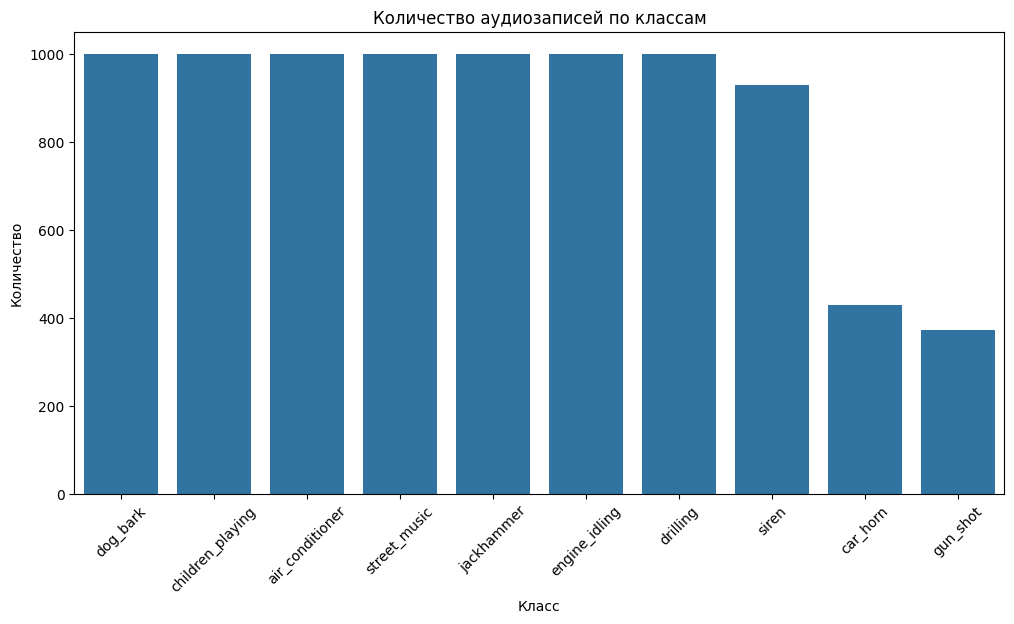

In [ ]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x='class',
    order=class_counts.index
)

plt.xticks(rotation=45)
plt.title('Количество аудиозаписей по классам')
plt.xlabel('Класс')
plt.ylabel('Количество')

plt.show()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8732 entries, 0 to 8731
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   slice_file_name  8732 non-null   object 
 1   fsID             8732 non-null   int64  
 2   start            8732 non-null   float64
 3   end              8732 non-null   float64
 4   salience         8732 non-null   int64  
 5   fold             8732 non-null   int64  
 6   classID          8732 non-null   int64  
 7   class            8732 non-null   object 
dtypes: float64(2), int64(4), object(2)
memory usage: 545.9+ KB


In [ ]:
df.describe()

,fsID,start,end,salience,fold,classID
count,8732.000000,8732.000000,8732.000000,8732.000000,8732.000000,8732.000000
mean,116033.493816,38.645409,42.253312,1.347000,5.385937,4.592877
std,57991.017218,74.292126,74.369669,0.476043,2.846820,2.894544
min,344.000000,0.000000,0.105962,1.000000,1.000000,0.000000
25%,69942.250000,3.000000,6.839398,1.000000,3.000000,2.000000
50%,118279.000000,10.376492,14.000000,1.000000,5.000000,4.000000
75%,166942.000000,35.131372,38.866979,2.000000,8.000000,7.000000
max,209992.000000,600.125356,604.125356,2.000000,10.000000,9.000000


In [ ]:
df.isna().sum()

,0
slice_file_name,0
fsID,0
start,0
end,0
salience,0
fold,0
classID,0
class,0


In [ ]:
print('Количество дубликатов:', df.duplicated().sum())

Количество дубликатов: 0


In [ ]:
# Проверяем распределение по folds
fold_counts = df['fold'].value_counts().sort_index()
print(fold_counts)

fold
1     873
2     888
3     925
4     990
5     936
6     823
7     838
8     806
9     816
10    837
Name: count, dtype: int64


<function matplotlib.pyplot.show(close=None, block=None)>

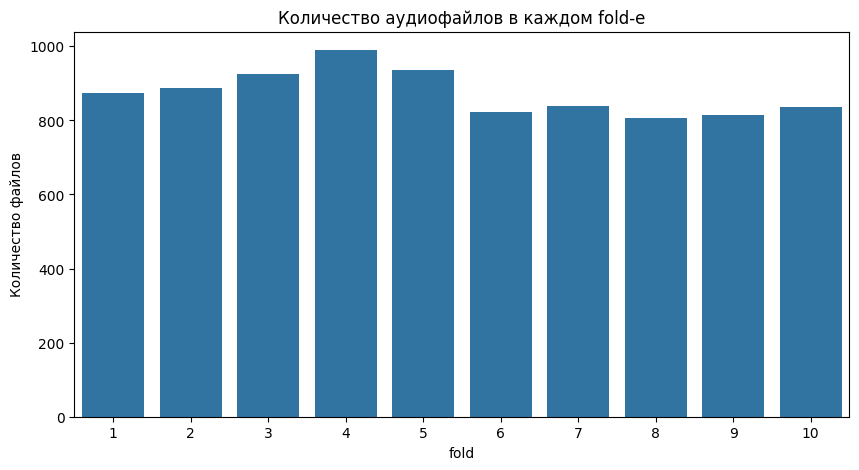

In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(
    x = fold_counts.index,
    y = fold_counts.values
)

plt.title('Количество аудиофайлов в каждом fold-e')
plt.xlabel('fold')
plt.ylabel('Количество файлов')
plt.show

In [ ]:
# Проверяем, что все 10 folds присутствуют
print(
    sorted(df['fold'].unique())
)

[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]


In [ ]:
# Находим все WAV-файлы
wav_files = []

for root, dirs, files in os.walk(audio_path):

    for file in files:

        if file.lower().endswith('.wav'):
            wav_files.append(
                os.path.join(root, file)
            )

print(
    'Количество WAV-файлов:',
    len(wav_files)
)

print('Размер датасета:', df.shape)

Количество WAV-файлов: 8732
Размер датасета: (8732, 8)


In [ ]:
# Создаём множество названий файлов
wav_names = {
    os.path.basename(path)
    for path in wav_files
}

In [ ]:
df['file_exists'] = (
    df['slice_file_name']
    .isin(wav_names)
)
df['file_exists'].value_counts()
# Для каждой записи в CSV существует соответствующий .wav

,count
file_exists,
True,8732


In [ ]:
# Создаём пути к файлам
file_to_path = {
    os.path.basename(path): path
    for path in wav_files
}

In [ ]:
df['filepath'] = df['slice_file_name'].map(
    file_to_path
)

In [ ]:
print(
    df['filepath'].isna().sum()
)

0


все 8732 аудиофайла найдены

In [ ]:
# Проверяем соответствие fold и пути
df[['slice_file_name', 'fold', 'filepath']].head(20)

,slice_file_name,fold,filepath
0,100032-3-0-0.wav,5,/content/UrbanSound8K_audio/100032-3-0-0.wav
1,100263-2-0-117.wav,5,/content/UrbanSound8K_audio/100263-2-0-117.wav
2,100263-2-0-121.wav,5,/content/UrbanSound8K_audio/100263-2-0-121.wav
3,100263-2-0-126.wav,5,/content/UrbanSound8K_audio/100263-2-0-126.wav
4,100263-2-0-137.wav,5,/content/UrbanSound8K_audio/100263-2-0-137.wav
5,100263-2-0-143.wav,5,/content/UrbanSound8K_audio/100263-2-0-143.wav
6,100263-2-0-161.wav,5,/content/UrbanSound8K_audio/100263-2-0-161.wav
7,100263-2-0-3.wav,5,/content/UrbanSound8K_audio/100263-2-0-3.wav
8,100263-2-0-36.wav,5,/content/UrbanSound8K_audio/100263-2-0-36.wav
9,100648-1-0-0.wav,10,/content/UrbanSound8K_audio/100648-1-0-0.wav


In [ ]:
# Сохраняем подготовленный DataFrame
df.to_csv('/content/UrbanSound8K_prepared.csv', index=False)

# 2. Загрузка и визуализация аудио сигналов

In [ ]:
# Берём один аудиофайл
sample = df.iloc[0]
sample

,0
slice_file_name,100032-3-0-0.wav
fsID,100032
start,0.0
end,0.317551
salience,1
fold,5
classID,3
class,dog_bark
file_exists,True
filepath,/content/UrbanSound8K_audio/100032-3-0-0.wav


In [ ]:
print('Файл: ', sample['filepath'])
print('Класс: ', sample['class'])

Файл:  /content/UrbanSound8K_audio/100032-3-0-0.wav
Класс:  dog_bark


In [ ]:
# Загружаем аудио
audio, sr = librosa.load(sample['filepath'], sr=None)

print('Sample rate:', sr)
print('Количество отсчётов:', len(audio))

Sample rate: 44100
Количество отсчётов: 14004


In [ ]:
# Определяем длительность
duration = len(audio) / sr
print('Длительность:', duration, 'сек.')

Длительность: 0.31755102040816324 сек.


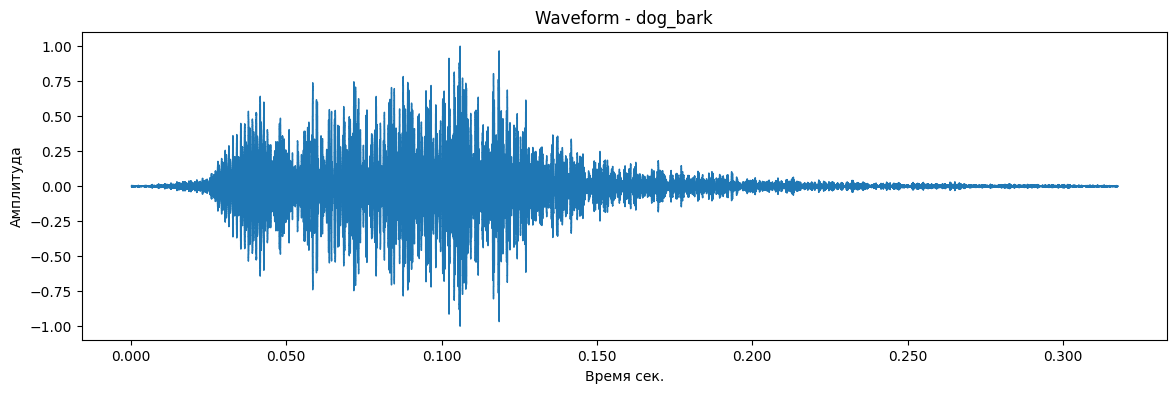

In [ ]:
# Визуализируем waveform
plt.figure(figsize=(14, 4))
librosa.display.waveshow(audio, sr=sr)
plt.title(f'Waveform - {sample['class']}')
plt.xlabel('Время сек.')
plt.ylabel('Амплитуда')
plt.show()

In [ ]:
# Смотрим минимальную и максимальную амплитуду
print('Минимальная амплитуда:', audio.min())
print('Максимальная амплитуда:', audio.max())

Минимальная амплитуда: -0.96687317
Максимальная амплитуда: 0.9999695


In [ ]:
print(f'Форма массива: {audio.shape}')
print(audio[:20])

Форма массива: (14004,)
[-0.00454712 -0.00483704 -0.00460815 -0.00468445 -0.00488281 -0.00497437
 -0.00483704 -0.00445557 -0.00401306 -0.00323486 -0.00228882 -0.00123596
 -0.00016785  0.00016785  0.00170898  0.00227356  0.00312805  0.00350952
  0.00436401  0.00460815]


In [ ]:
# Получим спектр, используя Fast Fourier Transform (FFT)
fft = np.fft.fft(audio)
magnitude = np.abs(fft)

In [ ]:
# нужна только половина спектра
freqs = np.fft.fftfreq(len(audio), 1 / sr)
mask = freqs >= 0
freqs = freqs[mask]
magnitude = magnitude[mask]

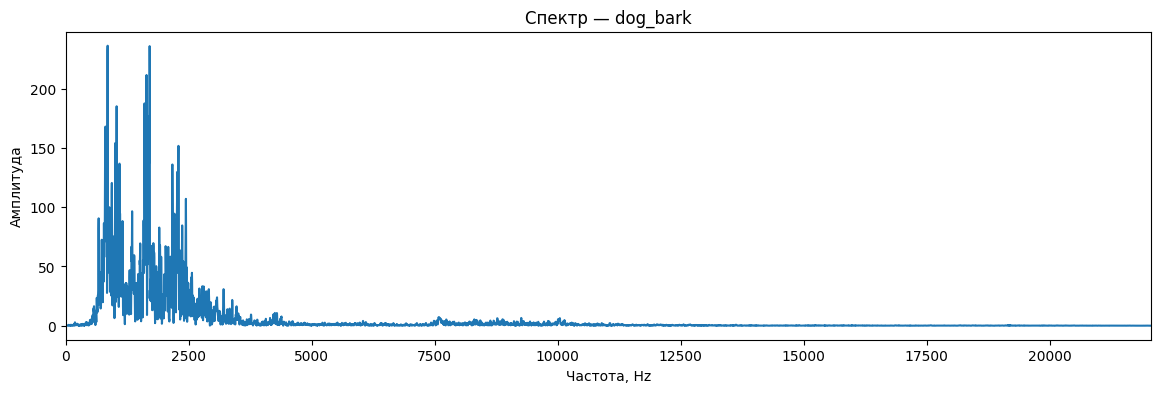

In [ ]:
# построим график
plt.figure(figsize=(14, 4))
plt.plot(freqs, magnitude)
plt.title(f'Спектр — {sample["class"]}')
plt.xlabel('Частота, Hz')
plt.ylabel('Амплитуда')
plt.xlim(0, sr / 2)
plt.show()

In [ ]:
# Чтобы получить (частота + время) нужно строить спектрограмму с помощью STFT — Short-Time Fourier Transform
D = librosa.stft(audio)

In [ ]:
# Переводим спектрограмму в амплитуды (Db)
D_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

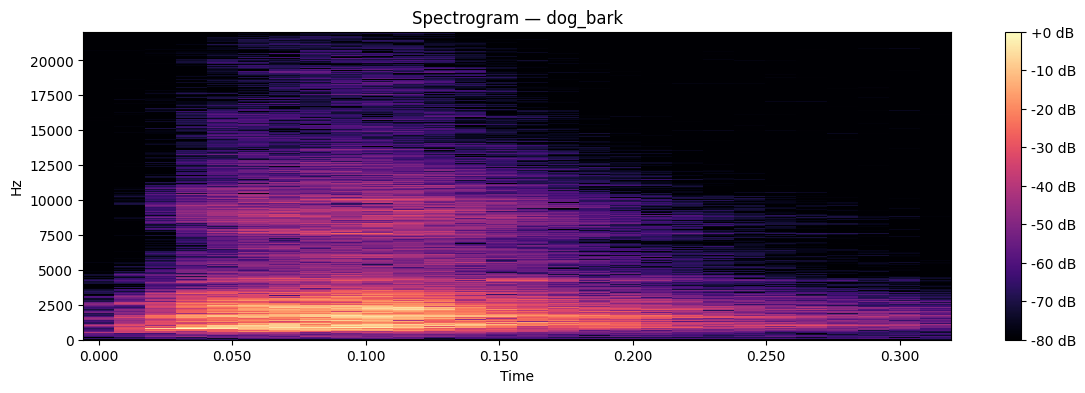

In [ ]:
# Рисуем спектрограмму
plt.figure(figsize=(14, 4))
librosa.display.specshow(D_db, sr=sr, x_axis='time', y_axis='hz')
plt.colorbar(format='%+2.0f dB')
plt.title(f'Spectrogram — {sample["class"]}')
plt.show()

In [ ]:
# Для человеческого уха создаём Mel-spectrogram
mel = librosa.feature.melspectrogram(y=audio, sr=sr, n_mels=128)
mel_db = librosa.power_to_db(mel, ref=np.max)

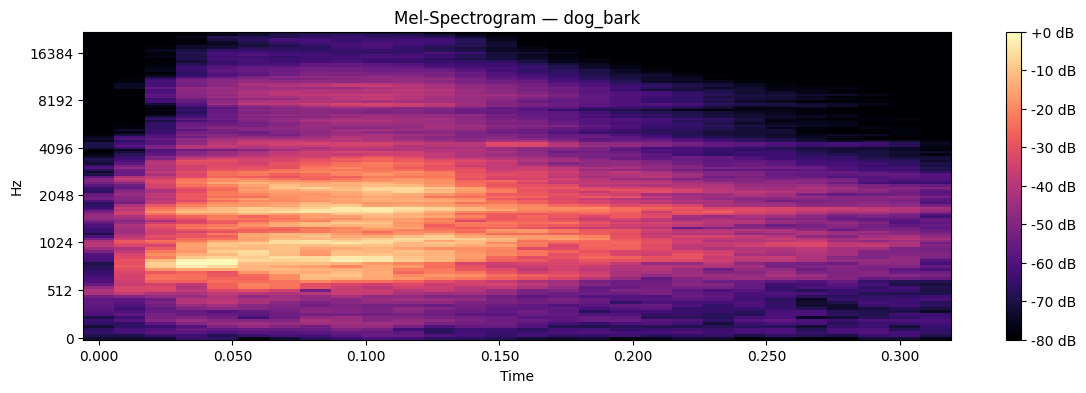

In [ ]:
plt.figure(figsize=(14, 4))
librosa.display.specshow(mel_db, sr=sr, x_axis='time', y_axis='mel')
plt.colorbar(format='%+2.0f dB')
plt.title(f'Mel-Spectrogram — {sample["class"]}')
plt.show()

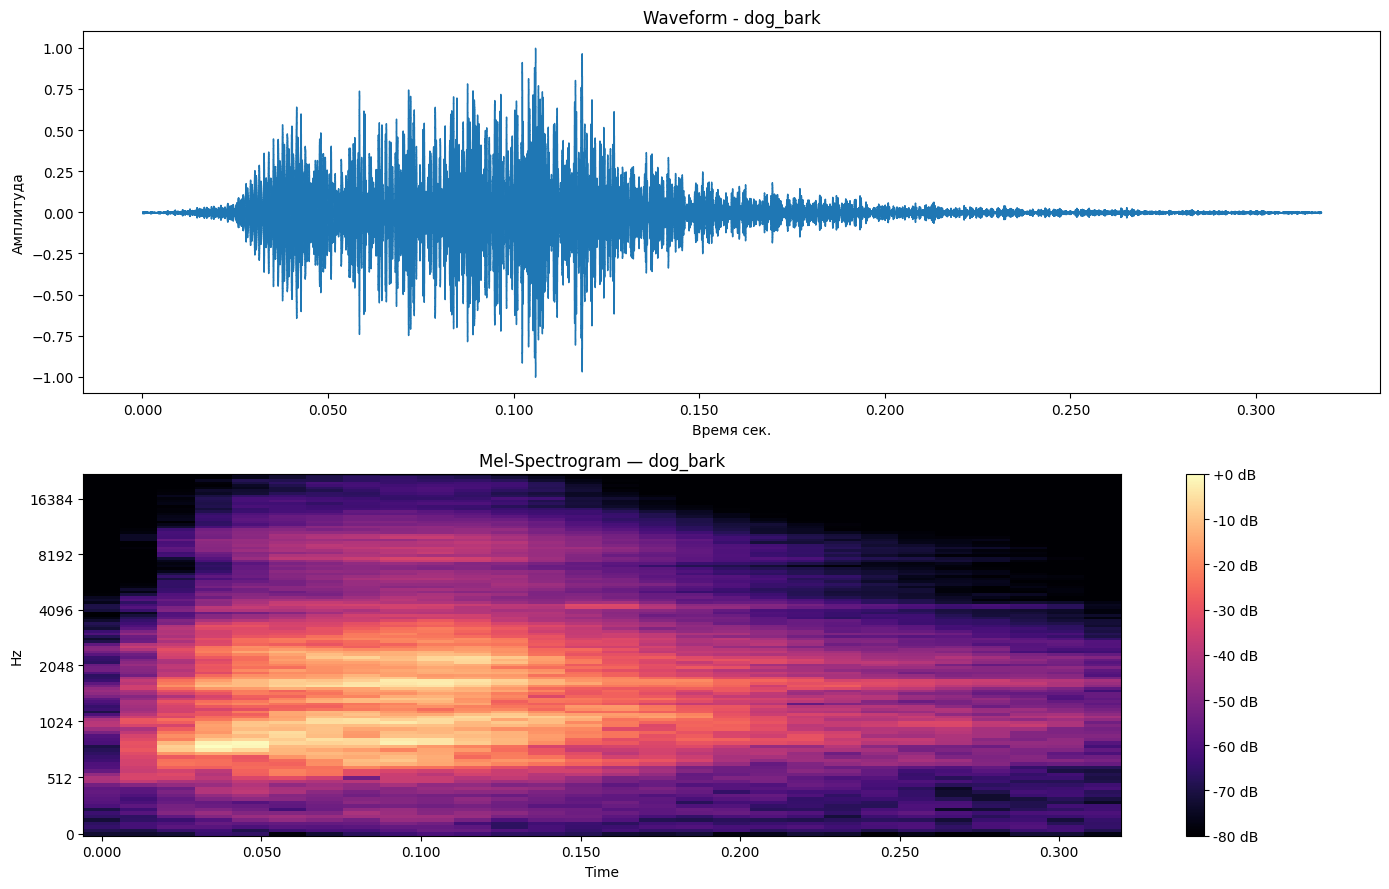

In [ ]:
# Сравним waveform и Mel-spectrogram
fig, axes = plt.subplots(2, 1, figsize=(14,9))

librosa.display.waveshow(audio, sr=sr, ax=axes[0])
axes[0].set_title(f'Waveform - {sample['class']}')
axes[0].set_xlabel('Время сек.')
axes[0].set_ylabel('Амплитуда')

img = librosa.display.specshow(mel_db, sr=sr, x_axis='time', y_axis='mel', ax=axes[1])
axes[1].set_title(f'Mel-Spectrogram — {sample["class"]}')
fig.colorbar(img, ax=axes[1], format='%+2.0f dB')
plt.tight_layout()
plt.show()

In [ ]:
# Посмотрим несколько разных классов
# Создадим функцию
def show_audio_example(df, index):

    row = df.iloc[index]
    audio, sr = librosa.load(row['filepath'], sr=None)
    mel = librosa.feature.melspectrogram(y=audio, sr=sr, n_mels=128)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    fig, axes = plt.subplots(2, 1, figsize=(14, 8)    )

    # Waveform
    librosa.display.waveshow(audio, sr=sr, ax=axes[0])
    axes[0].set_title(f"Waveform — {row['class']}")

    # Mel
    img = librosa.display.specshow(mel_db, sr=sr, x_axis='time', y_axis='mel', ax=axes[1])
    axes[1].set_title(f"Mel-Spectrogram — {row['class']}")
    fig.colorbar(img, ax=axes[1], format='%+2.0f dB')

    plt.tight_layout()
    plt.show()

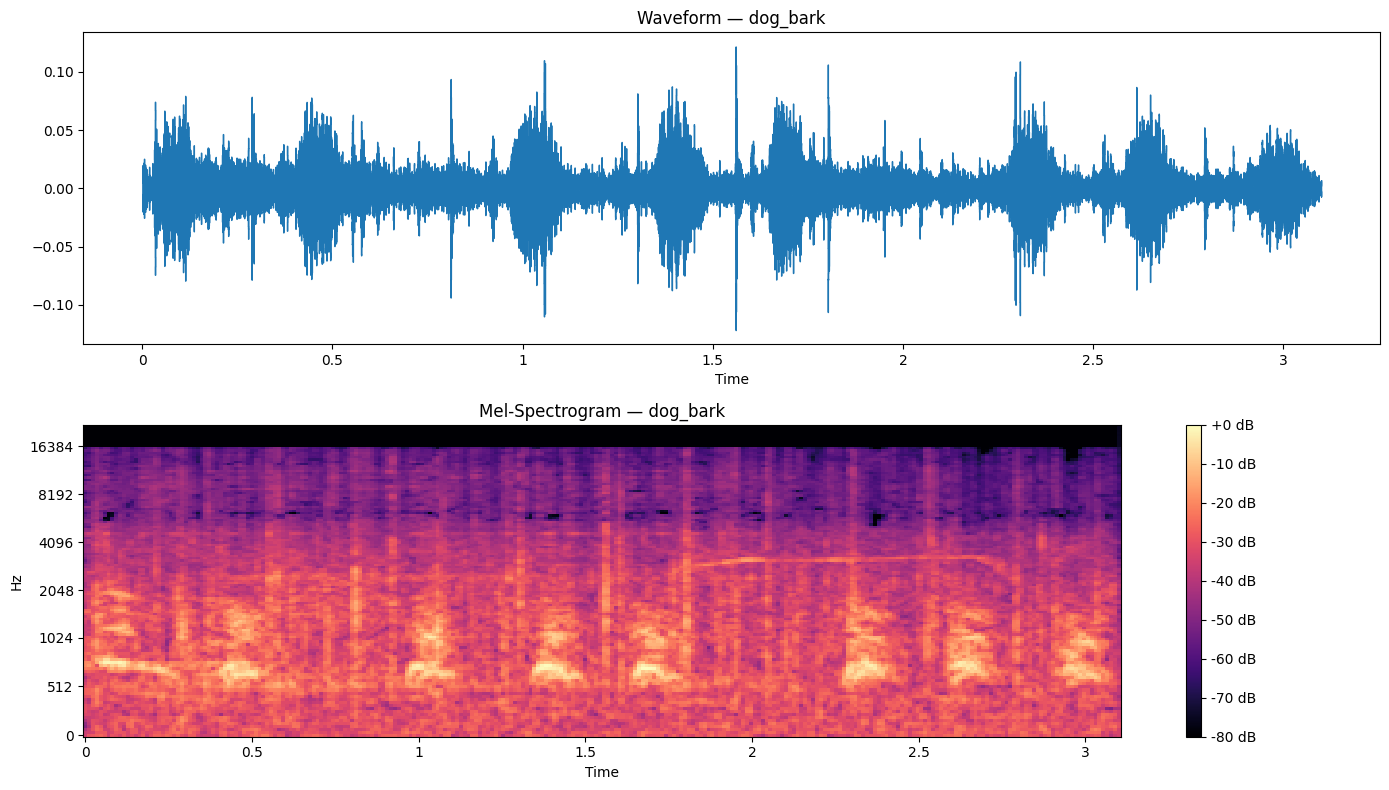

In [ ]:
show_audio_example(df, 100)

# 3. Извлечение признаков из аудиосигналов
  
  Превратим аудиофайлы .wav в обычную таблицу числовых признаков

**Используем несколько групп характеристик:**

MFCC	            - Характеристики тембра звука

Chroma	          - Распределение энергии по 12 музыкальным нотам

Spectral Centroid	- «Центр тяжести» спектра

Spectral Bandwidth - Ширина распределения частот

Spectral Rolloff	- Частота, ниже которой находится большая часть энергии

Zero Crossing Rate - Как часто сигнал меняет знак

RMS Energy	      - Средняя энергия сигнала

Для каждого признака будем вычислять статистику по времени:

среднее значение;
стандартное отклонение.

In [ ]:
# Создадим функцию загрузки аудиосигнала
def load_audio(filepath):
  audio, sr = librosa.load(filepath, sr=None, mono=True)
  return audio, sr

In [ ]:
# Функции извлечения признаков
def extract_features(filepath):

    # 1. Загружаем аудио
    audio, sr = load_audio(filepath)
    features = {}

    # 2. MFCC
    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=13
    )

    for i in range(mfcc.shape[0]):

        features[f'mfcc_{i+1}_mean'] = np.mean(mfcc[i])
        features[f'mfcc_{i+1}_std'] = np.std(mfcc[i])

    # 3. Chroma
    chroma = librosa.feature.chroma_stft(y=audio, sr=sr)

    for i in range(chroma.shape[0]):

        features[f'chroma_{i+1}_mean'] = np.mean(chroma[i])
        features[f'chroma_{i+1}_std'] = np.std(chroma[i])

    # 4. Spectral Centroid

    spectral_centroid = librosa.feature.spectral_centroid(y=audio, sr=sr)
    features['spectral_centroid_mean'] = np.mean(spectral_centroid)
    features['spectral_centroid_std'] = np.std(spectral_centroid)

    # 5. Spectral Bandwidth

    spectral_bandwidth = librosa.feature.spectral_bandwidth(
        y=audio,
        sr=sr
    )

    features['spectral_bandwidth_mean'] = np.mean(
        spectral_bandwidth
    )

    features['spectral_bandwidth_std'] = np.std(
        spectral_bandwidth
    )

    # 6. Spectral Rolloff

    spectral_rolloff = librosa.feature.spectral_rolloff(
        y=audio,
        sr=sr
    )

    features['spectral_rolloff_mean'] = np.mean(
        spectral_rolloff
    )

    features['spectral_rolloff_std'] = np.std(
        spectral_rolloff
    )

    # 7. Zero Crossing Rate

    zero_crossing_rate = librosa.feature.zero_crossing_rate(
        y=audio
    )

    features['zero_crossing_rate_mean'] = np.mean(
        zero_crossing_rate
    )

    features['zero_crossing_rate_std'] = np.std(
        zero_crossing_rate
    )

    # 8. RMS Energy

    rms = librosa.feature.rms(y=audio)
    features['rms_mean'] = np.mean(rms)
    features['rms_std'] = np.std(rms)

    return features

In [ ]:
# Например MFCC посмотрим
mfcc = librosa.feature.mfcc(
    y=audio,
    sr=sr,
    n_mfcc=13
)
print(f'MFCC-признаков: {mfcc.shape[0]}')
print(f'временных кадра: {mfcc.shape[1]}')

MFCC-признаков: 13
временных кадра: 28


In [ ]:
# Проверяем функцию на одном аудио
example_filepath = df.iloc[0]['filepath']
example_features = extract_features(example_filepath)
example_features_df = pd.DataFrame([example_features])
example_features_df.T

,0
mfcc_1_mean,-275.918427
mfcc_1_std,130.087769
mfcc_2_mean,119.492790
mfcc_2_std,14.965517
mfcc_3_mean,-98.211777
mfcc_3_std,32.176846
mfcc_4_mean,-66.515129
mfcc_4_std,7.711866
mfcc_5_mean,-42.606045
mfcc_5_std,20.805025


In [ ]:
print('Количество признаков:', len(example_features))

Количество признаков: 60


In [ ]:
# Извлекаем признаки для всех аудиофайлов

feature_rows = []
valid_indices = []

for index, filepath in tqdm(
    df['filepath'].items(),
    desc='Извлечение признаков'
):

    try:

        features = extract_features(filepath)

        feature_rows.append(features)
        valid_indices.append(index)

    except Exception as error:

        print(f'Ошибка в файле: {filepath}')
        print(error)

Извлечение признаков: 0it [00:00, ?it/s]

In [ ]:
# Создаём таблицу признаков
features_df = pd.DataFrame(
    feature_rows,
    index=valid_indices
)

In [ ]:
# И объединяем с метаданными
data_features = df.loc[
    valid_indices,
    [
        'slice_file_name',
        'fold',
        'classID',
        'class',
        'filepath'
    ]
].copy()

In [ ]:
# Добавляем признаки:
data_features = pd.concat([data_features, features_df], axis=1)
data_features.head()

,slice_file_name,fold,classID,class,filepath,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,...,spectral_centroid_mean,spectral_centroid_std,spectral_bandwidth_mean,spectral_bandwidth_std,spectral_rolloff_mean,spectral_rolloff_std,zero_crossing_rate_mean,zero_crossing_rate_std,rms_mean,rms_std
0,100032-3-0-0.wav,5,3,dog_bark,/content/UrbanSound8K_audio/100032-3-0-0.wav,-275.918427,130.087769,119.492790,14.965517,-98.211777,...,2501.385834,322.217164,2850.927603,626.450406,3253.051758,485.570101,0.066302,0.012149,0.115351,0.114443
1,100263-2-0-117.wav,5,2,children_playing,/content/UrbanSound8K_audio/100263-2-0-117.wav,-500.908386,22.012791,185.106415,11.297286,-86.532822,...,2232.577799,279.239437,2284.091602,280.173239,4081.696671,355.405658,0.071667,0.020666,0.003983,0.001132
2,100263-2-0-121.wav,5,2,children_playing,/content/UrbanSound8K_audio/100263-2-0-121.wav,-531.195312,12.762764,186.939941,8.001002,-70.349159,...,1956.527004,207.627439,2327.294853,195.100132,3768.060887,314.119076,0.052590,0.014701,0.003000,0.000636
3,100263-2-0-126.wav,5,2,children_playing,/content/UrbanSound8K_audio/100263-2-0-126.wav,-476.784424,26.047169,160.333282,17.871094,-62.952843,...,2652.462734,723.266892,2929.146794,524.423948,4979.787279,1635.620026,0.072764,0.032739,0.004612,0.001912
4,100263-2-0-137.wav,5,2,children_playing,/content/UrbanSound8K_audio/100263-2-0-137.wav,-521.244690,12.964274,185.392654,7.281819,-81.950478,...,2095.392609,182.375477,2288.749922,158.145375,3966.291185,204.347644,0.060884,0.015910,0.003215,0.000539


In [ ]:
# Проверяем пропуски
data_features.isna().sum().sum()

np.int64(0)

In [ ]:
# Проверяем NaN только в числовых признаках
numeric_columns = data_features.select_dtypes(include=np.number).columns

print('NaN:', data_features[numeric_columns].isna().sum().sum())

print('Inf:', np.isinf(data_features[numeric_columns].to_numpy()).sum())

NaN: 0
Inf: 0


In [ ]:
# Проверяем бесконечности
print('Inf:', np.isinf(data_features[numeric_columns].to_numpy()).sum())

Inf: 0


In [ ]:
# Сохраняем результат
data_features.to_csv('/content/UrbanSound8K_features.csv', index=False)

In [ ]:
# Загружаем
data_features = pd.read_csv('/content/UrbanSound8K_features.csv')

# 4. Классические ML-модели

In [ ]:
# отделяем X и y
drop_columns = [
    'slice_file_name',
    'fold',
    'classID',
    'class',
    'filepath'
]

X = data_features.drop(columns=drop_columns)
y = data_features['classID']

print('X:', X.shape)
print('y:', y.shape)

X: (8732, 60)
y: (8732,)


In [ ]:
# Список моделей
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000,random_state=42),

    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),

    'SVM': SVC(kernel='rbf', C=10, random_state=42)
}

In [ ]:
# Создаем структуру для результатов
cv_results = []

all_predictions = {
    'Logistic Regression': [],
    'Random Forest': [],
    'SVM': []
}

all_targets = []

In [ ]:
# 10-fold Cross-Validation
for test_fold in tqdm(range(1, 11)):

    print()
    print('=' * 70)
    print(f'FOLD {test_fold}/10')
    print('=' * 70)

    # ---------------------------------------
    # Формируем TRAIN и TEST
    # ---------------------------------------

    train_mask = (data_features['fold'] != test_fold
    )

    test_mask = (
        data_features['fold'] == test_fold
    )

    X_train = X.loc[train_mask]
    y_train = y.loc[train_mask]

    X_test = X.loc[test_mask]
    y_test = y.loc[test_mask]

    print('Train:', X_train.shape)

    print('Test:', X_test.shape)

    # ---------------------------------------
    # STANDARD SCALER
    # ---------------------------------------

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train)

    X_test_scaled = scaler.transform(X_test)

    # ---------------------------------------
    # СОХРАНЯЕМ TARGET
    # ---------------------------------------

    all_targets.extend(y_test.to_numpy())

    # ---------------------------------------
    # LOGISTIC REGRESSION
    # ---------------------------------------

    logreg = LogisticRegression(max_iter=1000, random_state=42)

    logreg.fit(X_train_scaled, y_train)

    y_pred_logreg = logreg.predict(X_test_scaled)

    logreg_accuracy = accuracy_score(y_test, y_pred_logreg)

    logreg_f1 = f1_score(y_test, y_pred_logreg, average='macro')

    logreg_mcc = matthews_corrcoef(y_test, y_pred_logreg)

    all_predictions['Logistic Regression'].extend(y_pred_logreg)

    cv_results.append({
        'fold': test_fold,
        'model': 'Logistic Regression',
        'accuracy': logreg_accuracy,
        'f1_macro': logreg_f1,
        'mcc': logreg_mcc
    })

    # ---------------------------------------
    # RANDOM FOREST
    # ---------------------------------------

    rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)

    rf.fit(X_train, y_train)

    y_pred_rf = rf.predict(X_test)

    rf_accuracy = accuracy_score(y_test, y_pred_rf)

    rf_f1 = f1_score(y_test, y_pred_rf, average='macro')

    rf_mcc = matthews_corrcoef(y_test, y_pred_rf)

    all_predictions['Random Forest'].extend(y_pred_rf)

    cv_results.append({
        'fold': test_fold,
        'model': 'Random Forest',
        'accuracy': rf_accuracy,
        'f1_macro': rf_f1,
        'mcc': rf_mcc
    })

    # ---------------------------------------
    # SVM
    # ---------------------------------------

    svm = SVC(kernel='rbf', C=10, random_state=42)

    svm.fit(X_train_scaled, y_train)

    y_pred_svm = svm.predict(X_test_scaled)

    svm_accuracy = accuracy_score(y_test, y_pred_svm)

    svm_f1 = f1_score(y_test, y_pred_svm, average='macro')

    svm_mcc = matthews_corrcoef(y_test, y_pred_svm)

    all_predictions['SVM'].extend(y_pred_svm)

    cv_results.append({
        'fold': test_fold,
        'model': 'SVM',
        'accuracy': svm_accuracy,
        'f1_macro': svm_f1,
        'mcc': svm_mcc
    })

    # ---------------------------------------
    # РЕЗУЛЬТАТЫ FOLD
    # ---------------------------------------

    print()
    print('Logistic Regression:')
    print(f'  Accuracy = {logreg_accuracy:.4f}')
    print(f'  F1 Macro = {logreg_f1:.4f}')
    print(f'  MCC      = {logreg_mcc:.4f}')

    print()
    print('Random Forest:')
    print(f'  Accuracy = {rf_accuracy:.4f}')
    print(f'  F1 Macro = {rf_f1:.4f}')
    print(f'  MCC      = {rf_mcc:.4f}')

    print()
    print('SVM:')
    print(f'  Accuracy = {svm_accuracy:.4f}')
    print(f'  F1 Macro = {svm_f1:.4f}')
    print(f'  MCC      = {svm_mcc:.4f}')

  0%|          | 0/10 [00:00<?, ?it/s]


FOLD 1/10
Train: (7859, 60)
Test: (873, 60)

Logistic Regression:
  Accuracy = 0.6701
  F1 Macro = 0.6735
  MCC      = 0.6334

Random Forest:
  Accuracy = 0.6529
  F1 Macro = 0.6810
  MCC      = 0.6153

SVM:
  Accuracy = 0.6449
  F1 Macro = 0.6671
  MCC      = 0.6098

FOLD 2/10
Train: (7844, 60)
Test: (888, 60)

Logistic Regression:
  Accuracy = 0.5721
  F1 Macro = 0.5688
  MCC      = 0.5246

Random Forest:
  Accuracy = 0.6745
  F1 Macro = 0.6763
  MCC      = 0.6393

SVM:
  Accuracy = 0.6160
  F1 Macro = 0.6064
  MCC      = 0.5738

FOLD 3/10
Train: (7807, 60)
Test: (925, 60)

Logistic Regression:
  Accuracy = 0.5459
  F1 Macro = 0.5583
  MCC      = 0.4944

Random Forest:
  Accuracy = 0.6227
  F1 Macro = 0.6377
  MCC      = 0.5793

SVM:
  Accuracy = 0.5654
  F1 Macro = 0.5751
  MCC      = 0.5192

FOLD 4/10
Train: (7742, 60)
Test: (990, 60)

Logistic Regression:
  Accuracy = 0.5980
  F1 Macro = 0.5951
  MCC      = 0.5496

Random Forest:
  Accuracy = 0.6535
  F1 Macro = 0.6500
  MCC     

In [ ]:
# Таблица результатов ML по fold
cv_results_df = pd.DataFrame(cv_results)
cv_results_df

,fold,model,accuracy,f1_macro,mcc
0,1,Logistic Regression,0.670103,0.673538,0.633401
1,1,Random Forest,0.652921,0.681014,0.615299
2,1,SVM,0.644903,0.667052,0.609839
3,2,Logistic Regression,0.572072,0.568791,0.524598
4,2,Random Forest,0.674550,0.676322,0.639302
5,2,SVM,0.615991,0.606395,0.573824
6,3,Logistic Regression,0.545946,0.558301,0.494354
7,3,Random Forest,0.622703,0.637662,0.579265
8,3,SVM,0.565405,0.575069,0.519165
9,4,Logistic Regression,0.597980,0.595069,0.549621


In [ ]:
# Средние результаты ML
summary_table = (
    cv_results_df
    .groupby('model')
    .agg(
        accuracy_mean=('accuracy', 'mean'),
        accuracy_std=('accuracy', 'std'),

        f1_mean=('f1_macro', 'mean'),
        f1_std=('f1_macro', 'std'),

        mcc_mean=('mcc', 'mean'),
        mcc_std=('mcc', 'std')
    )
    .reset_index()
)

summary_table

,model,accuracy_mean,accuracy_std,f1_mean,f1_std,mcc_mean,mcc_std
0,Logistic Regression,0.624568,0.050702,0.635130,0.053534,0.580887,0.056697
1,Random Forest,0.661271,0.021162,0.669130,0.022771,0.622799,0.024191
2,SVM,0.658580,0.058675,0.666682,0.062545,0.620192,0.064850


In [ ]:
# Выводим результаты в формате mean ± std
for _, row in summary_table.iterrows():

    print()
    print(row['model'])

    print(
        f"Accuracy: "
        f"{row['accuracy_mean']:.4f} "
        f"± {row['accuracy_std']:.4f}"
    )

    print(
        f"F1 Macro: "
        f"{row['f1_mean']:.4f} "
        f"± {row['f1_std']:.4f}"
    )

    print(
        f"MCC: "
        f"{row['mcc_mean']:.4f} "
        f"± {row['mcc_std']:.4f}"
    )


Logistic Regression
Accuracy: 0.6246 ± 0.0507
F1 Macro: 0.6351 ± 0.0535
MCC: 0.5809 ± 0.0567

Random Forest
Accuracy: 0.6613 ± 0.0212
F1 Macro: 0.6691 ± 0.0228
MCC: 0.6228 ± 0.0242

SVM
Accuracy: 0.6586 ± 0.0587
F1 Macro: 0.6667 ± 0.0625
MCC: 0.6202 ± 0.0648


In [ ]:
class_names = [
    'air_conditioner',
    'car_horn',
    'children_playing',
    'dog_bark',
    'drilling',
    'engine_idling',
    'gun_shot',
    'jackhammer',
    'siren',
    'street_music'
]

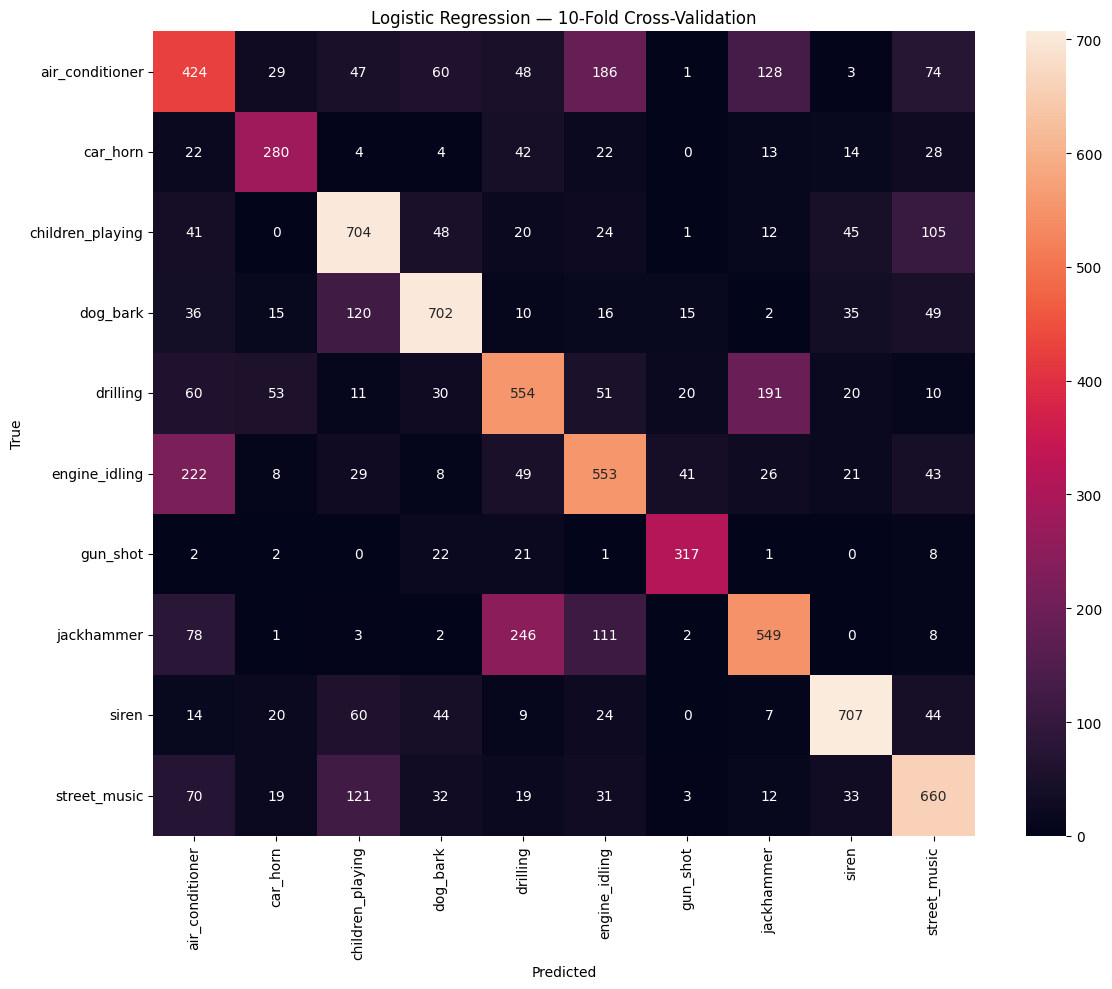

In [ ]:
# Confusion Matrix для 'Logistic Regression'
y_true_all = np.array(all_targets)

y_pred_lr_all = np.array(all_predictions['Logistic Regression'])

cm_lr = confusion_matrix(y_true_all, y_pred_lr_all)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Logistic Regression — 10-Fold Cross-Validation')
plt.tight_layout()
plt.show()

In [ ]:
# Classification Report Logistic Regression
print(
    classification_report(
        y_true_all,
        y_pred_lr_all,
        target_names=class_names
    )
)

                  precision    recall  f1-score   support

 air_conditioner       0.44      0.42      0.43      1000
        car_horn       0.66      0.65      0.65       429
children_playing       0.64      0.70      0.67      1000
        dog_bark       0.74      0.70      0.72      1000
        drilling       0.54      0.55      0.55      1000
   engine_idling       0.54      0.55      0.55      1000
        gun_shot       0.79      0.85      0.82       374
      jackhammer       0.58      0.55      0.57      1000
           siren       0.81      0.76      0.78       929
    street_music       0.64      0.66      0.65      1000

        accuracy                           0.62      8732
       macro avg       0.64      0.64      0.64      8732
    weighted avg       0.62      0.62      0.62      8732



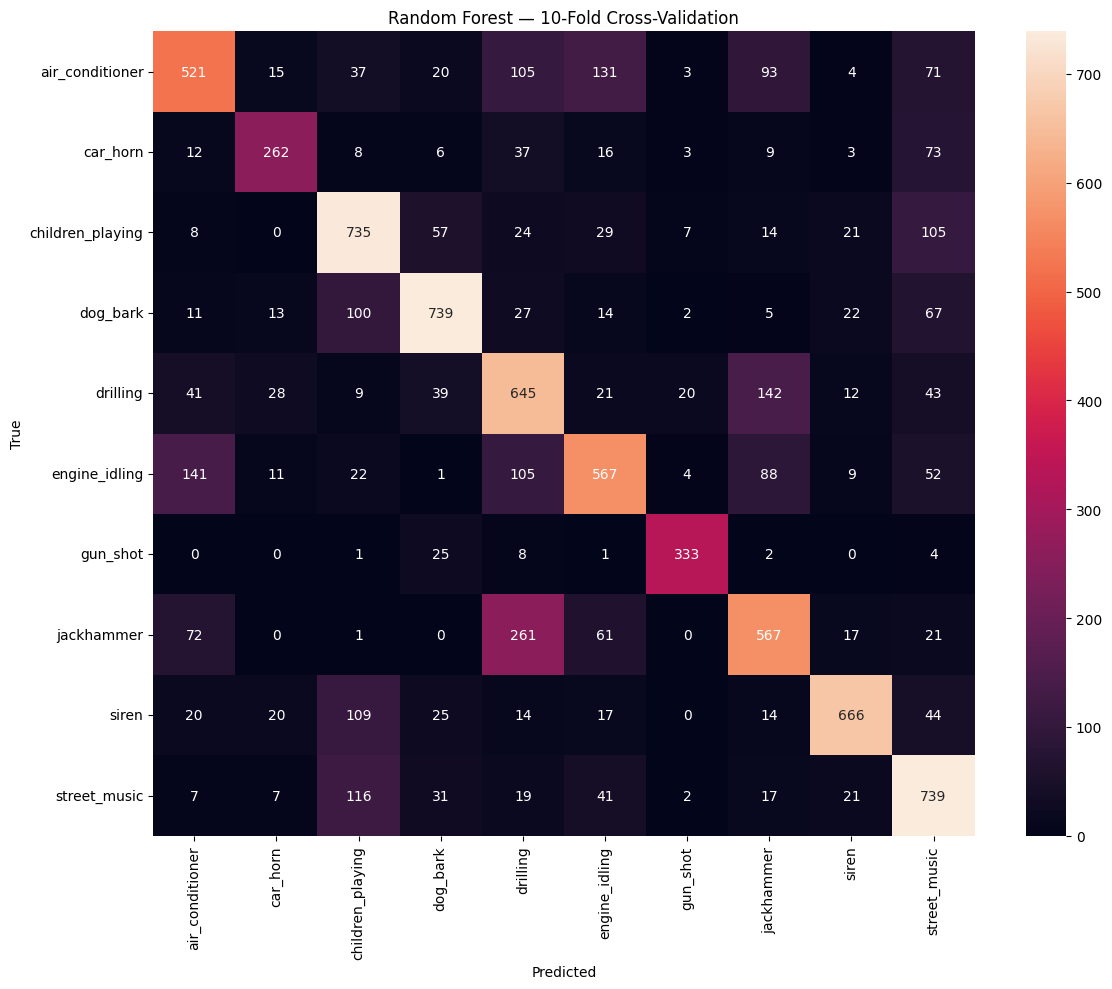

In [ ]:
# Confusion Matrix для 'Random Forest'
y_true_all = np.array(all_targets)

y_pred_rf_all = np.array(all_predictions['Random Forest'])

cm_rf = confusion_matrix(y_true_all, y_pred_rf_all)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Random Forest — 10-Fold Cross-Validation')
plt.tight_layout()
plt.show()

In [ ]:
# Classification Report Random Forest
print(
    classification_report(
        y_true_all,
        y_pred_rf_all,
        target_names=class_names
    )
)

                  precision    recall  f1-score   support

 air_conditioner       0.63      0.52      0.57      1000
        car_horn       0.74      0.61      0.67       429
children_playing       0.65      0.73      0.69      1000
        dog_bark       0.78      0.74      0.76      1000
        drilling       0.52      0.65      0.57      1000
   engine_idling       0.63      0.57      0.60      1000
        gun_shot       0.89      0.89      0.89       374
      jackhammer       0.60      0.57      0.58      1000
           siren       0.86      0.72      0.78       929
    street_music       0.61      0.74      0.67      1000

        accuracy                           0.66      8732
       macro avg       0.69      0.67      0.68      8732
    weighted avg       0.67      0.66      0.66      8732



In [ ]:
# Сохраняем Classification Report Random Forest
class_rep_ml = classification_report(
    y_true_all, y_pred_rf_all, target_names=class_names, output_dict=True
)

# Преобразуем в DataFrame и транспонируем для привычного вида
df_class_rep_ml = pd.DataFrame(class_rep_ml).transpose()

# Посмотрим на результат
print(df_class_rep_ml.reset_index().rename(columns={"index": "class"}))

               class  precision    recall  f1-score      support
0    air_conditioner   0.625450  0.521000  0.568467  1000.000000
1           car_horn   0.735955  0.610723  0.667516   429.000000
2   children_playing   0.645870  0.735000  0.687558  1000.000000
3           dog_bark   0.783669  0.739000  0.760679  1000.000000
4           drilling   0.518072  0.645000  0.574610  1000.000000
5      engine_idling   0.631403  0.567000  0.597471  1000.000000
6           gun_shot   0.890374  0.890374  0.890374   374.000000
7         jackhammer   0.596215  0.567000  0.581240  1000.000000
8              siren   0.859355  0.716900  0.781690   929.000000
9       street_music   0.606235  0.739000  0.666066  1000.000000
10          accuracy   0.661246  0.661246  0.661246     0.661246
11         macro avg   0.689260  0.673100  0.677567  8732.000000
12      weighted avg   0.670405  0.661246  0.662122  8732.000000


In [ ]:
# Сохраняем
df_class_rep_ml.reset_index().rename(columns={"index": "class"}).to_csv(
    '/content/df_class_rep_ml.csv',
    index=False
)

In [ ]:
# Загружаем
df_class_rep_ml = pd.read_csv('/content/df_class_rep_ml.csv').round(4)
df_class_rep_ml['support'] = df_class_rep_ml['support'].astype(int)
df_class_rep_ml

,class,precision,recall,f1-score,support
0,air_conditioner,0.6255,0.5210,0.5685,1000
1,car_horn,0.7360,0.6107,0.6675,429
2,children_playing,0.6459,0.7350,0.6876,1000
3,dog_bark,0.7837,0.7390,0.7607,1000
4,drilling,0.5181,0.6450,0.5746,1000
5,engine_idling,0.6314,0.5670,0.5975,1000
6,gun_shot,0.8904,0.8904,0.8904,374
7,jackhammer,0.5962,0.5670,0.5812,1000
8,siren,0.8594,0.7169,0.7817,929
9,street_music,0.6062,0.7390,0.6661,1000


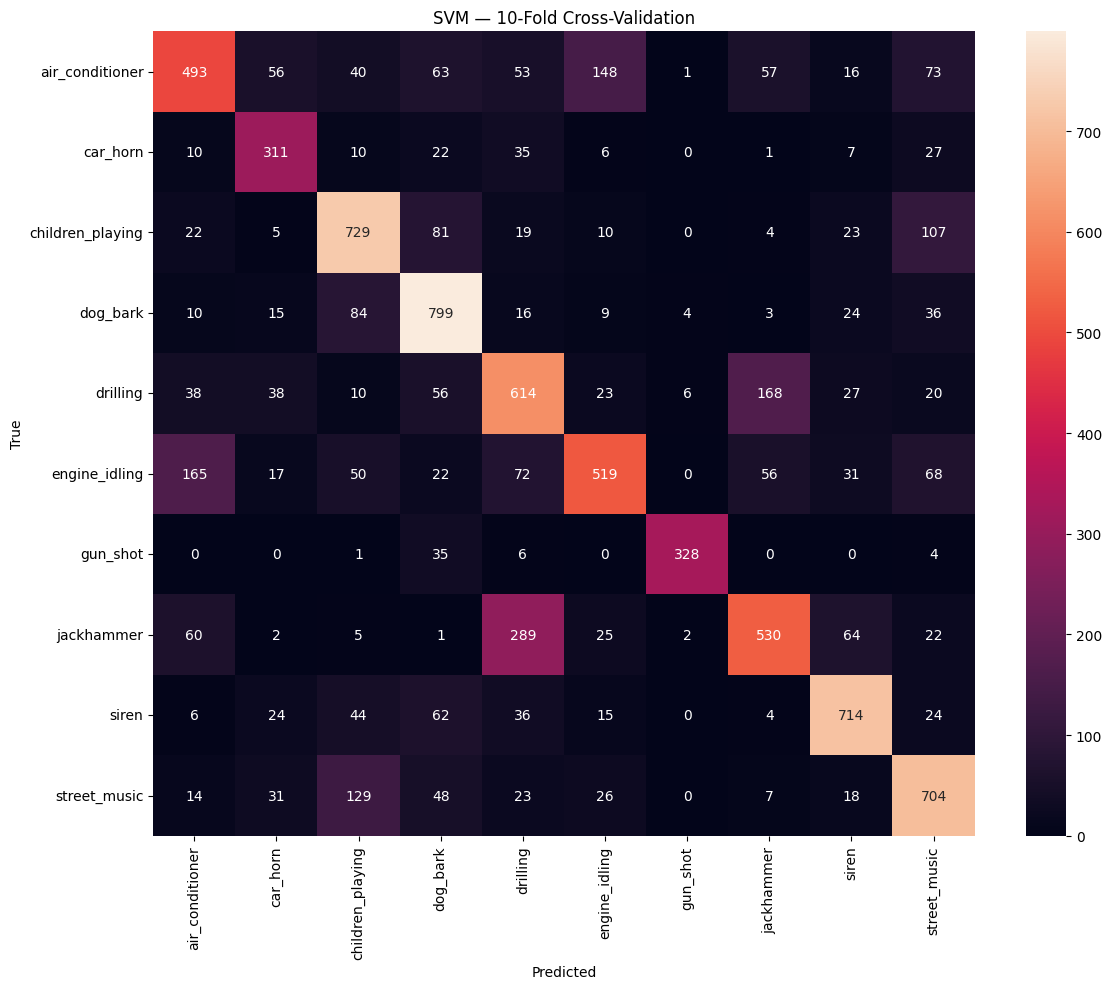

In [ ]:
# Confusion Matrix для 'SVM'
y_true_all = np.array(all_targets)

y_pred_svm_all = np.array(all_predictions['SVM'])

cm_svm = confusion_matrix(y_true_all, y_pred_svm_all)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('SVM — 10-Fold Cross-Validation')
plt.tight_layout()
plt.show()

In [ ]:
# Classification Report SVM
print(
    classification_report(
        y_true_all,
        y_pred_svm_all,
        target_names=class_names
    )
)

                  precision    recall  f1-score   support

 air_conditioner       0.60      0.49      0.54      1000
        car_horn       0.62      0.72      0.67       429
children_playing       0.66      0.73      0.69      1000
        dog_bark       0.67      0.80      0.73      1000
        drilling       0.53      0.61      0.57      1000
   engine_idling       0.66      0.52      0.58      1000
        gun_shot       0.96      0.88      0.92       374
      jackhammer       0.64      0.53      0.58      1000
           siren       0.77      0.77      0.77       929
    street_music       0.65      0.70      0.68      1000

        accuracy                           0.66      8732
       macro avg       0.68      0.68      0.67      8732
    weighted avg       0.66      0.66      0.65      8732



In [ ]:
# Сохраняем результаты
cv_results_df.to_csv(
    '/content/classical_ml_10fold_results.csv',
    index=False
)

summary_table.to_csv(
    '/content/df_grade_mean_ml.csv',
    index=False
)

In [ ]:
# Загружаем результаты по ML
df_grade_mean_ml = pd.read_csv('/content/df_grade_mean_ml.csv').round(4)
df_grade_mean_ml

,model,accuracy_mean,accuracy_std,f1_mean,f1_std,mcc_mean,mcc_std
0,Logistic Regression,0.6246,0.0507,0.6351,0.0535,0.5809,0.0567
1,Random Forest,0.6613,0.0212,0.6691,0.0228,0.6228,0.0242
2,SVM,0.6586,0.0587,0.6667,0.0625,0.6202,0.0648


В качестве baseline выбираем модель классического ML с наибольшим средним MCC по результатам 10-кратной cross-validation.

Это Random Forest ( MCC: 0.6228 ± 0.0242 )

# 5. Mel-spectrogram для CNN

Здесь мы уже не превращаем аудио в 60 агрегированных чисел, как для Random Forest/SVM. Мы сохраняем структуру звука во времени и по частотам, чтобы затем подать её в CNN

In [ ]:
# Загружаем наш подготовленный датафрейм
data_features = pd.read_csv('/content/UrbanSound8K_features.csv')

In [ ]:
# Параметры Mel-spectrogram

SAMPLE_RATE = 22050 # Все аудиофайлы будем приводить к одной частоте дискретизации
N_MELS = 128 # Будем использовать 128 Mel-частот
N_FFT = 2048 # Размер FFT-окна
HOP_LENGTH = 512 # Шаг, с которым мы двигаем FFT-окно по аудиосигналу
TARGET_HEIGHT = 128
TARGET_WIDTH = 256 # количество временных столбцов, которое мы хотим получить
                   # каждый аудиофайл будет представлен матрицей 128x256

In [ ]:
# Функция создания Mel-spectrogram
def extract_mel_spectrogram(filepath):

    # Загружаем аудио
    audio, sr = librosa.load(
        filepath,
        sr=SAMPLE_RATE,
        mono=True
    )

    # Создаём Mel-spectrogram
    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=sr,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS
    )

    # Переводим мощность в децибелы
    mel_db = librosa.power_to_db(
        mel,
        ref=np.max
    )

    return mel_db

In [ ]:
# Проверяем на одном аудио
example_filepath = df.iloc[0]['filepath']
mel_db = extract_mel_spectrogram(example_filepath)
print('Размер:', mel_db.shape)

Размер: (128, 14)


In [ ]:
# Изменяем размер Mel-spectrogram (используем интерполяцию)
def resize_mel_spectrogram(
    mel_db,
    target_height=TARGET_HEIGHT,
    target_width=TARGET_WIDTH
):

    mel_tensor = torch.tensor(
        mel_db,
        dtype=torch.float32
    )

    mel_tensor = mel_tensor.unsqueeze(0).unsqueeze(0)

    mel_tensor = F.interpolate(
        mel_tensor,
        size=(target_height, target_width),
        mode='bilinear',
        align_corners=False
    )

    mel_tensor = mel_tensor.squeeze()

    return mel_tensor.numpy()

In [ ]:
# Проверяем результат
mel_fixed = resize_mel_spectrogram(mel_db)
print('Новый размер:', mel_fixed.shape)

Новый размер: (128, 256)


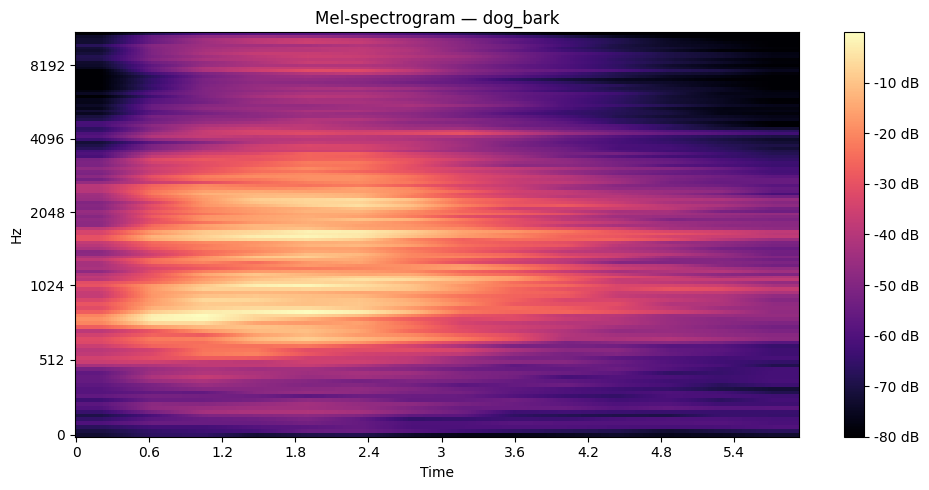

In [ ]:
# Визуализируем Mel-spectrogram
plt.figure(figsize=(10, 5))

librosa.display.specshow(
    mel_fixed,
    sr=SAMPLE_RATE,
    hop_length=HOP_LENGTH,
    x_axis='time',
    y_axis='mel'
)

plt.colorbar(format='%+2.0f dB')
plt.title(f'Mel-spectrogram — {df.iloc[0]["class"]}')
plt.tight_layout()
plt.show()

In [ ]:
# Нормализация. Перед CNN удобно привести значения к диапазону примерно 0...1
def normalize_mel(mel_db):

    MIN_DB = -80
    MAX_DB = 0

    mel_db = np.clip(mel_db, MIN_DB, MAX_DB)
    mel_db = (mel_db - MIN_DB) / (MAX_DB - MIN_DB)

    return mel_db

In [ ]:
mel_normalized = normalize_mel(mel_fixed)

print(mel_normalized.min(), mel_normalized.max())

0.0 0.999595


In [ ]:
# Создаём полный набор Mel-признаков (обработаем все файлы)
mel_features = []
valid_indices = []

for index, filepath in tqdm(
    data_features['filepath'].items(),
    desc='Создание Mel-spectrogram'
):

    try:

        mel = extract_mel_spectrogram(filepath)

        mel = resize_mel_spectrogram(mel)

        mel = normalize_mel(mel)

        mel_features.append(mel.astype(np.float32))

        valid_indices.append(index)

    except Exception as error:

        print(
            f'Ошибка в файле: {filepath}'
        )

        print(error)

Создание Mel-spectrogram: 0it [00:00, ?it/s]

In [ ]:
# Превращаем список в NumPy-массив
X_mel = np.stack(mel_features)
print('Размер X_mel:', X_mel.shape)

Размер X_mel: (8732, 128, 256)


In [ ]:
# Добавляем канал , т.к.
# PyTorch CNN обычно ожидает данные в формате (batch, channels, height, width)
X_mel = X_mel[:, np.newaxis, :, :]
print('Размер X_mel:', X_mel.shape)

Размер X_mel: (8732, 1, 128, 256)


In [ ]:
# Восстанавливаем правильные метки
# Т.к. некоторые файлы теоретически могли не обработаться, используем valid_indices
mel_metadata = data_features.loc[valid_indices].copy()

y_mel = mel_metadata['classID'].to_numpy()

print('X:', X_mel.shape)
print('y:', y_mel.shape)
print('metadata:', mel_metadata.shape)

X: (8732, 1, 128, 256)
y: (8732,)
metadata: (8732, 65)


In [ ]:
mel_metadata.head()

,slice_file_name,fold,classID,class,filepath,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,...,spectral_centroid_mean,spectral_centroid_std,spectral_bandwidth_mean,spectral_bandwidth_std,spectral_rolloff_mean,spectral_rolloff_std,zero_crossing_rate_mean,zero_crossing_rate_std,rms_mean,rms_std
0,100032-3-0-0.wav,5,3,dog_bark,/content/UrbanSound8K_audio/100032-3-0-0.wav,-275.91843,130.087770,119.49279,14.965517,-98.211780,...,2501.385834,322.217164,2850.927603,626.450406,3253.051758,485.570101,0.066302,0.012149,0.115351,0.114443
1,100263-2-0-117.wav,5,2,children_playing,/content/UrbanSound8K_audio/100263-2-0-117.wav,-500.90840,22.012790,185.10641,11.297286,-86.532820,...,2232.577799,279.239437,2284.091602,280.173239,4081.696671,355.405658,0.071667,0.020666,0.003983,0.001132
2,100263-2-0-121.wav,5,2,children_playing,/content/UrbanSound8K_audio/100263-2-0-121.wav,-531.19530,12.762764,186.93994,8.001002,-70.349160,...,1956.527004,207.627439,2327.294853,195.100132,3768.060887,314.119076,0.052590,0.014701,0.003000,0.000636
3,100263-2-0-126.wav,5,2,children_playing,/content/UrbanSound8K_audio/100263-2-0-126.wav,-476.78442,26.047169,160.33328,17.871094,-62.952843,...,2652.462734,723.266892,2929.146794,524.423948,4979.787279,1635.620026,0.072764,0.032739,0.004612,0.001912
4,100263-2-0-137.wav,5,2,children_playing,/content/UrbanSound8K_audio/100263-2-0-137.wav,-521.24470,12.964274,185.39265,7.281819,-81.950480,...,2095.392609,182.375477,2288.749922,158.145375,3966.291185,204.347644,0.060884,0.015910,0.003215,0.000539


In [ ]:
y_mel[:5]

array([3, 2, 2, 2, 2])

In [ ]:
# Сохраняем
np.save('/content/X_mel_improved.npy', X_mel)

np.save('/content/y_mel_improved.npy', y_mel)

mel_metadata.to_csv('/content/UrbanSound8K_mel_metadata.csv',index=False)

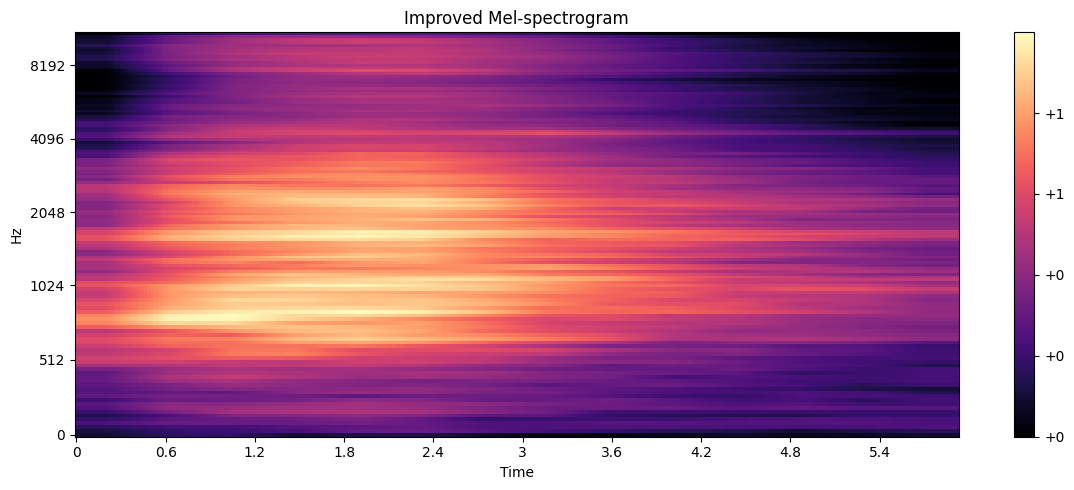

In [ ]:
# Посмотрим Mel
sample_mel = X_mel[0, 0]

plt.figure(figsize=(12, 5))

librosa.display.specshow(
    sample_mel,
    sr=SAMPLE_RATE,
    hop_length=HOP_LENGTH,
    x_axis='time',
    y_axis='mel'
)

plt.colorbar(format='%+2.0f')
plt.title('Improved Mel-spectrogram')
plt.tight_layout()
plt.show()

# 6. CNN на Mel-spectrogram

Построим сверточную нейронную сеть (CNN) на PyTorch, которая будет получать на вход Mel-spectrogram размера: 1 × 128 × 256

In [ ]:
# Определяем среду выполнения
device = torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)

print('Device:', device)

Device: cuda


In [ ]:
# Загружаем Mel
X_mel = np.load('/content/X_mel_improved.npy')
y_mel = np.load('/content/y_mel_improved.npy')

mel_metadata = pd.read_csv('/content/UrbanSound8K_mel_metadata.csv')

print('X_mel:', X_mel.shape)
print('y_mel:', y_mel.shape)
print('metadata:', mel_metadata.shape)

X_mel: (8732, 1, 128, 256)
y_mel: (8732,)
metadata: (8732, 65)


In [ ]:
# Проверяем соответствие
assert len(X_mel) == len(y_mel)
assert len(X_mel) == len(mel_metadata)

print('Данные согласованы.')

Данные согласованы.


In [ ]:
# Dataset со SpecAugment(добавим аугментацию только для training)
class UrbanSoundDataset(Dataset):

    def __init__(self, X, y, augment=False):

        self.X = X
        self.y = y
        self.augment = augment

    def __len__(self):

        return len(self.X)

    def __getitem__(self, index):

        x = torch.tensor(self.X[index], dtype=torch.float32)
        y = torch.tensor(self.y[index], dtype=torch.long)

        if self.augment:

            # Time masking
            time_mask = np.random.randint(0, 30)

            if time_mask > 0:
                time_start = np.random.randint(
                    0,
                    x.shape[-1] - time_mask + 1
                )

                x[
                    :,
                    :,
                    time_start:time_start + time_mask
                ] = 0

            # Frequency masking
            freq_mask = np.random.randint(0, 15)

            if freq_mask > 0:

                freq_start = np.random.randint(
                    0,
                    x.shape[-2] - freq_mask + 1
                )

                x[
                    :,
                    freq_start:freq_start + freq_mask,
                    :
                ] = 0

        return x, y

In [ ]:
# Строим CNN (1 → 32 → 64 → 128 → 256 → classifier)
class AudioCNN(nn.Module):

    def __init__(self, num_classes=10):

        super().__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.MaxPool2d(2),
            nn.Dropout2d(0.10),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.MaxPool2d(2),
            nn.Dropout2d(0.15),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.MaxPool2d(2),
            nn.Dropout2d(0.20),

            # Block 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),

            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),

            nn.MaxPool2d(2),
            nn.Dropout2d(0.25)
        )

        self.classifier = nn.Sequential(

            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.classifier(x)

        return x

In [ ]:
# Функция обучения одной эпохи модели CNN
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0

    all_preds = []
    all_targets = []

    for X_batch, y_batch in loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        outputs = model(X_batch)

        loss = criterion(outputs, y_batch)

        loss.backward()

        optimizer.step()

        running_loss += (loss.item() * X_batch.size(0))

        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.detach().cpu().numpy())
        all_targets.extend(y_batch.detach().cpu().numpy())

    epoch_loss = (running_loss / len(loader.dataset))
    epoch_accuracy = accuracy_score(all_targets, all_preds)

    return (epoch_loss, epoch_accuracy)

In [ ]:
# Evaluation
def evaluate(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    all_preds = []
    all_targets = []

    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            outputs = model(X_batch)

            loss = criterion(outputs, y_batch)
            running_loss += (loss.item() * X_batch.size(0))

            preds = outputs.argmax(dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(y_batch.cpu().numpy())

    epoch_loss = (running_loss / len(loader.dataset))
    epoch_accuracy = accuracy_score(all_targets, all_preds)
    epoch_f1 = f1_score(all_targets, all_preds, average='macro')
    epoch_mcc = matthews_corrcoef(all_targets, all_preds)

    return (epoch_loss,
        epoch_accuracy,
        epoch_f1,
        epoch_mcc,
        np.array(all_targets),
        np.array(all_preds)
    )

In [ ]:
# Параметры обучения
BATCH_SIZE = 32
NUM_EPOCHS = 80
LEARNING_RATE = 0.0005
WEIGHT_DECAY = 1e-4
NUM_CLASSES = 10
PATIENCE = 10

In [ ]:
# 10-fold CV
cv_results = []
all_cv_targets = []
all_cv_predictions = []
fold_histories = []

for test_fold in tqdm(range(1, 11)):

    # Следующий fold используем как validation
    validation_fold = (test_fold % 10) + 1

    print()
    print('=' * 80)
    print(f'TEST FOLD: {test_fold}'    )
    print(f'VALIDATION FOLD: {validation_fold}')
    print('=' * 80)

    # --------------------------------
    # MASKS
    # --------------------------------

    test_mask = (mel_metadata['fold'] == test_fold).to_numpy()

    validation_mask = (mel_metadata['fold'] == validation_fold).to_numpy()

    train_mask = ((mel_metadata['fold'] != test_fold) & (mel_metadata['fold'] != validation_fold)).to_numpy()

    # --------------------------------
    # DATA
    # --------------------------------

    X_train = X_mel[train_mask]
    y_train = y_mel[train_mask]

    X_val = X_mel[validation_mask]
    y_val = y_mel[validation_mask]

    X_test = X_mel[test_mask]
    y_test = y_mel[test_mask]

    print('Train:', X_train.shape)
    print('Validation:', X_val.shape)
    print('Test:', X_test.shape)

    # --------------------------------
    # DATASETS
    # --------------------------------

    train_dataset = UrbanSoundDataset(X_train, y_train, augment=True)

    validation_dataset = UrbanSoundDataset(X_val, y_val, augment=False)

    test_dataset = UrbanSoundDataset(X_test, y_test, augment=False)

    # --------------------------------
    # DATALOADERS
    # --------------------------------

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False)

    validation_loader = DataLoader(validation_dataset, batch_size=BATCH_SIZE, shuffle=False)

    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

    # --------------------------------
    # MODEL
    # --------------------------------

    model = AudioCNN(num_classes=NUM_CLASSES).to(device)

    # --------------------------------
    # CLASS WEIGHTS
    # --------------------------------

    class_counts = np.bincount(y_train, minlength=NUM_CLASSES)

    class_weights = (len(y_train) / (NUM_CLASSES * class_counts))

    class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)

    criterion = nn.CrossEntropyLoss(weight=class_weights)

    # --------------------------------
    # OPTIMIZER
    # --------------------------------

    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

    # --------------------------------
    # SCHEDULER
    # --------------------------------

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode='max',
        factor=0.5,
        patience=2
    )

    # --------------------------------
    # BEST MODEL
    # --------------------------------

    best_val_mcc = -1.0
    best_epoch = 0
    best_state = None
    epochs_without_improvement = 0
    history = []

    # --------------------------------
    # TRAINING
    # --------------------------------

    for epoch in range(NUM_EPOCHS):

        train_loss, train_acc = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            device
        )

        (
            val_loss,
            val_acc,
            val_f1,
            val_mcc,
            _,
            _
        ) = evaluate(
            model,
            validation_loader,
            criterion,
            device
        )

        scheduler.step(val_mcc)

        current_lr = optimizer.param_groups[0]['lr']

        history.append({
            'epoch': epoch + 1,
            'train_loss': train_loss,
            'train_accuracy': train_acc,
            'val_loss': val_loss,
            'val_accuracy': val_acc,
            'val_f1': val_f1,
            'val_mcc': val_mcc,
            'lr': current_lr
        })

        print(
            f'Epoch {epoch + 1:02d}/{NUM_EPOCHS} | '
            f'Train Loss: {train_loss:.4f} | '
            f'Train Acc: {train_acc:.4f} | '
            f'Val Acc: {val_acc:.4f} | '
            f'Val F1: {val_f1:.4f} | '
            f'Val MCC: {val_mcc:.4f} | '
            f'LR: {current_lr:.6f}'
        )

        # --------------------------------
        # BEST MODEL BY VALIDATION MCC
        # --------------------------------

        if val_mcc > best_val_mcc:

            best_val_mcc = val_mcc
            best_epoch = epoch + 1
            best_state = deepcopy(model.state_dict())
            epochs_without_improvement = 0

        else:

            epochs_without_improvement += 1

        # --------------------------------
        # EARLY STOPPING
        # --------------------------------

        if epochs_without_improvement >= PATIENCE:

            print(
                f'\nEarly stopping '
                f'at epoch {epoch + 1}'
            )

            break

    # --------------------------------
    # LOAD BEST MODEL
    # --------------------------------

    model.load_state_dict(best_state)

    print()
    print(f'Best epoch: {best_epoch}')

    print(
        f'Best validation MCC: '
        f'{best_val_mcc:.4f}'
    )

    # --------------------------------
    # FINAL TEST
    # --------------------------------

    (
        test_loss,
        test_acc,
        test_f1,
        test_mcc,
        y_true,
        y_pred
    ) = evaluate(
        model,
        test_loader,
        criterion,
        device
    )

    print()
    print(f'Test fold {test_fold}:')
    print(f'Accuracy: {test_acc:.4f}')
    print(f'F1 Macro: {test_f1:.4f}')
    print(f'MCC:      {test_mcc:.4f}')

    # --------------------------------
    # SAVE RESULTS
    # --------------------------------

    cv_results.append({

        'test_fold': test_fold,

        'validation_fold':
            validation_fold,

        'best_epoch':
            best_epoch,

        'best_val_mcc':
            best_val_mcc,

        'test_accuracy':
            test_acc,

        'test_f1_macro':
            test_f1,

        'test_mcc':
            test_mcc
    })

    all_cv_targets.extend(y_true)
    all_cv_predictions.extend(y_pred)
    fold_histories.append(pd.DataFrame(history))

  0%|          | 0/10 [00:00<?, ?it/s]


TEST FOLD: 1
VALIDATION FOLD: 2
Train: (6971, 1, 128, 256)
Validation: (888, 1, 128, 256)
Test: (873, 1, 128, 256)
Epoch 01/80 | Train Loss: 2.2553 | Train Acc: 0.1511 | Val Acc: 0.1813 | Val F1: 0.1153 | Val MCC: 0.1275 | LR: 0.000500
Epoch 02/80 | Train Loss: 2.1458 | Train Acc: 0.1954 | Val Acc: 0.2691 | Val F1: 0.1994 | Val MCC: 0.1965 | LR: 0.000500
Epoch 03/80 | Train Loss: 2.1031 | Train Acc: 0.2122 | Val Acc: 0.2849 | Val F1: 0.2315 | Val MCC: 0.2146 | LR: 0.000500
Epoch 04/80 | Train Loss: 2.0443 | Train Acc: 0.2358 | Val Acc: 0.2815 | Val F1: 0.2449 | Val MCC: 0.2126 | LR: 0.000500
Epoch 05/80 | Train Loss: 1.9993 | Train Acc: 0.2424 | Val Acc: 0.2962 | Val F1: 0.2515 | Val MCC: 0.2349 | LR: 0.000500
Epoch 06/80 | Train Loss: 1.9689 | Train Acc: 0.2543 | Val Acc: 0.3311 | Val F1: 0.3059 | Val MCC: 0.2643 | LR: 0.000500
Epoch 07/80 | Train Loss: 1.9295 | Train Acc: 0.2713 | Val Acc: 0.3300 | Val F1: 0.2983 | Val MCC: 0.2631 | LR: 0.000500
Epoch 08/80 | Train Loss: 1.8973 | Tr

In [ ]:
# Итоговые результаты
cv_results_df = pd.DataFrame(cv_results)

cv_results_df

,test_fold,validation_fold,best_epoch,best_val_mcc,test_accuracy,test_f1_macro,test_mcc
0,1,2,50,0.454238,0.584192,0.594318,0.537831
1,2,3,72,0.567184,0.568694,0.584022,0.527118
2,3,4,48,0.438235,0.540541,0.576574,0.487874
3,4,5,51,0.581410,0.488889,0.501111,0.434859
4,5,6,47,0.602200,0.605769,0.623956,0.562954
5,6,7,73,0.536504,0.607533,0.606954,0.566134
6,7,8,64,0.553932,0.539379,0.547253,0.489356
7,8,9,72,0.520010,0.488834,0.514741,0.426855
8,9,10,37,0.348669,0.450980,0.425617,0.391526
9,10,1,29,0.637678,0.574671,0.574593,0.525912


In [ ]:
# Средние результаты
print()
print('=' * 70)
print('FINAL 10-FOLD CNN RESULTS')
print('=' * 70)

print()

print(
    f"Accuracy: "
    f"{cv_results_df['test_accuracy'].mean():.4f} "
    f"± "
    f"{cv_results_df['test_accuracy'].std():.4f}"
)

print(
    f"F1 Macro: "
    f"{cv_results_df['test_f1_macro'].mean():.4f} "
    f"± "
    f"{cv_results_df['test_f1_macro'].std():.4f}"
)

print(
    f"MCC: "
    f"{cv_results_df['test_mcc'].mean():.4f} "
    f"± "
    f"{cv_results_df['test_mcc'].std():.4f}"
)


FINAL 10-FOLD CNN RESULTS

Accuracy: 0.5449 ± 0.0535
F1 Macro: 0.5549 ± 0.0596
MCC: 0.4950 ± 0.0601


In [ ]:
# Сохраняем результаты
cv_results_df.to_csv(
    '/content/df_10fold_cnn.csv',
    index=False
)

summary_table.to_csv(
    '/content/df_grade_mean_cnn.csv',
    index=False
)

In [ ]:
# Загружаем результаты по 10 folds CNN
df_10fold_cnn = pd.read_csv('/content/CNN_improved_10fold_results.csv')
df_10fold_cnn

,test_fold,validation_fold,best_epoch,best_val_mcc,test_accuracy,test_f1_macro,test_mcc
0,1,2,50,0.454238,0.584192,0.594318,0.537831
1,2,3,72,0.567184,0.568694,0.584022,0.527118
2,3,4,48,0.438235,0.540541,0.576574,0.487874
3,4,5,51,0.581410,0.488889,0.501111,0.434859
4,5,6,47,0.602200,0.605769,0.623956,0.562954
5,6,7,73,0.536504,0.607533,0.606954,0.566134
6,7,8,64,0.553932,0.539379,0.547253,0.489356
7,8,9,72,0.520010,0.488834,0.514741,0.426855
8,9,10,37,0.348669,0.450980,0.425617,0.391526
9,10,1,29,0.637678,0.574671,0.574593,0.525912


In [ ]:
# Преобразуем в новый датафрейм

accuracy_mean = df_10fold_cnn['test_accuracy'].mean()
accuracy_std = df_10fold_cnn['test_accuracy'].std()

f1_mean = df_10fold_cnn['test_f1_macro'].mean()
f1_std = df_10fold_cnn['test_f1_macro'].std()

mcc_mean = df_10fold_cnn['test_mcc'].mean()
mcc_std = df_10fold_cnn['test_mcc'].std()

In [ ]:
df_grade_mean_cnn = pd.DataFrame({
    'model': ['CNN'],
    'accuracy_mean': [accuracy_mean],
    'accuracy_std': [accuracy_std],
    'f1_mean': [f1_mean],
    'f1_std': [f1_std],
    'mcc_mean': [mcc_mean],
    'mcc_std': [mcc_std],
}).round(4)
df_grade_mean_cnn

,model,accuracy_mean,accuracy_std,f1_mean,f1_std,mcc_mean,mcc_std
0,CNN,0.5449,0.0535,0.5549,0.0596,0.495,0.0601


In [ ]:
result111 = pd.concat([df_grade_mean_ml, df_grade_mean_cnn],ignore_index=True)
result111.index = result111.index + 1
result111

,model,accuracy_mean,accuracy_std,f1_mean,f1_std,mcc_mean,mcc_std
1,Logistic Regression,0.6246,0.0507,0.6351,0.0535,0.5809,0.0567
2,Random Forest,0.6613,0.0212,0.6691,0.0228,0.6228,0.0242
3,SVM,0.6586,0.0587,0.6667,0.0625,0.6202,0.0648
4,CNN,0.5449,0.0535,0.5549,0.0596,0.4950,0.0601


In [ ]:
# Confusion Matrix
class_names = [
    'air_conditioner',
    'car_horn',
    'children_playing',
    'dog_bark',
    'drilling',
    'engine_idling',
    'gun_shot',
    'jackhammer',
    'siren',
    'street_music'
]

all_cv_targets = np.array(all_cv_targets)
all_cv_predictions = np.array(all_cv_predictions)

cm = confusion_matrix(all_cv_targets, all_cv_predictions)

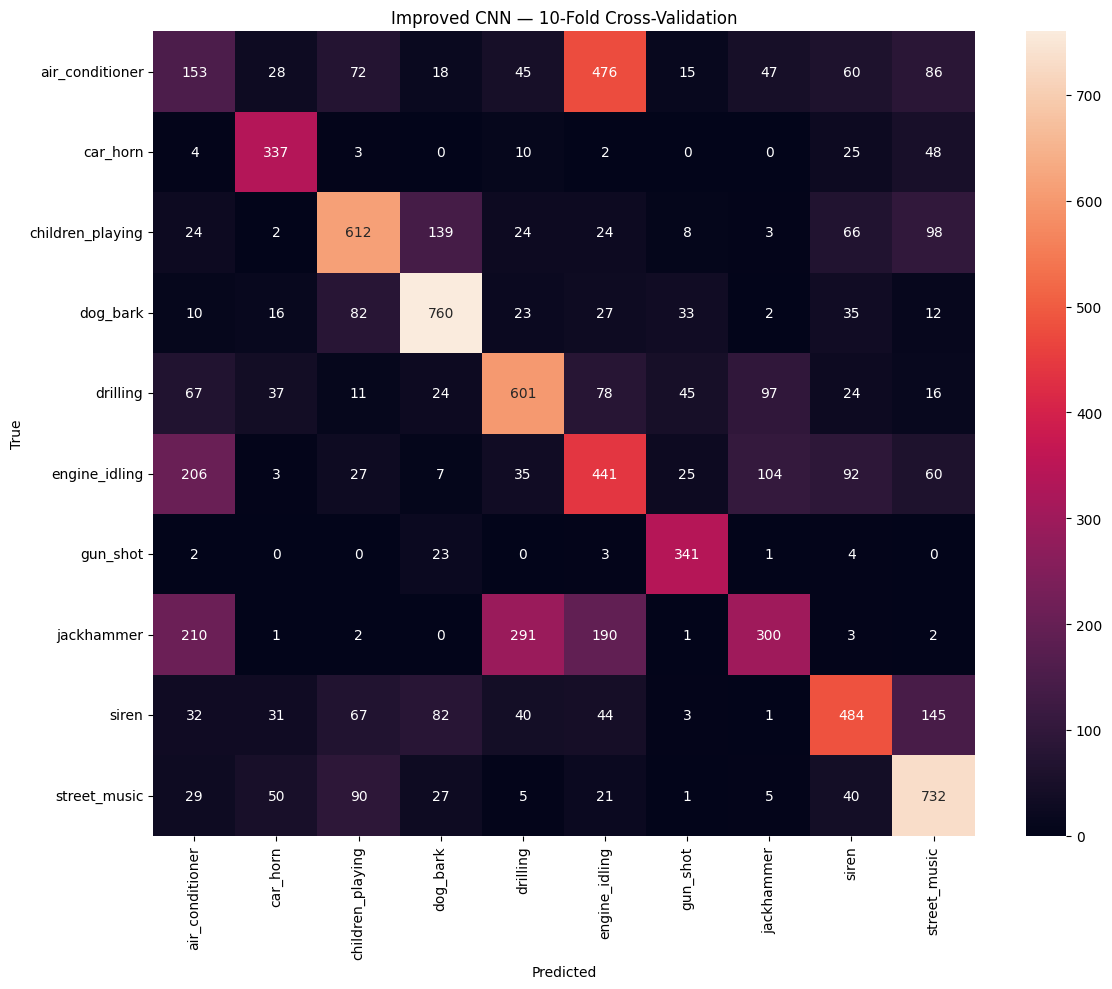

In [ ]:
plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Improved CNN — 10-Fold Cross-Validation')
plt.tight_layout()
plt.show()

In [ ]:
# Classification report
print(
    classification_report(
        all_cv_targets,
        all_cv_predictions,
        target_names=class_names
    )
)

                  precision    recall  f1-score   support

 air_conditioner       0.21      0.15      0.18      1000
        car_horn       0.67      0.79      0.72       429
children_playing       0.63      0.61      0.62      1000
        dog_bark       0.70      0.76      0.73      1000
        drilling       0.56      0.60      0.58      1000
   engine_idling       0.34      0.44      0.38      1000
        gun_shot       0.72      0.91      0.81       374
      jackhammer       0.54      0.30      0.38      1000
           siren       0.58      0.52      0.55       929
    street_music       0.61      0.73      0.67      1000

        accuracy                           0.55      8732
       macro avg       0.56      0.58      0.56      8732
    weighted avg       0.54      0.55      0.53      8732



In [ ]:
# Сохраняем
classification_report.reset_index().rename(columns={"index": "class"}).to_csv(
    '/content/df_class_rep_cnn.csv',
    index=False
)

In [ ]:
# Загружаем
df_class_rep_cnn = pd.read_csv('/content/df_class_rep_cnn.csv').round(4)
df_class_rep_cnn['support'] = df_class_rep_cnn['support'].astype(int)
df_class_rep_cnn.index = df_class_rep_cnn.index + 1
df_class_rep_cnn

,class,precision,recall,f1-score,support
1,air_conditioner,0.2134,0.1504,0.1821,1000
2,car_horn,0.6760,0.7907,0.7275,429
3,children_playing,0.6359,0.6150,0.6276,1000
4,dog_bark,0.7037,0.7600,0.7307,1000
5,drilling,0.5611,0.6050,0.5846,1000
6,engine_idling,0.3414,0.4470,0.3845,1000
7,gun_shot,0.7204,0.9104,0.8104,374
8,jackhammer,0.5452,0.3000,0.3812,1000
9,siren,0.5894,0.5269,0.5517,929
10,street_music,0.6162,0.7390,0.6761,1000


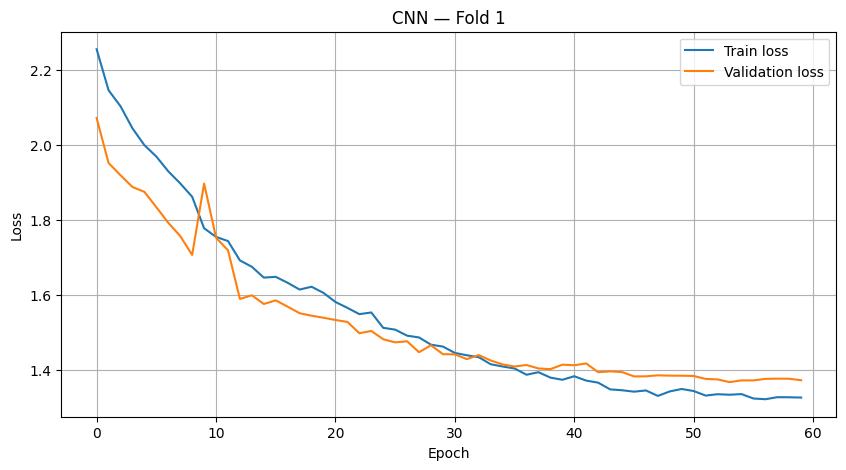

In [ ]:
# График обучения Loss
history_fold_1 = fold_histories[0]
plt.figure(figsize=(10, 5))

plt.plot(
    history_fold_1['train_loss'],
    label='Train loss'
)

plt.plot(
    history_fold_1['val_loss'],
    label='Validation loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('CNN — Fold 1')

plt.legend()
plt.grid()
plt.show()

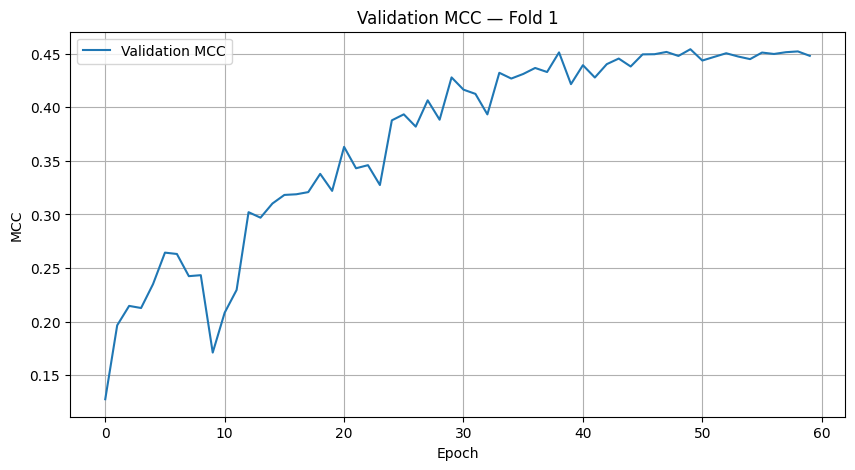

In [ ]:
# График обучения MCC
plt.figure(figsize=(10, 5))

plt.plot(
    history_fold_1['val_mcc'],
    label='Validation MCC'
)

plt.xlabel('Epoch')
plt.ylabel('MCC')
plt.title('Validation MCC — Fold 1')
plt.legend()
plt.grid()
plt.show()

Результат модели на CNN показал MCC: 0.4950 ± 0.0601, а baseline - MCC: 0.6228 ± 0.0242.

Причем подбирались многие геперпараметры (LEARNING_RATE, PATIENCE, NUM_EPOCHS), менялась ширина Mel-спектрограммы.

Вычисления длились подолгу с разными параметрами (3 дня). Но улучшить baseline пока не удалось.

Поэтому создадим ещё одну модель.

# 7. Модель Mel-spectrogram + Delta + Delta-Delta → 3 канала → ResNet18

Идея такая:

1) Канал 1 = Mel

2) канал 2 = Delta — как меняется Mel во времени

3) канал 3 = Delta-Delta — как меняется сама Delta

4) эти три матрицы объединяем как RGB-картинку [3, 128, 256]

5) подаём в ResNet18 (ResNet18 адаптируем с 3 каналов на 10 классов)

In [ ]:
# Параметры (оставляем такие же как в CNN)
SAMPLE_RATE = 22050
N_MELS = 128
N_FFT = 2048
HOP_LENGTH = 512

TARGET_HEIGHT = 128
TARGET_WIDTH = 256

MIN_DB = -80
MAX_DB = 0

In [ ]:
# Получение Mel
def extract_mel_spectrogram(filepath):

    audio, sr = librosa.load(
        filepath,
        sr=SAMPLE_RATE,
        mono=True
    )

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=sr,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS
    )

    mel_db = librosa.power_to_db(
        mel,
        ref=np.max
    )

    return mel_db

In [ ]:
# Resize
# Теперь независимо от длины исходного аудио получаем 128 × 256
def resize_spectrogram(
    spectrogram,
    target_height=TARGET_HEIGHT,
    target_width=TARGET_WIDTH
):

    spectrogram_resized = resize(
        spectrogram,
        (
            target_height,
            target_width
        ),
        mode='reflect',
        anti_aliasing=True
    )

    return spectrogram_resized

In [ ]:
# Нормализация
def normalize_mel(mel_db):

    mel_db = np.clip(mel_db, MIN_DB, MAX_DB    )

    mel_db = (mel_db - MIN_DB) / (MAX_DB - MIN_DB)

    return mel_db

In [ ]:
# Функция извлечения признаков Mel, Delta и Delta-Delta
def extract_mel_delta_features(filepath):

    # ==========================================
    # 1. Загружаем Mel-spectrogram
    # ==========================================

    mel_db = extract_mel_spectrogram(filepath)

    # ==========================================
    # 2. Безопасно вычисляем Delta
    # ==========================================

    n_frames = mel_db.shape[1]

    # Выбираем нечётное окно:
    # 9 -> если хватает кадров
    # 7 -> если 7 кадров
    # 5 -> если 5 кадров
    # 3 -> если 3 кадра

    if n_frames >= 9:
        width = 9
    elif n_frames >= 7:
        width = 7
    elif n_frames >= 5:
        width = 5
    elif n_frames >= 3:
        width = 3
    else:
        width = None

    if width is not None:

        delta = librosa.feature.delta(
            mel_db,
            order=1,
            width=width,
            mode='nearest'
        )

        delta_delta = librosa.feature.delta(
            mel_db,
            order=2,
            width=width,
            mode='nearest'
        )

    else:

        # Если аудио экстремально короткое
        delta = np.zeros_like(mel_db)

        delta_delta = np.zeros_like(mel_db)

    # ==========================================
    # 3. Resize
    # ==========================================

    mel_db = resize_spectrogram(mel_db)

    delta = resize_spectrogram(delta)

    delta_delta = resize_spectrogram(delta_delta)

    # ==========================================
    # 4. Нормализация Mel
    # ==========================================

    mel_db = normalize_mel(mel_db)

    # ==========================================
    # 5. Нормализация Delta
    # ==========================================

    delta_min = delta.min()
    delta_max = delta.max()

    delta = (
        delta - delta_min
    ) / (
        delta_max - delta_min + 1e-8
    )

    # ==========================================
    # 6. Нормализация Delta-Delta
    # ==========================================

    delta_delta_min = delta_delta.min()
    delta_delta_max = delta_delta.max()

    delta_delta = (
        delta_delta - delta_delta_min
    ) / (
        delta_delta_max
        - delta_delta_min
        + 1e-8
    )

    # ==========================================
    # 7. Объединяем 3 канала
    # ==========================================

    features = np.stack(
        [
            mel_db,
            delta,
            delta_delta
        ],
        axis=0
    )

    return features.astype(np.float32)

In [ ]:
def calculate_delta_safe(mel, order=1):

    n_frames = mel.shape[1]

    # Минимально допустимое окно
    # должно быть нечётным
    max_width = min(
        9,
        n_frames if n_frames % 2 == 1
        else n_frames - 1
    )

    # Если кадров слишком мало
    if max_width < 3:
        return np.zeros_like(mel)

    return librosa.feature.delta(
        mel,
        order=order,
        width=max_width
    )

In [ ]:
# Создаём весь датасет
data_features = pd.read_csv(
    '/content/UrbanSound8K_features.csv'
)

X_mel_delta = []

valid_indices = []

for index, filepath in tqdm(
    data_features['filepath'].items(),
    desc='Mel + Delta + Delta-Delta'
):

    try:

        features = extract_mel_delta_features(filepath)
        X_mel_delta.append(features)
        valid_indices.append(index)

    except Exception as error:

        print()
        print(f'Ошибка в файле: {filepath}')
        print(error)

Mel + Delta + Delta-Delta: 0it [00:00, ?it/s]

In [ ]:
print('Обработано:', len(X_mel_delta))

print('Исходных:', len(data_features))

print('Shape:', np.array(X_mel_delta).shape)

Обработано: 8732
Исходных: 8732
Shape: (8732, 3, 128, 256)


In [ ]:
# Формируем X и y
X_mel_delta = np.stack(X_mel_delta)

mel_delta_metadata = data_features.loc[valid_indices].copy()

y_mel_delta = (mel_delta_metadata['classID'].to_numpy())

In [ ]:
# Проверяем
print('X:', X_mel_delta.shape)

print('y:', y_mel_delta.shape)

print('metadata:', mel_delta_metadata.shape)

X: (8732, 3, 128, 256)
y: (8732,)
metadata: (8732, 65)


In [ ]:
# Сохраняем
np.save('/content/X_mel_delta.npy', X_mel_delta)

np.save('/content/y_mel_delta.npy', y_mel_delta)

mel_delta_metadata.to_csv('/content/UrbanSound8K_mel_delta_metadata.csv', index=False)

In [ ]:
# Посмотрим спектрограммы для трёх каналов для выборочного WAV-файла
sample = X_mel_delta[0]

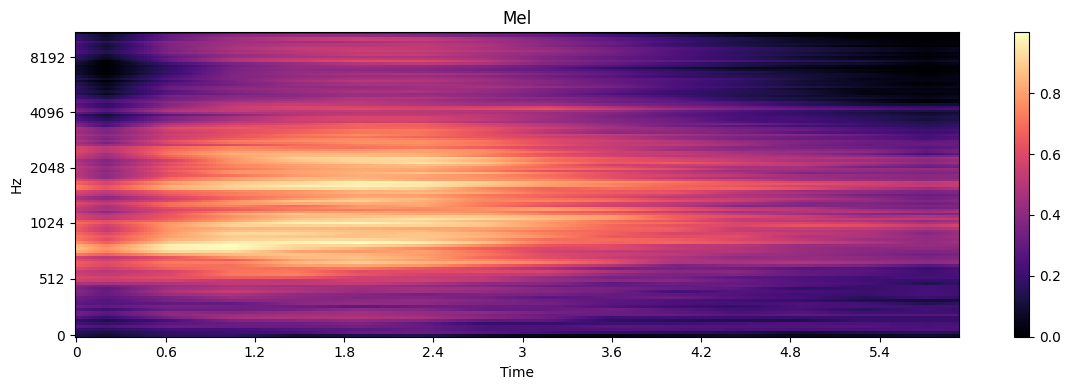

In [ ]:
# Mel
plt.figure(figsize=(12, 4))

librosa.display.specshow(
    sample[0],
    x_axis='time',
    y_axis='mel',
    sr=SAMPLE_RATE,
    hop_length=HOP_LENGTH
)

plt.colorbar()
plt.title('Mel')
plt.tight_layout()
plt.show()

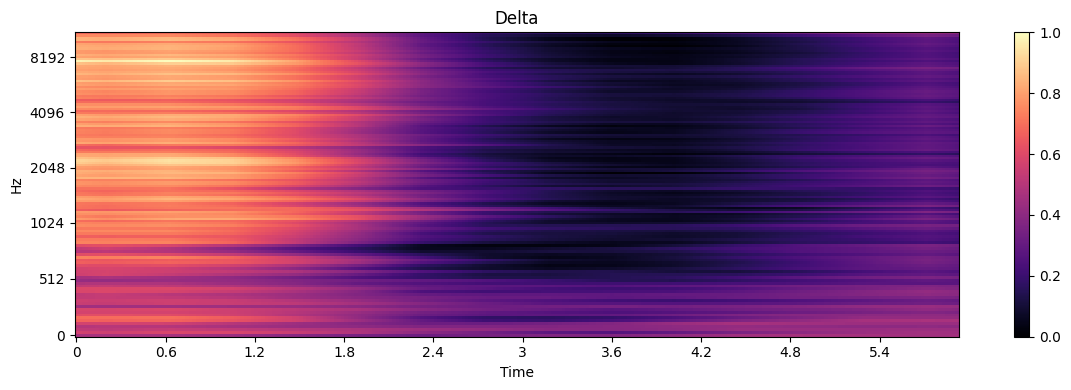

In [ ]:
# Delta
plt.figure(figsize=(12, 4))

librosa.display.specshow(
    sample[1],
    x_axis='time',
    y_axis='mel',
    sr=SAMPLE_RATE,
    hop_length=HOP_LENGTH
)

plt.colorbar()
plt.title('Delta')
plt.tight_layout()
plt.show()

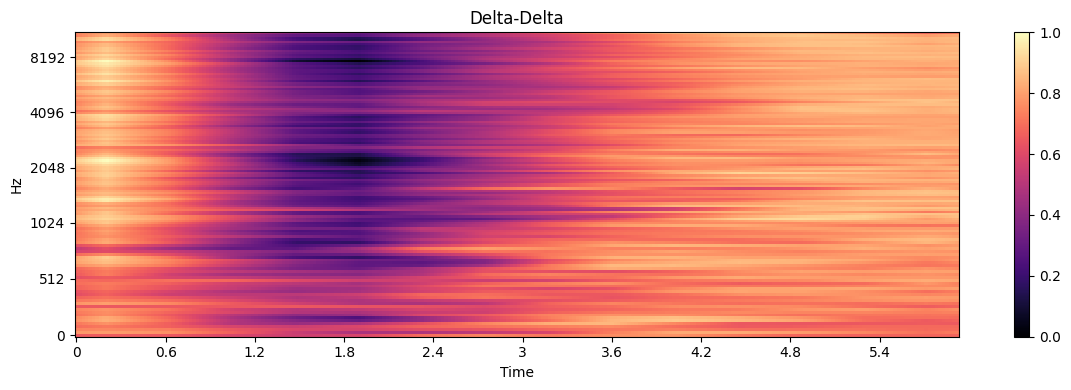

In [ ]:
# Delta-Delta
plt.figure(figsize=(12, 4))

librosa.display.specshow(
    sample[2],
    x_axis='time',
    y_axis='mel',
    sr=SAMPLE_RATE,
    hop_length=HOP_LENGTH
)

plt.colorbar()
plt.title('Delta-Delta')
plt.tight_layout()
plt.show()

Теперь CNN можно заменить на ResNet18

In [ ]:
# Загружаем данные
X_mel_delta = np.load('/content/X_mel_delta.npy')

y_mel_delta = np.load('/content/y_mel_delta.npy')

mel_delta_metadata = pd.read_csv('/content/UrbanSound8K_mel_delta_metadata.csv')

In [ ]:
# Проверяем
print(X_mel_delta.shape)

print(y_mel_delta.shape)

print(mel_delta_metadata.shape)

(8732, 3, 128, 256)
(8732,)
(8732, 65)


In [ ]:
# Dataset
class UrbanSoundDataset(Dataset):

    def __init__(self, X, y, augment=False):

        self.X = X
        self.y = y
        self.augment = augment

    def __len__(self):

        return len(self.X)

    def __getitem__(self, index):

        x = torch.tensor(self.X[index], dtype=torch.float32)

        y = torch.tensor(self.y[index], dtype=torch.long)

        if self.augment:

            # -------------------------
            # Time masking
            # -------------------------

            time_mask = np.random.randint(0, 30)

            if time_mask > 0:

                time_start = np.random.randint(
                    0,
                    x.shape[-1] - time_mask + 1
                )

                x[
                    :,
                    :,
                    time_start:time_start + time_mask
                ] = 0

            # -------------------------
            # Frequency masking
            # -------------------------

            freq_mask = np.random.randint(
                0,
                15
            )

            if freq_mask > 0:

                freq_start = np.random.randint(
                    0,
                    x.shape[-2] - freq_mask + 1
                )

                x[
                    :,
                    freq_start:freq_start + freq_mask,
                    :
                ] = 0

        return x, y

In [ ]:
# ResNet18
def create_resnet18(num_classes=10):

    model = resnet18(weights=None)

    model.fc = nn.Linear(model.fc.in_features, num_classes)

    return model

In [ ]:
# Device
device = torch.device(
    'cuda'
    if torch.cuda.is_available()
    else 'cpu'
)

print(device)

cuda


In [ ]:
# Функция обучения
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0

    all_preds = []
    all_targets = []

    for X_batch, y_batch in loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        outputs = model(X_batch)

        loss = criterion(outputs, y_batch)

        loss.backward()

        optimizer.step()

        running_loss += (loss.item() * X_batch.size(0))

        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.detach().cpu().numpy())

        all_targets.extend(y_batch.detach().cpu().numpy())

    epoch_loss = (running_loss / len(loader.dataset))

    epoch_accuracy = accuracy_score(all_targets, all_preds)

    return (epoch_loss, epoch_accuracy)

In [ ]:
# Функция оценки
def evaluate(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0

    all_preds = []
    all_targets = []

    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            outputs = model(X_batch)

            loss = criterion(outputs, y_batch)

            running_loss += (loss.item() * X_batch.size(0))

            preds = outputs.argmax(dim=1)

            all_preds.extend(preds.cpu().numpy())

            all_targets.extend(y_batch.cpu().numpy())

    epoch_loss = (running_loss / len(loader.dataset))

    epoch_accuracy = accuracy_score(all_targets, all_preds)

    epoch_f1 = f1_score(all_targets, all_preds, average='macro')

    epoch_mcc = matthews_corrcoef(all_targets, all_preds)

    return (
        epoch_loss,
        epoch_accuracy,
        epoch_f1,
        epoch_mcc,
        np.array(all_targets),
        np.array(all_preds)
    )

In [ ]:
# Параметры обучения
BATCH_SIZE = 32
NUM_EPOCHS = 80
LEARNING_RATE = 0.0005
WEIGHT_DECAY = 1e-4
NUM_CLASSES = 10
PATIENCE = 15

In [ ]:
# 10-fold Cross-Validation
cv_results = []

all_cv_targets = []
all_cv_predictions = []

fold_histories = []

for test_fold in tqdm(range(1, 11)):

    print()
    print('=' * 60)
    print(
        f'TEST FOLD: {test_fold}'
    )
    print('=' * 60)

    # Следующий fold используем
    # как validation
    validation_fold = (test_fold % 10) + 1

    print(f'Validation fold: 'f'{validation_fold}')

    # --------------------------------
    # Маски
    # --------------------------------

    test_mask = (
        mel_delta_metadata['fold']
        == test_fold
    ).to_numpy()

    validation_mask = (
        mel_delta_metadata['fold']
        == validation_fold
    ).to_numpy()

    train_mask = (
        (mel_delta_metadata['fold'] != test_fold)
        &
        (mel_delta_metadata['fold'] != validation_fold)
    ).to_numpy()

    # --------------------------------
    # Train
    # --------------------------------

    X_train = X_mel_delta[train_mask]

    y_train = y_mel_delta[train_mask]

    # --------------------------------
    # Validation
    # --------------------------------

    X_val = X_mel_delta[validation_mask]

    y_val = y_mel_delta[validation_mask    ]

    # --------------------------------
    # Test
    # --------------------------------

    X_test = X_mel_delta[test_mask]

    y_test = y_mel_delta[test_mask]

    print(f'Train: {len(X_train)}')

    print(f'Validation: {len(X_val)}')

    print(f'Test: {len(X_test)}')

    # --------------------------------
    # Dataset
    # --------------------------------

    train_dataset = UrbanSoundDataset(
        X_train,
        y_train,
        augment=True
    )

    validation_dataset = UrbanSoundDataset(
        X_val,
        y_val,
        augment=False
    )

    test_dataset = UrbanSoundDataset(
        X_test,
        y_test,
        augment=False
    )

    # --------------------------------
    # DataLoader
    # --------------------------------

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    validation_loader = DataLoader(
        validation_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    # --------------------------------
    # Model
    # --------------------------------

    model = create_resnet18(num_classes=NUM_CLASSES).to(device)

    # --------------------------------
    # Class weights
    # --------------------------------

    class_counts = np.bincount(y_train, minlength=NUM_CLASSES)

    class_weights = (len(y_train) / (NUM_CLASSES * class_counts))

    class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)

    criterion = nn.CrossEntropyLoss(weight=class_weights)

    # --------------------------------
    # Optimizer
    # --------------------------------

    optimizer = optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    # --------------------------------
    # Scheduler
    # --------------------------------

    scheduler = (
        optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode='max',
            factor=0.5,
            patience=2
        )
    )

    # --------------------------------
    # Best model
    # --------------------------------

    best_val_mcc = -1.0

    best_epoch = 0

    best_state = None

    epochs_without_improvement = 0

    history = []

    # =================================
    # Training
    # =================================

    for epoch in range(NUM_EPOCHS):

        train_loss, train_acc = (
            train_one_epoch(
                model,
                train_loader,
                criterion,
                optimizer,
                device
            )
        )

        (
            val_loss,
            val_acc,
            val_f1,
            val_mcc,
            _,
            _
        ) = evaluate(
            model,
            validation_loader,
            criterion,
            device
        )

        scheduler.step(
            val_mcc
        )

        current_lr = (
            optimizer
            .param_groups[0]['lr']
        )

        history.append({
            'epoch': epoch + 1,
            'train_loss': train_loss,
            'train_accuracy': train_acc,
            'val_loss': val_loss,
            'val_accuracy': val_acc,
            'val_f1': val_f1,
            'val_mcc': val_mcc,
            'lr': current_lr
        })

        print(
            f'Epoch {epoch + 1:02d} | '
            f'Train loss: {train_loss:.4f} | '
            f'Val MCC: {val_mcc:.4f}'
        )

        # --------------------------------
        # сохраняем лучшую модель
        # --------------------------------

        if val_mcc > best_val_mcc:

            best_val_mcc = val_mcc

            best_epoch = (epoch + 1)

            best_state = deepcopy(model.state_dict())

            epochs_without_improvement = 0

        else:

            epochs_without_improvement += 1

        # --------------------------------
        # Early stopping
        # --------------------------------

        if (epochs_without_improvement >= PATIENCE):

            print('Early stopping')

            break

    # =================================
    # Загружаем лучшую модель
    # =================================

    model.load_state_dict(best_state)

    # =================================
    # Test
    # =================================

    (
        test_loss,
        test_acc,
        test_f1,
        test_mcc,
        y_true,
        y_pred
    ) = evaluate(
        model,
        test_loader,
        criterion,
        device
    )

    print()
    print(f'Best epoch: {best_epoch}')

    print(f'Best validation MCC: 'f'{best_val_mcc:.4f}')

    print(f'Test Accuracy: 'f'{test_acc:.4f}')

    print(f'Test F1: 'f'{test_f1:.4f}')

    print(f'Test MCC: 'f'{test_mcc:.4f}')

    # --------------------------------
    # сохраняем результаты
    # --------------------------------

    cv_results.append({

        'test_fold': test_fold,

        'validation_fold':
            validation_fold,

        'best_epoch':
            best_epoch,

        'best_val_mcc':
            best_val_mcc,

        'test_accuracy':
            test_acc,

        'test_f1_macro':
            test_f1,

        'test_mcc':
            test_mcc
    })

    all_cv_targets.extend(y_true)

    all_cv_predictions.extend(y_pred)

    fold_histories.append(pd.DataFrame(history))

  0%|          | 0/10 [00:00<?, ?it/s]


TEST FOLD: 1
Validation fold: 2
Train: 6971
Validation: 888
Test: 873
Epoch 01 | Train loss: 2.3619 | Val MCC: 0.1193
Epoch 02 | Train loss: 2.1155 | Val MCC: 0.2614
Epoch 03 | Train loss: 1.9337 | Val MCC: 0.3660
Epoch 04 | Train loss: 1.7590 | Val MCC: 0.4239
Epoch 05 | Train loss: 1.6205 | Val MCC: 0.3635
Epoch 06 | Train loss: 1.4771 | Val MCC: 0.4102
Epoch 07 | Train loss: 1.3439 | Val MCC: 0.3414
Epoch 08 | Train loss: 1.1344 | Val MCC: 0.4684
Epoch 09 | Train loss: 1.0174 | Val MCC: 0.5080
Epoch 10 | Train loss: 0.9229 | Val MCC: 0.4957
Epoch 11 | Train loss: 0.8518 | Val MCC: 0.4998
Epoch 12 | Train loss: 0.7701 | Val MCC: 0.5372
Epoch 13 | Train loss: 0.6909 | Val MCC: 0.5539
Epoch 14 | Train loss: 0.6147 | Val MCC: 0.5251
Epoch 15 | Train loss: 0.5499 | Val MCC: 0.5010
Epoch 16 | Train loss: 0.4871 | Val MCC: 0.4936
Epoch 17 | Train loss: 0.3962 | Val MCC: 0.4655
Epoch 18 | Train loss: 0.3165 | Val MCC: 0.4970
Epoch 19 | Train loss: 0.2351 | Val MCC: 0.5237
Epoch 20 | Train 

In [ ]:
# Получаем итоговые результаты
cv_results_df = pd.DataFrame(cv_results)
cv_results_df

,test_fold,validation_fold,best_epoch,best_val_mcc,test_accuracy,test_f1_macro,test_mcc
0,1,2,33,0.597084,0.620848,0.627734,0.581829
1,2,3,35,0.563033,0.596847,0.592259,0.552205
2,3,4,39,0.585444,0.548108,0.568222,0.497544
3,4,5,42,0.635601,0.600000,0.594964,0.556355
4,5,6,39,0.617892,0.669872,0.657782,0.636724
5,6,7,31,0.683108,0.684083,0.695916,0.648747
6,7,8,44,0.678252,0.752983,0.766994,0.725234
7,8,9,40,0.686748,0.682382,0.679210,0.649959
8,9,10,56,0.704492,0.713235,0.700177,0.685779
9,10,1,27,0.610557,0.732378,0.757427,0.702939


In [ ]:
# Средние результаты
print(
    f"Accuracy: "
    f"{cv_results_df['test_accuracy'].mean():.4f} "
    f"± "
    f"{cv_results_df['test_accuracy'].std():.4f}"
)

print(
    f"F1 Macro: "
    f"{cv_results_df['test_f1_macro'].mean():.4f} "
    f"± "
    f"{cv_results_df['test_f1_macro'].std():.4f}"
)

print(
    f"MCC: "
    f"{cv_results_df['test_mcc'].mean():.4f} "
    f"± "
    f"{cv_results_df['test_mcc'].std():.4f}"
)

Accuracy: 0.6601 ± 0.0663
F1 Macro: 0.6641 ± 0.0686
MCC: 0.6237 ± 0.0740


In [ ]:
# Сохраняем результаты
cv_results_df.to_csv(
    '/content/ResNet18_Mel_Delta_10fold_results.csv',
    index=False
)

In [ ]:
# Загружаем результаты по 10 folds ResNet
df_10fold_resnet = pd.read_csv('/content/ResNet18_Mel_Delta_10fold_results.csv')
df_10fold_resnet

,test_fold,validation_fold,best_epoch,best_val_mcc,test_accuracy,test_f1_macro,test_mcc
0,1,2,33,0.597084,0.620848,0.627734,0.581829
1,2,3,35,0.563033,0.596847,0.592259,0.552205
2,3,4,39,0.585444,0.548108,0.568222,0.497544
3,4,5,42,0.635601,0.600000,0.594964,0.556355
4,5,6,39,0.617892,0.669872,0.657782,0.636724
5,6,7,31,0.683108,0.684083,0.695916,0.648747
6,7,8,44,0.678252,0.752983,0.766994,0.725234
7,8,9,40,0.686748,0.682382,0.679210,0.649959
8,9,10,56,0.704492,0.713235,0.700177,0.685779
9,10,1,27,0.610557,0.732378,0.757427,0.702939


In [ ]:
# Преобразуем в новый датафрейм
accuracy_mean = df_10fold_resnet['test_accuracy'].mean()
accuracy_std = df_10fold_resnet['test_accuracy'].std()

f1_mean = df_10fold_resnet['test_f1_macro'].mean()
f1_std = df_10fold_resnet['test_f1_macro'].std()

mcc_mean = df_10fold_resnet['test_mcc'].mean()
mcc_std = df_10fold_resnet['test_mcc'].std()

In [ ]:
df_grade_mean_resnet = pd.DataFrame({
    'model': ['ResNet'],
    'accuracy_mean': [accuracy_mean],
    'accuracy_std': [accuracy_std],
    'f1_mean': [f1_mean],
    'f1_std': [f1_std],
    'mcc_mean': [mcc_mean],
    'mcc_std': [mcc_std],
}).round(4)
df_grade_mean_resnet

,model,accuracy_mean,accuracy_std,f1_mean,f1_std,mcc_mean,mcc_std
0,ResNet,0.6601,0.0663,0.6641,0.0686,0.6237,0.074


In [ ]:
# Общая confusion matrix
class_names = [
    'air_conditioner',
    'car_horn',
    'children_playing',
    'dog_bark',
    'drilling',
    'engine_idling',
    'gun_shot',
    'jackhammer',
    'siren',
    'street_music'
]

all_cv_targets = np.array(all_cv_targets)

all_cv_predictions = np.array(all_cv_predictions)

cm = confusion_matrix(all_cv_targets, all_cv_predictions)

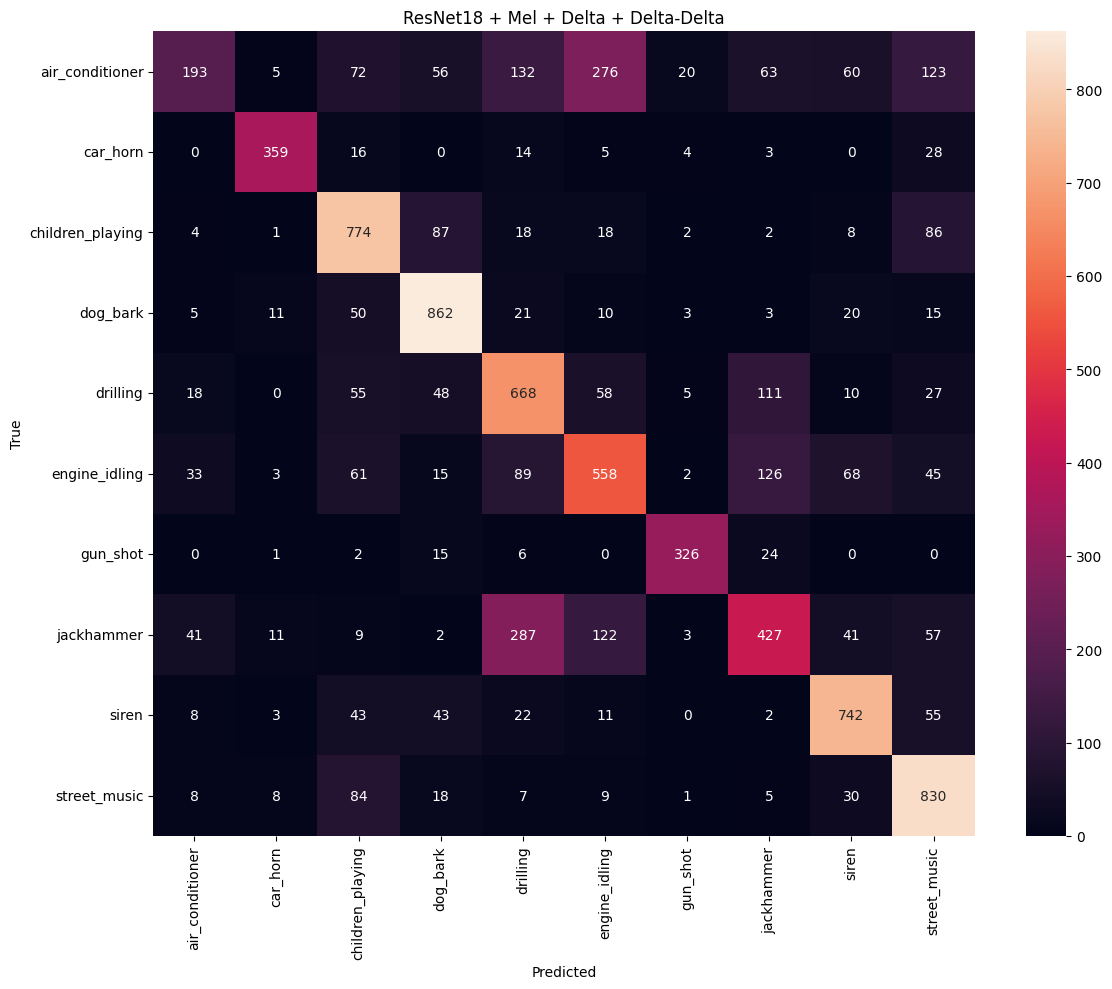

In [ ]:
plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('ResNet18 + Mel + Delta + Delta-Delta')
plt.tight_layout()
plt.show()

In [ ]:
# Classification report
print(
    classification_report(
        all_cv_targets,
        all_cv_predictions,
        target_names=class_names
    )
)

                  precision    recall  f1-score   support

 air_conditioner       0.62      0.19      0.29      1000
        car_horn       0.89      0.84      0.86       429
children_playing       0.66      0.77      0.71      1000
        dog_bark       0.75      0.86      0.80      1000
        drilling       0.53      0.67      0.59      1000
   engine_idling       0.52      0.56      0.54      1000
        gun_shot       0.89      0.87      0.88       374
      jackhammer       0.56      0.43      0.48      1000
           siren       0.76      0.80      0.78       929
    street_music       0.66      0.83      0.73      1000

        accuracy                           0.66      8732
       macro avg       0.68      0.68      0.67      8732
    weighted avg       0.66      0.66      0.64      8732



In [ ]:
# Сохраняем classification_report
classification_report.reset_index().rename(columns={"index": "class"}).to_csv(
    '/content/df_class_rep_resnet.csv',
    index=False
)

In [ ]:
# Загружаем
df_class_rep_resnet = pd.read_csv('/content/df_class_rep_resnet.csv').round(4)
df_class_rep_resnet['support'] = df_class_rep_resnet['support'].astype(int)
df_class_rep_resnet.index = df_class_rep_resnet.index + 1
df_class_rep_resnet

,class,precision,recall,f1-score,support
1,air_conditioner,0.6234,0.1904,0.2921,1000
2,car_horn,0.8960,0.8407,0.8675,429
3,children_playing,0.6659,0.7750,0.7102,1000
4,dog_bark,0.7537,0.8600,0.8068,1000
5,drilling,0.5311,0.6700,0.5946,1000
6,engine_idling,0.5214,0.5600,0.5445,1000
7,gun_shot,0.8904,0.8704,0.8804,374
8,jackhammer,0.5652,0.4300,0.4812,1000
9,siren,0.7635,0.8069,0.7817,929
10,street_music,0.6623,0.8300,0.7361,1000


In [ ]:
# График обучения
history_fold_1 = fold_histories[0]

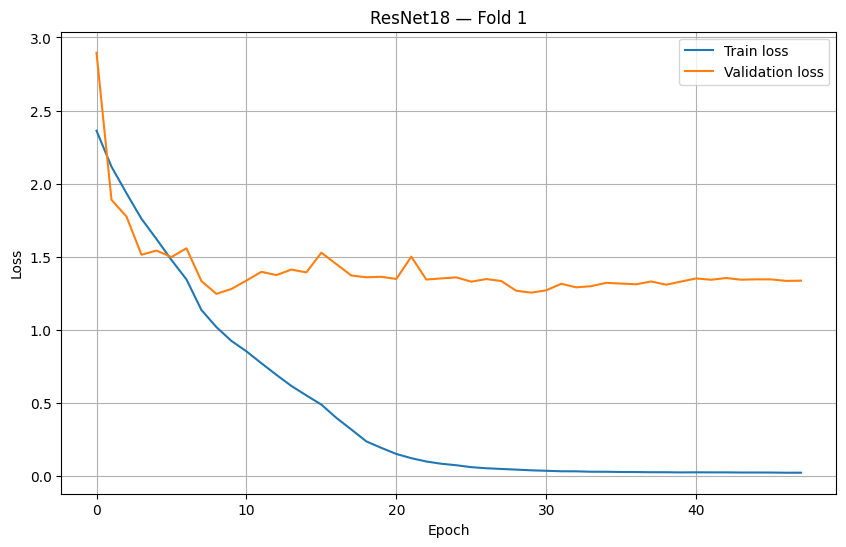

In [ ]:
# График обучения ResNet на 1 фолде для Функции потерь Loss:
plt.figure(figsize=(10, 6))

plt.plot(
    history_fold_1['train_loss'],
    label='Train loss'
)

plt.plot(
    history_fold_1['val_loss'],
    label='Validation loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('ResNet18 — Fold 1')
plt.legend()
plt.grid()
plt.show()

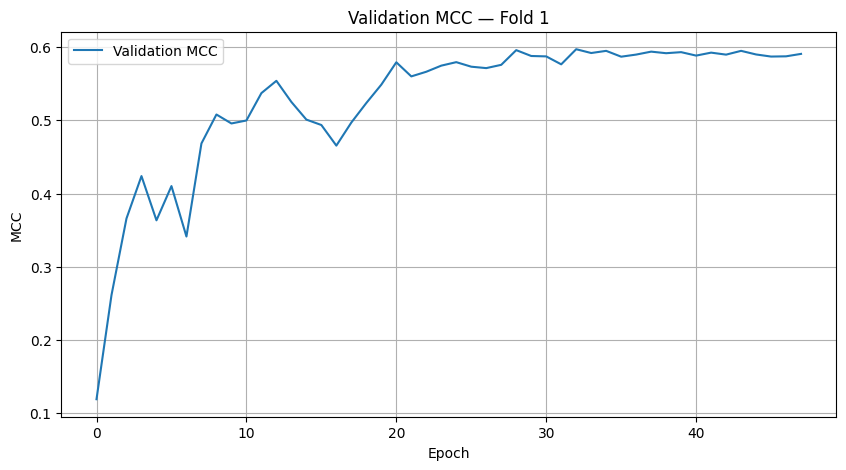

In [ ]:
# График обучения ResNet на 1 фолде для MCC:
plt.figure(figsize=(10, 5))

plt.plot(
    history_fold_1['val_mcc'],
    label='Validation MCC'
)

plt.xlabel('Epoch')
plt.ylabel('MCC')
plt.title('Validation MCC — Fold 1')
plt.legend()
plt.grid()
plt.show()

Результат модели на CNN - MCC: 0.4950 ± 0.0601,

Результат модели на ResNet - MCC: 0.6237 ± 0.0740

baseline - MCC: 0.6228 ± 0.0242.

Можем ли мы улучшить результат?

Попробуем "CNN + Transformer" модель

# 8. CNN + Transformer

Схема:

Аудио → (Mel + Delta + Delta-Delta) → [3, 128, 256] → CNN → последовательность временных признаков → Transformer Encoder → Global Average Pooling → Linear → 10 классов

In [ ]:
# Загружаем данные
X_mel_delta = np.load(
    '/content/X_mel_delta.npy'
)

y_mel_delta = np.load(
    '/content/y_mel_delta.npy'
)

mel_delta_metadata = pd.read_csv(
    '/content/UrbanSound8K_mel_delta_metadata.csv'
)

print('X:', X_mel_delta.shape)
print('y:', y_mel_delta.shape)
print('metadata:', mel_delta_metadata.shape)

In [ ]:
# Dataset
class UrbanSoundDataset(Dataset):

    def __init__(self, X, y, augment=False):

        self.X = X
        self.y = y
        self.augment = augment

    def __len__(self):

        return len(self.X)

    def __getitem__(self, index):

        x = torch.tensor(
            self.X[index],
            dtype=torch.float32
        )

        y = torch.tensor(
            self.y[index],
            dtype=torch.long
        )

        if self.augment:

            # -------------------------
            # Time masking
            # -------------------------

            time_mask = np.random.randint(
                0,
                30
            )

            if time_mask > 0:

                time_start = np.random.randint(
                    0,
                    x.shape[-1] - time_mask + 1
                )

                x[
                    :,
                    :,
                    time_start:time_start + time_mask
                ] = 0

            # -------------------------
            # Frequency masking
            # -------------------------

            freq_mask = np.random.randint(
                0,
                15
            )

            if freq_mask > 0:

                freq_start = np.random.randint(
                    0,
                    x.shape[-2] - freq_mask + 1
                )

                x[
                    :,
                    freq_start:freq_start + freq_mask,
                    :
                ] = 0

        return x, y

Архитектура CNN + Transformer:

Нам нужно превратить [batch, 3, 128, 256] после CNN в [batch, 128, 16, 32],

затем переставляем оси [batch, 32, 128, 16],

затем перемножаем 128 × 16 и подаём в Linear(2048 → 128), получив  [batch, 32, 128] подаём в Transformer,

затем mean по 32 временным шагам и потом классификатор [batch, 10]

In [ ]:
# CNN + Transformer модель
class CNNTransformer(nn.Module):

    def __init__(
        self,
        num_classes=10,
        d_model=128,
        nhead=4,
        num_layers=2,
        dim_feedforward=256,
        dropout=0.2
    ):

        super().__init__()

        # =====================================
        # CNN
        # =====================================

        self.cnn = nn.Sequential(

            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.MaxPool2d(2)
        )

          # =====================================
        # CNN output:
        #
        # [batch, 128, 16, 32]
        #
        # Для каждого из 32 временных
        # участков есть:
        #
        # 128 × 16 = 2048 признаков
        # =====================================

        self.projection = nn.Linear(128 * 16, d_model)

        # =====================================
        # Positional Encoding
        # =====================================

        self.positional_encoding = nn.Parameter(torch.zeros(1, 32, d_model))

        # =====================================
        # Transformer Encoder
        # =====================================

        encoder_layer = (
            nn.TransformerEncoderLayer(
                d_model=d_model,
                nhead=nhead,
                dim_feedforward=dim_feedforward,
                dropout=dropout,
                activation='gelu',
                batch_first=True,
                norm_first=True
            )
        )

        self.transformer = (
            nn.TransformerEncoder(
                encoder_layer,
                num_layers=num_layers
            )
        )

           # =====================================
        # Classifier
        # =====================================

        self.classifier = nn.Sequential(

            nn.LayerNorm(d_model),

            nn.Linear(
                d_model,
                64
            ),

            nn.GELU(),

            nn.Dropout(0.3),

            nn.Linear(
                64,
                num_classes
            )
        )

    def forward(self, x):

        # =====================================
        # CNN
        # =====================================

        x = self.cnn(x)

        # x:
        # [B, 128, 16, 32]

        # =====================================
        # Переставляем измерения
        # =====================================

        x = x.permute(0, 3, 1, 2)

        # [B, 32, 128, 16]

        # =====================================
        # Объединяем frequency + channels
        # =====================================

        x = x.reshape(x.size(0), x.size(1), -1)

        # [B, 32, 2048]

        # =====================================
        # Projection
        # =====================================

        x = self.projection(x)

        # [B, 32, 128]

        # =====================================
        # Positional Encoding
        # =====================================

        x = (x + self.positional_encoding)

        # =====================================
        # Transformer
        # =====================================

        x = self.transformer(x)

        # [B, 32, 128]

        # =====================================
        # Global Average Pooling
        # =====================================

        x = x.mean(dim=1)

        # [B, 128]

        # =====================================
        # Classification
        # =====================================

        x = self.classifier(x)

        return x

In [ ]:
# Проверим модель перед обучением
device = torch.device(
    'cuda'
    if torch.cuda.is_available()
    else 'cpu'
)

model = CNNTransformer(num_classes=10).to(device)

In [ ]:
test_dataset = UrbanSoundDataset(X_mel_delta[:8], y_mel_delta[:8])

test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False)

X_batch, y_batch = next(iter(test_loader))

X_batch = X_batch.to(device)

print('Input:', X_batch.shape)

Input: torch.Size([8, 3, 128, 256])


In [ ]:
with torch.no_grad():

    output = model(X_batch)

print('Output:', output.shape)

Output: torch.Size([8, 10])


In [ ]:
# Training function
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0

    all_preds = []
    all_targets = []

    for X_batch, y_batch in loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        outputs = model(X_batch)

        loss = criterion(outputs, y_batch)

        loss.backward()

        optimizer.step()

        running_loss += (loss.item() * X_batch.size(0))

        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.detach().cpu().numpy())

        all_targets.extend(y_batch.detach().cpu().numpy())

    epoch_loss = (running_loss / len(loader.dataset))

    epoch_accuracy = accuracy_score(all_targets, all_preds)

    return (epoch_loss, epoch_accuracy)

In [ ]:
# Evaluation
def evaluate(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0

    all_preds = []
    all_targets = []

    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            outputs = model(X_batch)

            loss = criterion(outputs, y_batch)

            running_loss += (loss.item() * X_batch.size(0))

            preds = outputs.argmax(dim=1)

            all_preds.extend(preds.cpu().numpy())

            all_targets.extend(y_batch.cpu().numpy())

    epoch_loss = (running_loss / len(loader.dataset))

    epoch_accuracy = accuracy_score(all_targets, all_preds)

    epoch_f1 = f1_score(all_targets, all_preds, average='macro')

    epoch_mcc = matthews_corrcoef(all_targets, all_preds)

    return (
        epoch_loss,
        epoch_accuracy,
        epoch_f1,
        epoch_mcc,
        np.array(all_targets),
        np.array(all_preds)
    )

In [ ]:
# Параметры
BATCH_SIZE = 32
NUM_EPOCHS = 80
LEARNING_RATE = 0.0005
WEIGHT_DECAY = 1e-4
NUM_CLASSES = 10
PATIENCE = 15

In [ ]:
# 10-fold Cross-Validation
cv_results = []

all_cv_targets = []
all_cv_predictions = []

fold_histories = []

for test_fold in range(1, 11):

    print()
    print('=' * 60)
    print(f'TEST FOLD: {test_fold}')
    print('=' * 60)

    # Следующий оригинальный fold
    # используется как validation
    validation_fold = (test_fold % 10) + 1

    print(f'Validation fold: {validation_fold}')

    # =====================================
    # Masks
    # =====================================

    test_mask = (
        mel_delta_metadata['fold']
        == test_fold
    ).to_numpy()

    validation_mask = (
        mel_delta_metadata['fold']
        == validation_fold
    ).to_numpy()

    train_mask = (
        (mel_delta_metadata['fold'] != test_fold)
        &
        (mel_delta_metadata['fold'] != validation_fold)
    ).to_numpy()

       # =====================================
    # Data
    # =====================================

    X_train = X_mel_delta[train_mask]

    y_train = y_mel_delta[train_mask]

    X_val = X_mel_delta[validation_mask]

    y_val = y_mel_delta[validation_mask]

    X_test = X_mel_delta[test_mask]

    y_test = y_mel_delta[test_mask]

    print(f'Train: {len(X_train)}')

    print(f'Validation: {len(X_val)}')

    print(f'Test: {len(X_test)}')

    # =====================================
    # Dataset
    # =====================================

    train_dataset = UrbanSoundDataset(X_train, y_train, augment=True)

    validation_dataset = UrbanSoundDataset(X_val, y_val, augment=False)

    test_dataset = UrbanSoundDataset(X_test, y_test, augment=False)

     # =====================================
    # DataLoader
    # =====================================

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    validation_loader = DataLoader(
        validation_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    # =====================================
    # Model
    # =====================================

    model = CNNTransformer(
        num_classes=NUM_CLASSES,
        d_model=128,
        nhead=4,
        num_layers=2,
        dim_feedforward=256,
        dropout=0.2
    ).to(device)

    # =====================================
    # Class weights
    # =====================================

    class_counts = np.bincount(
        y_train,
        minlength=NUM_CLASSES
    )

    class_weights = (
        len(y_train)
        /
        (
            NUM_CLASSES
            * class_counts
        )
    )

    class_weights = torch.tensor(
        class_weights,
        dtype=torch.float32
    ).to(device)

    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )

       # =====================================
    # Optimizer
    # =====================================

    optimizer = optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    # =====================================
    # Scheduler
    # =====================================

    scheduler = (
        optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode='max',
            factor=0.5,
            patience=2
        )
    )

    # =====================================
    # Best model
    # =====================================

    best_val_mcc = -1.0

    best_epoch = 0

    best_state = None

    epochs_without_improvement = 0

    history = []

      # =====================================
    # Training
    # =====================================

    for epoch in range(NUM_EPOCHS):

        train_loss, train_acc = (
            train_one_epoch(
                model,
                train_loader,
                criterion,
                optimizer,
                device
            )
        )

        (
            val_loss,
            val_acc,
            val_f1,
            val_mcc,
            _,
            _
        ) = evaluate(
            model,
            validation_loader,
            criterion,
            device
        )

        scheduler.step(val_mcc)

        current_lr = (optimizer.param_groups[0]['lr'])

        history.append({
            'epoch': epoch + 1,
            'train_loss': train_loss,
            'train_accuracy': train_acc,
            'val_loss': val_loss,
            'val_accuracy': val_acc,
            'val_f1': val_f1,
            'val_mcc': val_mcc,
            'lr': current_lr
        })

        print(
            f'Epoch {epoch + 1:02d} | '
            f'Train loss: {train_loss:.4f} | '
            f'Val MCC: {val_mcc:.4f}'
        )

           # =================================
        # Best model
        # =================================

        if val_mcc > best_val_mcc:

            best_val_mcc = val_mcc

            best_epoch = (epoch + 1)

            best_state = deepcopy(model.state_dict())

            epochs_without_improvement = 0

        else:

            epochs_without_improvement += 1

        # =================================
        # Early stopping
        # =================================

        if (
            epochs_without_improvement
            >= PATIENCE
        ):

            print('Early stopping')

            break

    # =====================================
    # Загружаем лучшую модель
    # =====================================

    model.load_state_dict(best_state)

     # =====================================
    # Test
    # =====================================

    (
        test_loss,
        test_acc,
        test_f1,
        test_mcc,
        y_true,
        y_pred
    ) = evaluate(
        model,
        test_loader,
        criterion,
        device
    )

    print()
    print(f'Best epoch: {best_epoch}')

    print(f'Best validation MCC: 'f'{best_val_mcc:.4f}')

    print(f'Test Accuracy: 'f'{test_acc:.4f}')

    print(f'Test F1: 'f'{test_f1:.4f}')

    print(f'Test MCC: 'f'{test_mcc:.4f}')

      # =====================================
    # Сохраняем результат fold
    # =====================================

    cv_results.append({

        'test_fold':
            test_fold,

        'validation_fold':
            validation_fold,

        'best_epoch':
            best_epoch,

        'best_val_mcc':
            best_val_mcc,

        'test_accuracy':
            test_acc,

        'test_f1_macro':
            test_f1,

        'test_mcc':
            test_mcc
    })

    all_cv_targets.extend(y_true)

    all_cv_predictions.extend(y_pred)

    fold_histories.append(pd.DataFrame(history))


TEST FOLD: 1
Validation fold: 2
Train: 6971
Validation: 888
Test: 873
Epoch 01 | Train loss: 2.2985 | Val MCC: 0.0609
Epoch 02 | Train loss: 2.0820 | Val MCC: 0.2653
Epoch 03 | Train loss: 1.8883 | Val MCC: 0.2889
Epoch 04 | Train loss: 1.6969 | Val MCC: 0.3581
Epoch 05 | Train loss: 1.5828 | Val MCC: 0.3758
Epoch 06 | Train loss: 1.4381 | Val MCC: 0.4176
Epoch 07 | Train loss: 1.3963 | Val MCC: 0.4100
Epoch 08 | Train loss: 1.3189 | Val MCC: 0.4426
Epoch 09 | Train loss: 1.2276 | Val MCC: 0.4292
Epoch 10 | Train loss: 1.1680 | Val MCC: 0.4651
Epoch 11 | Train loss: 1.1184 | Val MCC: 0.5055
Epoch 12 | Train loss: 1.0309 | Val MCC: 0.4898
Epoch 13 | Train loss: 0.9977 | Val MCC: 0.5257
Epoch 14 | Train loss: 0.9443 | Val MCC: 0.4933
Epoch 15 | Train loss: 0.8925 | Val MCC: 0.5166
Epoch 16 | Train loss: 0.8672 | Val MCC: 0.4902
Epoch 17 | Train loss: 0.7537 | Val MCC: 0.5471
Epoch 18 | Train loss: 0.7021 | Val MCC: 0.5357
Epoch 19 | Train loss: 0.6563 | Val MCC: 0.5632
Epoch 20 | Train 

In [ ]:
# Итоговые результаты
cv_results_df = pd.DataFrame(cv_results)

print(
    f"Accuracy: "
    f"{cv_results_df['test_accuracy'].mean():.4f} "
    f"± "
    f"{cv_results_df['test_accuracy'].std():.4f}"
)

print(
    f"F1 Macro: "
    f"{cv_results_df['test_f1_macro'].mean():.4f} "
    f"± "
    f"{cv_results_df['test_f1_macro'].std():.4f}"
)

print(
    f"MCC: "
    f"{cv_results_df['test_mcc'].mean():.4f} "
    f"± "
    f"{cv_results_df['test_mcc'].std():.4f}"
)

Accuracy: 0.6764 ± 0.0599
F1 Macro: 0.6919 ± 0.0500
MCC: 0.6405 ± 0.0667


In [ ]:
# Сохраняем результаты
cv_results_df.to_csv(
    '/content/cv_transformer_df.csv',
    index=False
)

In [ ]:
# Загружаем результаты по 10 folds ResNet
df_10fold_transformer = pd.read_csv('/content/cv_transformer_df.csv')
df_10fold_transformer

,test_fold,validation_fold,best_epoch,best_val_mcc,test_accuracy,test_f1_macro,test_mcc
0,1,2,39,0.590637,0.648339,0.670021,0.611901
1,2,3,24,0.594709,0.626126,0.646619,0.591834
2,3,4,63,0.655866,0.565405,0.611382,0.513826
3,4,5,51,0.782508,0.697980,0.701524,0.661491
4,5,6,80,0.671372,0.769231,0.775041,0.742730
5,6,7,75,0.683175,0.671932,0.685228,0.634294
6,7,8,65,0.628403,0.669451,0.685161,0.630430
7,8,9,65,0.741948,0.663772,0.680268,0.625521
8,9,10,64,0.686850,0.761029,0.771279,0.736613
9,10,1,33,0.660529,0.690562,0.692469,0.656520


In [ ]:
# Преобразуем в новый датафрейм
accuracy_mean = df_10fold_transformer['test_accuracy'].mean()
accuracy_std = df_10fold_transformer['test_accuracy'].std()

f1_mean = df_10fold_transformer['test_f1_macro'].mean()
f1_std = df_10fold_transformer['test_f1_macro'].std()

mcc_mean = df_10fold_transformer['test_mcc'].mean()
mcc_std = df_10fold_transformer['test_mcc'].std()

In [ ]:
df_grade_mean_transformer = pd.DataFrame({
    'model': ['CNN+Transformer'],
    'accuracy_mean': [accuracy_mean],
    'accuracy_std': [accuracy_std],
    'f1_mean': [f1_mean],
    'f1_std': [f1_std],
    'mcc_mean': [mcc_mean],
    'mcc_std': [mcc_std],
}).round(4)
df_grade_mean_transformer

,model,accuracy_mean,accuracy_std,f1_mean,f1_std,mcc_mean,mcc_std
0,CNN+Transformer,0.6764,0.0599,0.6919,0.05,0.6405,0.0667


In [ ]:
# Confusion Matrix
class_names = [
    'air_conditioner',
    'car_horn',
    'children_playing',
    'dog_bark',
    'drilling',
    'engine_idling',
    'gun_shot',
    'jackhammer',
    'siren',
    'street_music'
]

all_cv_targets = np.array(all_cv_targets)

all_cv_predictions = np.array(all_cv_predictions)

cm = confusion_matrix(all_cv_targets, all_cv_predictions)

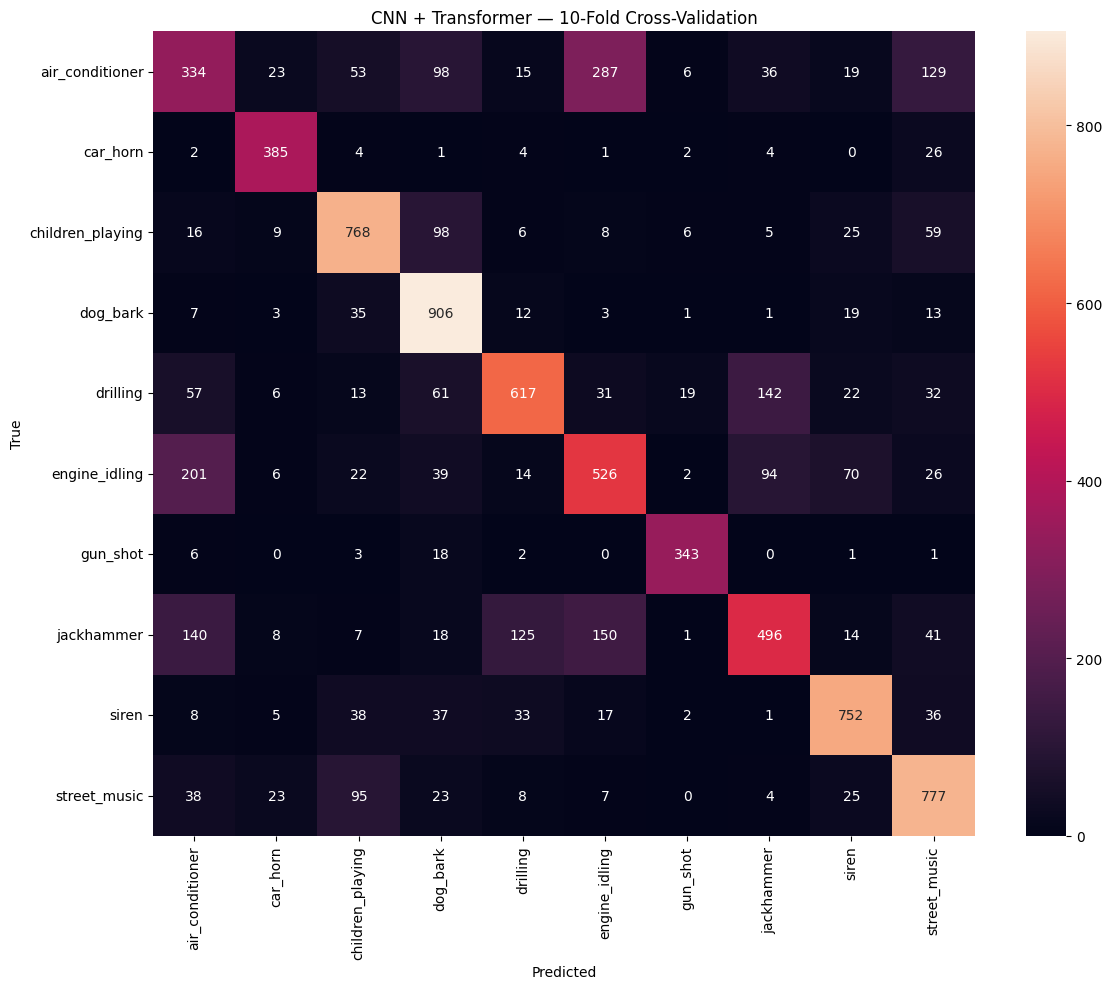

In [ ]:
plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('CNN + Transformer — ''10-Fold Cross-Validation')
plt.tight_layout()
plt.show()

In [ ]:
# Classification Report
print(
    classification_report(
        all_cv_targets,
        all_cv_predictions,
        target_names=class_names
    )
)

                  precision    recall  f1-score   support

 air_conditioner       0.41      0.33      0.37      1000
        car_horn       0.82      0.90      0.86       429
children_playing       0.74      0.77      0.75      1000
        dog_bark       0.70      0.91      0.79      1000
        drilling       0.74      0.62      0.67      1000
   engine_idling       0.51      0.53      0.52      1000
        gun_shot       0.90      0.92      0.91       374
      jackhammer       0.63      0.50      0.56      1000
           siren       0.79      0.81      0.80       929
    street_music       0.68      0.78      0.73      1000

        accuracy                           0.68      8732
       macro avg       0.69      0.70      0.70      8732
    weighted avg       0.67      0.68      0.67      8732



In [ ]:
# Переводим в DataFrame
cr_transformer = classification_report(all_cv_targets,
        all_cv_predictions,
        target_names=class_names, output_dict=True)


cr_transformer_df = pd.DataFrame(cr_transformer)

In [ ]:
# Сохраняем результаты Classification Report
cr_transformer_df.to_csv(
    '/content/df_class_rep_transformer.csv',
    index=False
)

In [ ]:
# Загружаем Classification Report
df_class_rep_transformer = pd.read_csv('/content/df_class_rep_transformer.csv').round(4)
df_class_rep_transformer['support'] = df_class_rep_transformer['support'].astype(int)
df_class_rep_transformer.index = df_class_rep_transformer.index + 1
df_class_rep_transformer

,class,precision,recall,f1-score,support
1,air_conditioner,0.4134,0.3304,0.3721,1000
2,car_horn,0.8260,0.9007,0.8675,429
3,children_playing,0.7459,0.7750,0.7502,1000
4,dog_bark,0.7037,0.9100,0.7968,1000
5,drilling,0.7411,0.6200,0.6746,1000
6,engine_idling,0.5114,0.5300,0.5245,1000
7,gun_shot,0.9004,0.9204,0.9104,374
8,jackhammer,0.6352,0.5000,0.5612,1000
9,siren,0.7935,0.8169,0.8017,929
10,street_music,0.6823,0.7800,0.7301,1000


In [ ]:
# График обучения
history_fold_1 = fold_histories[0]

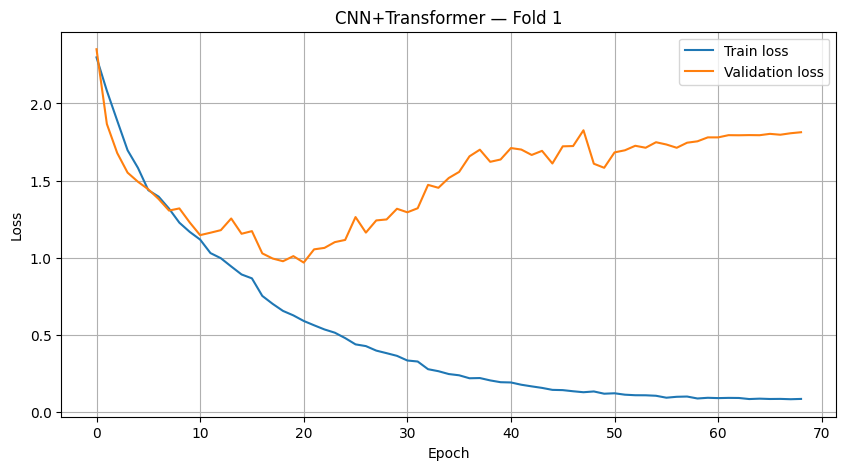

In [ ]:
# Loss
plt.figure(figsize=(10, 5))
plt.plot(history_fold_1['train_loss'], label='Train loss')
plt.plot(history_fold_1['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('CNN+Transformer — Fold 1')
plt.legend()
plt.grid()
plt.show()

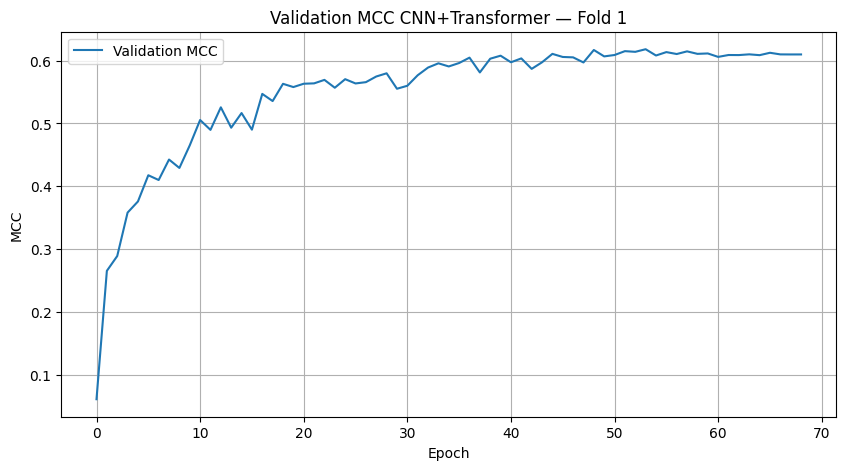

In [ ]:
# MCC
plt.figure(figsize=(10, 5))

plt.plot(history_fold_1['val_mcc'], label='Validation MCC')
plt.xlabel('Epoch')
plt.ylabel('MCC')
plt.title('Validation MCC CNN+Transformer — Fold 1')
plt.legend()
plt.grid()
plt.show()

Мы вышли на неплохой результат в модели "CNN + Transformer" MCC: 0.6405 ± 0.0667
лучше модели "Baseline" и модели "ResNet".

Посмотрим на результаты всех моделей.

In [ ]:
result = pd.concat([df_grade_mean_ml, df_grade_mean_cnn, df_grade_mean_resnet, df_grade_mean_transformer],ignore_index=True)
result.index = result.index + 1
result

,model,accuracy_mean,accuracy_std,f1_mean,f1_std,mcc_mean,mcc_std
1,Logistic Regression,0.6246,0.0507,0.6351,0.0535,0.5809,0.0567
2,Random Forest,0.6613,0.0212,0.6691,0.0228,0.6228,0.0242
3,SVM,0.6586,0.0587,0.6667,0.0625,0.6202,0.0648
4,CNN,0.5449,0.0535,0.5549,0.0596,0.4950,0.0601
5,ResNet,0.6601,0.0663,0.6641,0.0686,0.6237,0.0740
6,CNN+Transformer,0.6764,0.0599,0.6919,0.0500,0.6405,0.0667


In [ ]:
# Расставим по местам
result_place = result.sort_values(by='mcc_mean', ascending=False).reset_index(drop=True)
result_place.index = result_place.index + 1
result_place

,model,accuracy_mean,accuracy_std,f1_mean,f1_std,mcc_mean,mcc_std
1,CNN+Transformer,0.6764,0.0599,0.6919,0.0500,0.6405,0.0667
2,ResNet,0.6601,0.0663,0.6641,0.0686,0.6237,0.0740
3,Random Forest,0.6613,0.0212,0.6691,0.0228,0.6228,0.0242
4,SVM,0.6586,0.0587,0.6667,0.0625,0.6202,0.0648
5,Logistic Regression,0.6246,0.0507,0.6351,0.0535,0.5809,0.0567
6,CNN,0.5449,0.0535,0.5549,0.0596,0.4950,0.0601


Попробуем применить ещё одну модель.

# 9. Stacked Spectral Features + BiLSTM

Сделаем полноценный эксперимент: извлечение нескольких видов аудиопризнаков, их объединение, обучение двунаправленной LSTM и оценка по всем 10 фолдам.

a) STACKING. Извлечение признаков для каждого временного кадра:
Log-Mel(128 признаков) + MFCC(20 признаков) + Spectral Contrast(7 признаков)

Итого: 155 признаков на кадр

b) BiLSTM - Изучает временные зависимости в обоих направлениях

c) Полносвязный классификатор - 10 классов звуков

Log-Mel описывает распределение энергии по частотам,

MFCC — форму спектральной огибающей,

 а Spectral Contrast — различия между пиками и впадинами спектра.

 BiLSTM использует последовательность этих признаков, чтобы учитывать, как звук меняется во времени.

In [ ]:
# Подготовим константы
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство:", device)

# Пути к данным
DATA_DIR = "/content/UrbanSound8K_audio"
CSV_PATH = "/content/UrbanSound8K.csv"

# Параметры извлечения признаков
SAMPLE_RATE = 22050
N_FFT = 2048
HOP_LENGTH = 512
N_MELS = 128
N_MFCC = 20
MAX_FRAMES = 180

# Параметры модели
BATCH_SIZE = 32
HIDDEN_SIZE = 128
NUM_LAYERS = 2
DROPOUT = 0.3
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
EPOCHS = 80
PATIENCE = 16
NUM_CLASSES = 10

print("Количество классов:", NUM_CLASSES)

Устройство: cuda
Количество классов: 10


In [ ]:
# Извлекаем и объединяем признаки
metadata = pd.read_csv(CSV_PATH)

print(metadata.head())
print("Размер таблицы:", metadata.shape)
print("Колонки:", metadata.columns.tolist())

      slice_file_name    fsID  start        end  salience  fold  classID  \
0    100032-3-0-0.wav  100032    0.0   0.317551         1     5        3   
1  100263-2-0-117.wav  100263   58.5  62.500000         1     5        2   
2  100263-2-0-121.wav  100263   60.5  64.500000         1     5        2   
3  100263-2-0-126.wav  100263   63.0  67.000000         1     5        2   
4  100263-2-0-137.wav  100263   68.5  72.500000         1     5        2   

              class  
0          dog_bark  
1  children_playing  
2  children_playing  
3  children_playing  
4  children_playing  
Размер таблицы: (8732, 8)
Колонки: ['slice_file_name', 'fsID', 'start', 'end', 'salience', 'fold', 'classID', 'class']


In [ ]:
# Функция формирует путь к WAV и рассчитывает признаки
def extract_stacked_features(filepath):
    """
    Возвращает матрицу [MAX_FRAMES, 155]:
    128 Log-Mel + 20 MFCC + 7 Spectral Contrast.
    """

    y, sr = librosa.load(
        filepath,
        sr=SAMPLE_RATE,
        mono=True
    )

    # Защита от пустых аудиофайлов
    if len(y) == 0:
        raise ValueError(f"Пустой аудиофайл: {filepath}")

    # 1. Log-Mel: [128, T]
    mel = librosa.feature.melspectrogram(
        y=y,
        sr=sr,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        power=2.0
    )

    log_mel = librosa.power_to_db(
        mel,
        ref=np.max
    )

    # 2. MFCC: [20, T]
    mfcc = librosa.feature.mfcc(
        y=y,
        sr=sr,
        n_mfcc=N_MFCC,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH
    )

    # 3. Spectral Contrast: [7, T]
    contrast = librosa.feature.spectral_contrast(
        y=y,
        sr=sr,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_bands=6
    )

    # Приводим к виду [T, число признаков]
    log_mel = log_mel.T
    mfcc = mfcc.T
    contrast = contrast.T

    # Выравниваем число временных кадров
    min_frames = min(
        len(log_mel),
        len(mfcc),
        len(contrast)
    )

    log_mel = log_mel[:min_frames]
    mfcc = mfcc[:min_frames]
    contrast = contrast[:min_frames]

    # Stacking: объединяем признаки по последней оси
    features = np.concatenate(
        [log_mel, mfcc, contrast],
        axis=1
    ).astype(np.float32)

    # Фиксированная длина последовательности
    if len(features) > MAX_FRAMES:
        features = features[:MAX_FRAMES]

    elif len(features) < MAX_FRAMES:
        pad_len = MAX_FRAMES - len(features)

        features = np.pad(
            features,
            pad_width=((0, pad_len), (0, 0)),
            mode="edge"
        )

    return features

In [ ]:
# проверим один файл до запуска полного извлечения:
row = metadata.iloc[0]

sample_path = os.path.join(
    DATA_DIR,
    row["slice_file_name"]
)

sample_features = extract_stacked_features(sample_path)

print("Файл:", sample_path)
print("Форма признаков:", sample_features.shape)
print("Ожидаемая форма:", (MAX_FRAMES, 155))
print("Все значения конечны:", np.isfinite(sample_features).all())

Файл: /content/UrbanSound8K_audio/100032-3-0-0.wav
Форма признаков: (180, 155)
Ожидаемая форма: (180, 155)
Все значения конечны: True


In [ ]:
DATA_DIR = "/content/UrbanSound8K_audio"
CSV_PATH = "/content/UrbanSound8K.csv"

metadata = pd.read_csv(CSV_PATH)

print("Колонки CSV:", metadata.columns.tolist())
print("Количество строк:", len(metadata))
print("\nПервые имена файлов:")
print(metadata["slice_file_name"].head().tolist())

print("\nСодержимое DATA_DIR:")
print(os.listdir(DATA_DIR)[:20])

# Ищем WAV-файлы в папке и подпапках
wav_files = glob.glob(
    os.path.join(DATA_DIR, "**", "*.wav"),
    recursive=True
)

print("\nНайдено WAV-файлов:", len(wav_files))
print("Примеры путей:")
for path in wav_files[:5]:
    print(path)

Колонки CSV: ['slice_file_name', 'fsID', 'start', 'end', 'salience', 'fold', 'classID', 'class']
Количество строк: 8732

Первые имена файлов:
['100032-3-0-0.wav', '100263-2-0-117.wav', '100263-2-0-121.wav', '100263-2-0-126.wav', '100263-2-0-137.wav']

Содержимое DATA_DIR:
['174293-6-1-0.wav', '177726-0-0-34.wav', '55018-0-0-121.wav', '95562-4-1-0.wav', '100795-3-1-0.wav', '7389-1-2-2.wav', '164377-9-1-15.wav', '73524-0-0-113.wav', '94632-5-1-13.wav', '135526-6-8-0.wav', '171388-9-0-88.wav', '77774-4-1-1.wav', '178825-2-0-4.wav', '113202-5-0-20.wav', '197320-6-7-0.wav', '107357-8-0-3.wav', '71866-9-0-21.wav', '189985-0-0-4.wav', '169045-2-0-1.wav', '121286-0-0-9.wav']

Найдено WAV-файлов: 8732
Примеры путей:
/content/UrbanSound8K_audio/174293-6-1-0.wav
/content/UrbanSound8K_audio/177726-0-0-34.wav
/content/UrbanSound8K_audio/55018-0-0-121.wav
/content/UrbanSound8K_audio/95562-4-1-0.wav
/content/UrbanSound8K_audio/100795-3-1-0.wav


In [ ]:
# Создаём индекс: имя WAV-файла -> полный путь
wav_index = {}

for path in wav_files:
    filename = os.path.basename(path)
    wav_index.setdefault(filename, path)

# Проверяем совпадения между CSV и аудио
metadata["filepath"] = metadata["slice_file_name"].map(wav_index)

found_count = metadata["filepath"].notna().sum()
missing_count = metadata["filepath"].isna().sum()

print("Файлов из CSV найдено:", found_count)
print("Файлов отсутствует:", missing_count)

if missing_count > 0:
    print("\nПримеры отсутствующих файлов:")
    print(
        metadata.loc[
            metadata["filepath"].isna(),
            "slice_file_name"
        ].head(10).tolist()
    )

if found_count == 0:
    raise RuntimeError(
        "Не найдено ни одного совпадения. "
        "Проверьте, что DATA_DIR указывает на папку с WAV-файлами."
    )

# Оставляем только строки с существующими файлами
metadata = metadata.loc[
    metadata["filepath"].notna()
].reset_index(drop=True)

print("\nГотово. Файлов для обработки:", len(metadata))

Файлов из CSV найдено: 8732
Файлов отсутствует: 0

Готово. Файлов для обработки: 8732


In [ ]:
sample_path = metadata.loc[0, "filepath"]

sample_features = extract_stacked_features(sample_path)

print("Файл:", sample_path)
print("Форма:", sample_features.shape)
print("Ожидаемая форма:", (MAX_FRAMES, 155))
print("Все значения конечны:", np.isfinite(sample_features).all())

assert sample_features.shape == (MAX_FRAMES, 155)
assert np.isfinite(sample_features).all()

Файл: /content/UrbanSound8K_audio/100032-3-0-0.wav
Форма: (180, 155)
Ожидаемая форма: (180, 155)
Все значения конечны: True


In [ ]:
# извлекаем признаки для всех 8732 файлов
X_PATH = "/content/X_stacked_spectral.npy"
Y_PATH = "/content/y_stacked_spectral.npy"
META_PATH = "/content/stacked_spectral_metadata.csv"

# Удаляем старые пустые результаты
for path in [X_PATH, Y_PATH, META_PATH]:
    if os.path.exists(path):
        os.remove(path)

# Временный массив для всех найденных в CSV файлов
n_samples = len(metadata)

X_memmap = np.lib.format.open_memmap(
    X_PATH,
    mode="w+",
    dtype=np.float32,
    shape=(n_samples, MAX_FRAMES, 155)
)

valid_rows = []
failed_files = []

for i, row in tqdm(
    metadata.iterrows(),
    total=len(metadata),
    desc="Извлечение признаков"
):
    filepath = row["filepath"]

    try:
        features = extract_stacked_features(filepath)

        if (
            features.shape != (MAX_FRAMES, 155)
            or not np.isfinite(features).all()
        ):
            raise ValueError("Неверная форма или NaN/Inf в признаках")

        X_memmap[i] = features
        valid_rows.append(i)

    except Exception as e:
        failed_files.append({
            "filepath": filepath,
            "error": str(e)
        })

X_memmap.flush()
del X_memmap

if len(valid_rows) == 0:
    raise RuntimeError(
        "Ни один файл не обработан. Проверьте ошибки и пути к аудио."
    )

# Сохраняем только успешные примеры
valid_metadata = metadata.iloc[valid_rows].copy().reset_index(drop=True)

X_temp = np.load(X_PATH, mmap_mode="r")

X_valid = np.lib.format.open_memmap(
    "/content/X_stacked_spectral_valid.npy",
    mode="w+",
    dtype=np.float32,
    shape=(len(valid_rows), MAX_FRAMES, 155)
)

for j, original_i in enumerate(valid_rows):
    X_valid[j] = X_temp[original_i]

X_valid.flush()
del X_temp, X_valid

os.replace(
    "/content/X_stacked_spectral_valid.npy",
    X_PATH
)

np.save(
    Y_PATH,
    valid_metadata["classID"].to_numpy(dtype=np.int64)
)

valid_metadata.to_csv(META_PATH, index=False)

# Загружаем готовые данные
X = np.load(X_PATH, mmap_mode="r")
y = np.load(Y_PATH)
meta = pd.read_csv(META_PATH)

print("\nИзвлечение завершено")
print("X:", X.shape)
print("y:", y.shape)
print("Файлов:", len(meta))
print("Фолды:", sorted(meta["fold"].unique()))
print("Ошибок:", len(failed_files))

if failed_files:
    print("\nПервые ошибки:")
    for item in failed_files[:5]:
        print(item["filepath"], "->", item["error"])

Извлечение признаков:   0%|          | 0/8732 [00:00<?, ?it/s]


Извлечение завершено
X: (8732, 180, 155)
y: (8732,)
Файлов: 8732
Фолды: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
Ошибок: 0


In [ ]:
# Создаём Dataset и нормализуем признаки
def calculate_train_stats(X, train_indices, chunk_size=256):
    """Среднее и std каждого признака по обучающим файлам и кадрам."""

    feature_sum = np.zeros(X.shape[2], dtype=np.float64)
    feature_sq_sum = np.zeros(X.shape[2], dtype=np.float64)
    total_frames = 0

    for start in range(0, len(train_indices), chunk_size):
        idx = train_indices[start:start + chunk_size]

        batch = np.asarray(X[idx], dtype=np.float32)
        batch = batch.astype(np.float64)

        feature_sum += batch.sum(axis=(0, 1))
        feature_sq_sum += np.square(batch).sum(axis=(0, 1))
        total_frames += batch.shape[0] * batch.shape[1]

    mean = feature_sum / total_frames
    variance = feature_sq_sum / total_frames - mean ** 2
    std = np.sqrt(np.maximum(variance, 1e-8))

    # Защита от деления на слишком маленькое значение
    std[std < 1e-6] = 1.0

    return mean.astype(np.float32), std.astype(np.float32)


class StackedSpectralDataset(Dataset):
    def __init__(self, X, y, indices, mean, std):
        self.X = X
        self.y = y
        self.indices = np.asarray(indices)
        self.mean = mean
        self.std = std

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        real_idx = self.indices[idx]

        # X имеет форму [T, 155]
        features = np.array(
            self.X[real_idx],
            dtype=np.float32,
            copy=True
        )

        features = (features - self.mean) / self.std

        # Ограничиваем экстремальные значения после нормализации
        features = np.clip(features, -8.0, 8.0)

        label = int(self.y[real_idx])

        return (
            torch.from_numpy(features),
            torch.tensor(label, dtype=torch.long))

In [ ]:
# Реализуем BiLSTM - использует два направления:
#  от начала звука к концу и от конца к началу.
# Это помогает учитывать контекст временных кадров с обеих сторон.
class StackedSpectralBiLSTM(nn.Module):
    def __init__(
        self,
        input_size=155,
        hidden_size=128,
        num_layers=2,
        num_classes=10,
        dropout=0.3
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0
        )

        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_size * 2, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        # x: [B, T, 155]
        _, (h_n, _) = self.lstm(x)

        # Последний слой BiLSTM:
        # h_n[-2] — последнее состояние прямого направления
        # h_n[-1] — последнее состояние обратного направления
        forward_state = h_n[-2]
        backward_state = h_n[-1]

        # [B, 256], если hidden_size=128
        representation = torch.cat(
            [forward_state, backward_state],
            dim=1
        )

        # [B, 10] — оценки для 10 классов
        return self.classifier(representation)


model = StackedSpectralBiLSTM().to(device)

dummy = torch.randn(4, MAX_FRAMES, 155).to(device)

with torch.no_grad():
    output = model(dummy)

print("Вход:", dummy.shape)
print("Выход:", output.shape)
print("Количество параметров:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Вход: torch.Size([4, 180, 155])
Выход: torch.Size([4, 10])
Количество параметров: 721290


In [ ]:
# Функции обучения и оценки
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()

    total_loss = 0.0
    n_samples = 0

    for features, labels in loader:
        features = features.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        logits = model(features)
        loss = criterion(logits, labels)

        loss.backward()

        # Стабилизируем обучение рекуррентной сети
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        n_samples += batch_size

    return total_loss / max(n_samples, 1)


@torch.no_grad()
def evaluate_model(model, loader, criterion=None):
    model.eval()

    all_targets = []
    all_predictions = []
    total_loss = 0.0
    n_samples = 0

    for features, labels in loader:
        features = features.to(device)
        labels = labels.to(device)

        logits = model(features)

        if criterion is not None:
            loss = criterion(logits, labels)
            total_loss += loss.item() * labels.size(0)

        predictions = logits.argmax(dim=1)

        all_targets.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        n_samples += labels.size(0)

    targets = np.asarray(all_targets)
    predictions = np.asarray(all_predictions)

    metrics = {
        "accuracy": accuracy_score(targets, predictions),
        "f1_macro": f1_score(
            targets, predictions,
            average="macro",
            zero_division=0
        ),
        "mcc": matthews_corrcoef(targets, predictions)
    }

    if criterion is not None:
        metrics["loss"] = total_loss / max(n_samples, 1)

    return metrics, targets, predictions

In [ ]:
# Запускаем 10-fold cross-validation
cv_results = []
all_cv_targets = []
all_cv_predictions = []
fold_histories = []

for test_fold in tqdm(range(1, 11)):

    validation_fold = (test_fold % 10) + 1

    folds = meta["fold"].to_numpy()

    test_indices = np.where(folds == test_fold)[0]
    val_indices = np.where(folds == validation_fold)[0]
    train_indices = np.where((folds != test_fold) & (folds != validation_fold))[0]

    print("\n" + "=" * 65)
    print(
        f"TEST fold: {test_fold} | "
        f"VALIDATION fold: {validation_fold}"
    )
    print(
        f"Train: {len(train_indices)} | "
        f"Validation: {len(val_indices)} | "
        f"Test: {len(test_indices)}"
    )

    # Статистики только по обучающим данным
    mean, std = calculate_train_stats(X, train_indices)

    train_dataset = StackedSpectralDataset(X, y, train_indices, mean, std)
    val_dataset = StackedSpectralDataset(X, y, val_indices, mean, std)
    test_dataset = StackedSpectralDataset(X, y, test_indices, mean, std)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )
    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    # Веса классов рассчитываем только по обучающим меткам
    class_counts = np.bincount(y[train_indices], minlength=NUM_CLASSES)
    class_weights = np.zeros(NUM_CLASSES, dtype=np.float32)
    present = class_counts > 0

    class_weights[present] = (
        len(train_indices)
        / (NUM_CLASSES * class_counts[present])
    )

    criterion = nn.CrossEntropyLoss(
        weight=torch.tensor(
            class_weights,
            dtype=torch.float32,
            device=device
        )
    )

    model = StackedSpectralBiLSTM(
        input_size=155,
        hidden_size=HIDDEN_SIZE,
        num_layers=NUM_LAYERS,
        num_classes=NUM_CLASSES,
        dropout=DROPOUT
    ).to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=2
    )

    best_val_mcc = -np.inf
    best_state = None
    epochs_without_improvement = 0
    history = []

    for epoch in range(1, EPOCHS + 1):

        train_loss = train_one_epoch(
            model,
            train_loader,
            optimizer,
            criterion
        )

        val_metrics, _, _ = evaluate_model(
            model,
            val_loader,
            criterion
        )

        scheduler.step(val_metrics["mcc"])

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_f1_macro": val_metrics["f1_macro"],
            "val_mcc": val_metrics["mcc"]
        })

        print(
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"loss={train_loss:.4f} | "
            f"val_MCC={val_metrics['mcc']:.4f} | "
            f"val_F1={val_metrics['f1_macro']:.4f}"
        )

        if val_metrics["mcc"] > best_val_mcc:
            best_val_mcc = val_metrics["mcc"]
            best_state = deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            print("Early stopping.")
            break

    # Сохраняем веса лучшей эпохи этого фолда
    checkpoint_path = (
        f"/content/stacked_spectral_bilstm_fold{test_fold}.pt"
    )

    torch.save({
        "model_state_dict": best_state,
        "mean": mean,
        "std": std,
        "test_fold": test_fold,
        "validation_fold": validation_fold,
        "input_size": 155,
        "hidden_size": HIDDEN_SIZE,
        "num_layers": NUM_LAYERS,
        "num_classes": NUM_CLASSES
    }, checkpoint_path)

    model.load_state_dict(best_state)

    # Тестируем только после выбора лучшей эпохи
    test_metrics, test_targets, test_predictions = evaluate_model(
        model,
        test_loader,
        criterion
    )

    cv_results.append({
        "test_fold": test_fold,
        "validation_fold": validation_fold,
        "accuracy": test_metrics["accuracy"],
        "f1_macro": test_metrics["f1_macro"],
        "mcc": test_metrics["mcc"],
        "best_val_mcc": best_val_mcc,
        "epochs_trained": len(history)
    })

    all_cv_targets.extend(test_targets)
    all_cv_predictions.extend(test_predictions)
    fold_histories.append(pd.DataFrame(history))

    print(
        f"\nTEST fold {test_fold}: "
        f"Accuracy={test_metrics['accuracy']:.4f} | "
        f"Macro F1={test_metrics['f1_macro']:.4f} | "
        f"MCC={test_metrics['mcc']:.4f}"
    )

    del model, optimizer, scheduler, train_loader, val_loader, test_loader

    results_df = pd.DataFrame(cv_results)

    print("\n" + "=" * 65)
    print("ИТОГОВЫЕ РЕЗУЛЬТАТЫ Stacked Spectral Features + BiLSTM")
    print("=" * 65)

    metrics = ["accuracy", "f1_macro", "mcc"]

    for metric in metrics:
        mean_score = results_df[metric].mean()
        std_score = results_df[metric].std(ddof=0)

        metric_name = {
            "accuracy": "Accuracy",
            "f1_macro": "F1 Macro",
            "mcc": "MCC"
        }[metric]

        print(f"{metric_name}: {mean_score:.4f} ± {std_score:.4f}")


    # Результаты каждого фолда
    print("\nРезультаты по фолдам:")
    display(
        results_df[
            ["test_fold", "accuracy", "f1_macro", "mcc"]
        ].round(4)
    )

    # Сохраняем результаты
    results_df.to_csv(
        "/content/stacked_spectral_bilstm_cv_results.csv",
        index=False
    )

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

  0%|          | 0/10 [00:00<?, ?it/s]


TEST fold: 1 | VALIDATION fold: 2
Train: 6971 | Validation: 888 | Test: 873
Epoch 01/80 | loss=2.0697 | val_MCC=0.3212 | val_F1=0.3407
Epoch 02/80 | loss=1.7260 | val_MCC=0.3799 | val_F1=0.4374
Epoch 03/80 | loss=1.4883 | val_MCC=0.3963 | val_F1=0.4496
Epoch 04/80 | loss=1.3718 | val_MCC=0.4642 | val_F1=0.5242
Epoch 05/80 | loss=1.2302 | val_MCC=0.4504 | val_F1=0.5118
Epoch 06/80 | loss=1.1196 | val_MCC=0.4708 | val_F1=0.5386
Epoch 07/80 | loss=1.0544 | val_MCC=0.4861 | val_F1=0.5439
Epoch 08/80 | loss=1.0057 | val_MCC=0.4469 | val_F1=0.5134
Epoch 09/80 | loss=0.9264 | val_MCC=0.4618 | val_F1=0.5215
Epoch 10/80 | loss=0.8609 | val_MCC=0.4413 | val_F1=0.5102
Epoch 11/80 | loss=0.6948 | val_MCC=0.5412 | val_F1=0.5897
Epoch 12/80 | loss=0.6011 | val_MCC=0.4858 | val_F1=0.5459
Epoch 13/80 | loss=0.5283 | val_MCC=0.4654 | val_F1=0.5306
Epoch 14/80 | loss=0.4791 | val_MCC=0.4927 | val_F1=0.5387
Epoch 15/80 | loss=0.3861 | val_MCC=0.5120 | val_F1=0.5616
Epoch 16/80 | loss=0.3230 | val_MCC=0.

,test_fold,accuracy,f1_macro,mcc
0,1,0.5865,0.5916,0.5421



TEST fold: 2 | VALIDATION fold: 3
Train: 6919 | Validation: 925 | Test: 888
Epoch 01/80 | loss=2.0719 | val_MCC=0.3137 | val_F1=0.3984
Epoch 02/80 | loss=1.7136 | val_MCC=0.3518 | val_F1=0.4362
Epoch 03/80 | loss=1.5529 | val_MCC=0.3759 | val_F1=0.4686
Epoch 04/80 | loss=1.3982 | val_MCC=0.4450 | val_F1=0.5317
Epoch 05/80 | loss=1.2608 | val_MCC=0.4301 | val_F1=0.4993
Epoch 06/80 | loss=1.1465 | val_MCC=0.4346 | val_F1=0.5092
Epoch 07/80 | loss=1.0606 | val_MCC=0.3816 | val_F1=0.4774
Epoch 08/80 | loss=0.9097 | val_MCC=0.4146 | val_F1=0.4942
Epoch 09/80 | loss=0.7816 | val_MCC=0.4355 | val_F1=0.5112
Epoch 10/80 | loss=0.7297 | val_MCC=0.4048 | val_F1=0.4829
Epoch 11/80 | loss=0.6133 | val_MCC=0.4267 | val_F1=0.5064
Epoch 12/80 | loss=0.5598 | val_MCC=0.4430 | val_F1=0.5173
Epoch 13/80 | loss=0.5017 | val_MCC=0.4343 | val_F1=0.5116
Epoch 14/80 | loss=0.4282 | val_MCC=0.4604 | val_F1=0.5372
Epoch 15/80 | loss=0.3951 | val_MCC=0.4700 | val_F1=0.5483
Epoch 16/80 | loss=0.3639 | val_MCC=0.

,test_fold,accuracy,f1_macro,mcc
0,1,0.5865,0.5916,0.5421
1,2,0.5676,0.5739,0.5213


...

,test_fold,accuracy,f1_macro,mcc
0,1,0.5865,0.5916,0.5421
1,2,0.5676,0.5739,0.5213
2,3,0.5254,0.5587,0.4691
3,4,0.6071,0.6052,0.5600
4,5,0.6293,0.6278,0.5886
5,6,0.5553,0.5608,0.5058
6,7,0.6134,0.6103,0.5675
7,8,0.6911,0.7101,0.6552



TEST fold: 9 | VALIDATION fold: 10
Train: 7079 | Validation: 837 | Test: 816
Epoch 01/80 | loss=2.0586 | val_MCC=0.3276 | val_F1=0.3538
Epoch 02/80 | loss=1.7398 | val_MCC=0.3708 | val_F1=0.4275
Epoch 03/80 | loss=1.5164 | val_MCC=0.4207 | val_F1=0.5010
Epoch 04/80 | loss=1.3696 | val_MCC=0.4301 | val_F1=0.5052
Epoch 05/80 | loss=1.2215 | val_MCC=0.4353 | val_F1=0.5134
Epoch 06/80 | loss=1.1440 | val_MCC=0.4827 | val_F1=0.5506
Epoch 07/80 | loss=1.0578 | val_MCC=0.4473 | val_F1=0.5296
Epoch 08/80 | loss=0.9590 | val_MCC=0.5174 | val_F1=0.5886
Epoch 09/80 | loss=0.9049 | val_MCC=0.5118 | val_F1=0.5884
Epoch 10/80 | loss=0.8465 | val_MCC=0.4592 | val_F1=0.5245
Epoch 11/80 | loss=0.7905 | val_MCC=0.5006 | val_F1=0.5749
Epoch 12/80 | loss=0.6867 | val_MCC=0.5534 | val_F1=0.6212
Epoch 13/80 | loss=0.5746 | val_MCC=0.5074 | val_F1=0.5774
Epoch 14/80 | loss=0.5226 | val_MCC=0.4960 | val_F1=0.5716
Epoch 15/80 | loss=0.4667 | val_MCC=0.5158 | val_F1=0.5892
Epoch 16/80 | loss=0.3744 | val_MCC=0

,test_fold,accuracy,f1_macro,mcc
0,1,0.5865,0.5916,0.5421
1,2,0.5676,0.5739,0.5213
2,3,0.5254,0.5587,0.4691
3,4,0.6071,0.6052,0.5600
4,5,0.6293,0.6278,0.5886
5,6,0.5553,0.5608,0.5058
6,7,0.6134,0.6103,0.5675
7,8,0.6911,0.7101,0.6552
8,9,0.6716,0.6921,0.6360



TEST fold: 10 | VALIDATION fold: 1
Train: 7022 | Validation: 873 | Test: 837
Epoch 01/80 | loss=2.0725 | val_MCC=0.3557 | val_F1=0.3937
Epoch 02/80 | loss=1.7509 | val_MCC=0.5009 | val_F1=0.5520
Epoch 03/80 | loss=1.4679 | val_MCC=0.4802 | val_F1=0.5335
Epoch 04/80 | loss=1.3576 | val_MCC=0.5104 | val_F1=0.5527
Epoch 05/80 | loss=1.2585 | val_MCC=0.4919 | val_F1=0.5405
Epoch 06/80 | loss=1.1467 | val_MCC=0.5209 | val_F1=0.5665
Epoch 07/80 | loss=1.0678 | val_MCC=0.5092 | val_F1=0.5742
Epoch 08/80 | loss=1.0077 | val_MCC=0.4872 | val_F1=0.5561
Epoch 09/80 | loss=0.9372 | val_MCC=0.5124 | val_F1=0.5719
Epoch 10/80 | loss=0.7898 | val_MCC=0.4938 | val_F1=0.5492
Epoch 11/80 | loss=0.6781 | val_MCC=0.4893 | val_F1=0.5575
Epoch 12/80 | loss=0.5984 | val_MCC=0.4786 | val_F1=0.5488
Epoch 13/80 | loss=0.4976 | val_MCC=0.5127 | val_F1=0.5769
Epoch 14/80 | loss=0.4359 | val_MCC=0.5104 | val_F1=0.5721
Epoch 15/80 | loss=0.3792 | val_MCC=0.5051 | val_F1=0.5729
Epoch 16/80 | loss=0.3213 | val_MCC=0

,test_fold,accuracy,f1_macro,mcc
0,1,0.5865,0.5916,0.5421
1,2,0.5676,0.5739,0.5213
2,3,0.5254,0.5587,0.4691
3,4,0.6071,0.6052,0.5600
4,5,0.6293,0.6278,0.5886
5,6,0.5553,0.5608,0.5058
6,7,0.6134,0.6103,0.5675
7,8,0.6911,0.7101,0.6552
8,9,0.6716,0.6921,0.6360
9,10,0.6296,0.6560,0.5899



РЕЗУЛЬТАТЫ ПО ФОЛДАМ


,test_fold,validation_fold,accuracy,f1_macro,mcc,best_val_mcc,epochs_trained
0,1,2,0.5865,0.5916,0.5421,0.5412,27
1,2,3,0.5676,0.5739,0.5213,0.5062,42
2,3,4,0.5254,0.5587,0.4691,0.5396,40
3,4,5,0.6071,0.6052,0.5600,0.5907,46
4,5,6,0.6293,0.6278,0.5886,0.5284,52
5,6,7,0.5553,0.5608,0.5058,0.5965,31
6,7,8,0.6134,0.6103,0.5675,0.6490,44
7,8,9,0.6911,0.7101,0.6552,0.6549,48
8,9,10,0.6716,0.6921,0.6360,0.6137,46
9,10,1,0.6296,0.6560,0.5899,0.5335,39



СРЕДНИЕ МЕТРИКИ ПО 10 ФОЛДАМ
accuracy    : 0.6077 ± 0.0512
f1_macro    : 0.6186 ± 0.0529
mcc         : 0.5635 ± 0.0573

Общий MCC по всем тестовым предсказаниям: 0.5606

Отчёт по классам:
                  precision    recall  f1-score   support

 air_conditioner     0.3465    0.2980    0.3204      1000
        car_horn     0.6652    0.7226    0.6927       429
children_playing     0.5159    0.6650    0.5810      1000
        dog_bark     0.6997    0.7690    0.7327      1000
        drilling     0.6256    0.6250    0.6253      1000
   engine_idling     0.6268    0.4300    0.5101      1000
        gun_shot     0.8966    0.9037    0.9001       374
      jackhammer     0.5800    0.4240    0.4899      1000
           siren     0.7074    0.7729    0.7387       929
    street_music     0.5934    0.7180    0.6498      1000

        accuracy                         0.6064      8732
       macro avg     0.6257    0.6328    0.6241      8732
    weighted avg     0.6031    0.6064    0.5989      87

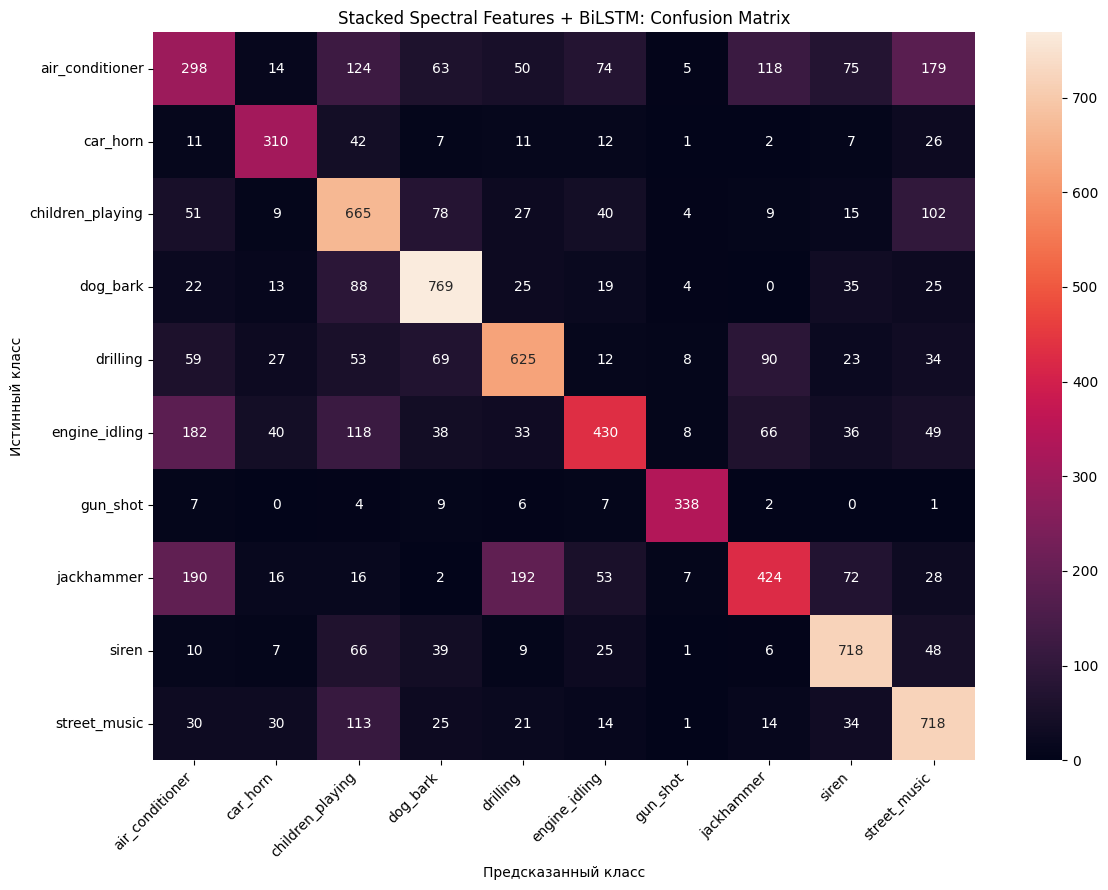

In [ ]:
# Итоговые результаты и сравнение с CNN + Transformer
results_df = pd.DataFrame(cv_results)

results_df.to_csv(
    "/content/stacked_spectral_bilstm_10fold_results.csv",
    index=False
)

print("\nРЕЗУЛЬТАТЫ ПО ФОЛДАМ")
display(results_df.round(4))

print("\nСРЕДНИЕ МЕТРИКИ ПО 10 ФОЛДАМ")

for metric in ["accuracy", "f1_macro", "mcc"]:
    mean_value = results_df[metric].mean()
    std_value = results_df[metric].std(ddof=1)

    print(
        f"{metric:12s}: "
        f"{mean_value:.4f} ± {std_value:.4f}"
    )

# Объединённые предсказания на всех тестовых фолдах
class_names = [
    "air_conditioner",
    "car_horn",
    "children_playing",
    "dog_bark",
    "drilling",
    "engine_idling",
    "gun_shot",
    "jackhammer",
    "siren",
    "street_music"
]

print("\nОбщий MCC по всем тестовым предсказаниям:",
      f"{matthews_corrcoef(all_cv_targets, all_cv_predictions):.4f}")

print("\nОтчёт по классам:")
print(classification_report(
    all_cv_targets,
    all_cv_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    zero_division=0,
    digits=4
))

cm = confusion_matrix(
    all_cv_targets,
    all_cv_predictions,
    labels=np.arange(NUM_CLASSES)
)

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 9))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    # cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.title("Stacked Spectral Features + BiLSTM: Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# Загружаем результаты по 10 folds
df_10fold_lstm = pd.read_csv('/content/stacked_spectral_bilstm_10fold_results.csv')
df_10fold_lstm

,test_fold,validation_fold,accuracy,f1_macro,mcc,best_val_mcc,epochs_trained
0,1,2,0.586483,0.591622,0.542143,0.541227,27
1,2,3,0.567568,0.573934,0.521261,0.506199,42
2,3,4,0.525405,0.558717,0.469109,0.539632,40
3,4,5,0.607071,0.605228,0.559965,0.590750,46
4,5,6,0.629274,0.627757,0.588645,0.528402,52
5,6,7,0.555286,0.560758,0.505790,0.596495,31
6,7,8,0.613365,0.610302,0.567486,0.649005,44
7,8,9,0.691067,0.710104,0.655193,0.654856,48
8,9,10,0.671569,0.692060,0.635988,0.613738,46
9,10,1,0.629630,0.655974,0.589869,0.533549,39


In [ ]:
# Преобразуем в новый датафрейм
accuracy_mean = df_10fold_lstm['accuracy'].mean()
accuracy_std = df_10fold_lstm['accuracy'].std()

f1_mean = df_10fold_lstm['f1_macro'].mean()
f1_std = df_10fold_lstm['f1_macro'].std()

mcc_mean = df_10fold_lstm['mcc'].mean()
mcc_std = df_10fold_lstm['mcc'].std()

In [ ]:
df_grade_mean_lstm = pd.DataFrame({
    'model': ['SSF + BiLSTM'],
    'accuracy_mean': [accuracy_mean],
    'accuracy_std': [accuracy_std],
    'f1_mean': [f1_mean],
    'f1_std': [f1_std],
    'mcc_mean': [mcc_mean],
    'mcc_std': [mcc_std],
}).round(4)
df_grade_mean_lstm

,model,accuracy_mean,accuracy_std,f1_mean,f1_std,mcc_mean,mcc_std
0,SSF + BiLSTM,0.6077,0.0512,0.6186,0.0529,0.5635,0.0573


In [ ]:
# График обучения
history_fold_1 = fold_histories[0]

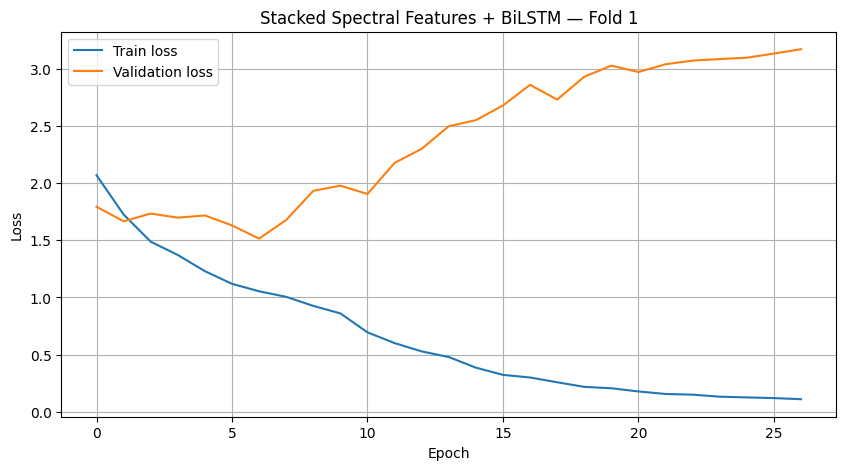

In [ ]:
# Loss
plt.figure(figsize=(10, 5))

plt.plot(
    history_fold_1['train_loss'],
    label='Train loss'
)

plt.plot(
    history_fold_1['val_loss'],
    label='Validation loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title(
    'Stacked Spectral Features + BiLSTM — Fold 1'
)

plt.legend()
plt.grid()

plt.show()

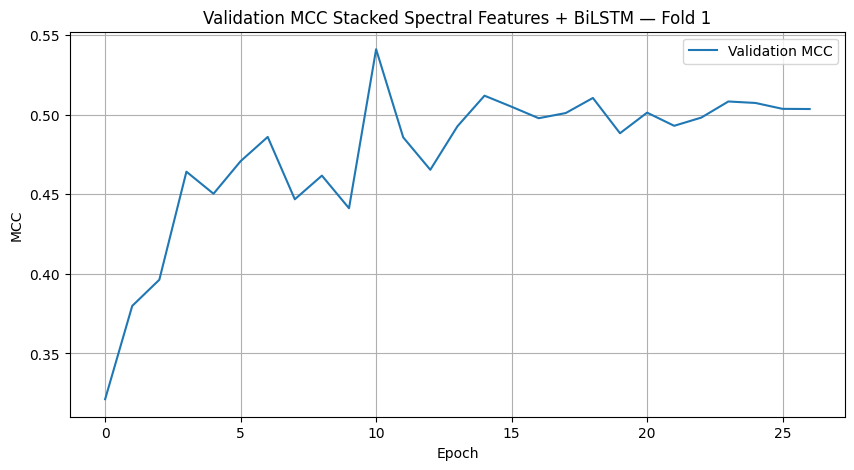

In [ ]:
# MCC
plt.figure(figsize=(10, 5))

plt.plot(
    history_fold_1['val_mcc'],
    label='Validation MCC'
)

plt.xlabel('Epoch')
plt.ylabel('MCC')
plt.title(
    'Validation MCC Stacked Spectral Features + BiLSTM — Fold 1'
)

plt.legend()
plt.grid()

plt.show()

In [ ]:
result = pd.concat([df_grade_mean_ml, df_grade_mean_cnn, df_grade_mean_resnet, df_grade_mean_transformer,df_grade_mean_lstm],ignore_index=True)
result.index = result.index + 1
result

,model,accuracy_mean,accuracy_std,f1_mean,f1_std,mcc_mean,mcc_std
1,Logistic Regression,0.6246,0.0507,0.6351,0.0535,0.5809,0.0567
2,Random Forest,0.6613,0.0212,0.6691,0.0228,0.6228,0.0242
3,SVM,0.6586,0.0587,0.6667,0.0625,0.6202,0.0648
4,CNN,0.5449,0.0535,0.5549,0.0596,0.4950,0.0601
5,ResNet,0.6601,0.0663,0.6641,0.0686,0.6237,0.0740
6,CNN+Transformer,0.6764,0.0599,0.6919,0.0500,0.6405,0.0667
7,SSF + BiLSTM,0.6077,0.0512,0.6186,0.0529,0.5635,0.0573


In [ ]:
# Расставим по местам
result_place = result.sort_values(by='mcc_mean', ascending=False).reset_index(drop=True)
result_place.index = result_place.index + 1
result_place

,model,accuracy_mean,accuracy_std,f1_mean,f1_std,mcc_mean,mcc_std
1,CNN+Transformer,0.6764,0.0599,0.6919,0.0500,0.6405,0.0667
2,ResNet,0.6601,0.0663,0.6641,0.0686,0.6237,0.0740
3,Random Forest,0.6613,0.0212,0.6691,0.0228,0.6228,0.0242
4,SVM,0.6586,0.0587,0.6667,0.0625,0.6202,0.0648
5,Logistic Regression,0.6246,0.0507,0.6351,0.0535,0.5809,0.0567
6,SSF + BiLSTM,0.6077,0.0512,0.6186,0.0529,0.5635,0.0573
7,CNN,0.5449,0.0535,0.5549,0.0596,0.4950,0.0601


# 10. Обучим финальную модель (выбираем лучшую, "CNN+Transformer") для дальнейшего применения на новых WAV

для финального обучения на всех данных мы не используем early stopping

In [ ]:
# Загружаем данные
X_mel_delta = np.load('/content/X_mel_delta.npy')

y_mel_delta = np.load('/content/y_mel_delta.npy')

mel_delta_metadata = pd.read_csv('/content/UrbanSound8K_mel_delta_metadata.csv')

print('X:', X_mel_delta.shape)
print('y:', y_mel_delta.shape)
print('metadata:', mel_delta_metadata.shape)

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [ ]:
# Dataset
class UrbanSoundDataset(Dataset):

    def __init__(self, X, y, augment=False):
        self.X = X
        self.y = y
        self.augment = augment

    def __len__(self):
        return len(self.X)


    def __getitem__(self, index):

        x = torch.tensor(
            self.X[index],
            dtype=torch.float32
        )

        y = torch.tensor(
            self.y[index],
            dtype=torch.long
        )

        # ====================================================
        # SpecAugment
        # ====================================================

        if self.augment:

            # -----------------------------------------------
            # Time masking
            # -----------------------------------------------

            time_mask = np.random.randint(0, 30)

            if time_mask > 0:

                time_start = np.random.randint(
                    0,
                    x.shape[-1] - time_mask + 1
                )

                x[
                    :,
                    :,
                    time_start:time_start + time_mask
                ] = 0


            # -----------------------------------------------
            # Frequency masking
            # -----------------------------------------------

            freq_mask = np.random.randint(0, 15)

            if freq_mask > 0:

                freq_start = np.random.randint(
                    0,
                    x.shape[-2] - freq_mask + 1
                )

                x[
                    :,
                    freq_start:freq_start + freq_mask,
                    :
                ] = 0


        return x, y

In [ ]:
# Создаём Dataset на всех 8732 файлах
final_dataset = UrbanSoundDataset(X_mel_delta, y_mel_delta, augment=True)

print("Количество файлов:", len(final_dataset))

Количество файлов: 8732


In [ ]:
# DataLoader
final_loader = DataLoader(
    final_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [ ]:
# Финальная CNN + Transformer
class CNNTransformer(nn.Module):

    def __init__(
        self,
        num_classes=10,
        d_model=128,
        nhead=4,
        num_layers=2,
        dim_feedforward=256,
        dropout=0.2
    ):
        super().__init__()


        # ====================================================
        # CNN
        # ====================================================

        self.cnn = nn.Sequential(

            # Block 1
            nn.Conv2d(
                3,
                32,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(
                32,
                32,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.MaxPool2d(2),


            # Block 2
            nn.Conv2d(
                32,
                64,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(
                64,
                64,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.MaxPool2d(2),


            # Block 3
            nn.Conv2d(
                64,
                128,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.Conv2d(
                128,
                128,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.MaxPool2d(2)
        )


        # ====================================================
        # CNN → Transformer
        # ====================================================

        self.projection = nn.Linear(
            128 * 16,
            d_model
        )


        # ====================================================
        # Positional Encoding
        # ====================================================

        self.positional_encoding = nn.Parameter(
            torch.zeros(
                1,
                32,
                d_model
            )
        )


        # ====================================================
        # Transformer Encoder
        # ====================================================

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            activation='gelu',
            batch_first=True,
            norm_first=True
        )


        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )


        # ====================================================
        # Classifier
        # ====================================================

        self.classifier = nn.Sequential(

            nn.LayerNorm(d_model),

            nn.Linear(
                d_model,
                64
            ),

            nn.GELU(),

            nn.Dropout(0.3),

            nn.Linear(
                64,
                num_classes
            )
        )


    def forward(self, x):

        # [B, 3, 128, 256]
        x = self.cnn(x)

        # [B, 128, 16, 32]

        x = x.permute(
            0,
            3,
            1,
            2
        )

        # [B, 32, 128, 16]

        x = x.reshape(
            x.size(0),
            x.size(1),
            -1
        )

        # [B, 32, 2048]

        x = self.projection(x)

        # [B, 32, 128]

        x = x + self.positional_encoding

        x = self.transformer(x)

        # [B, 32, 128]

        x = x.mean(dim=1)

        # [B, 128]

        x = self.classifier(x)

        # [B, 10]

        return x

In [ ]:
# Создаём финальную модель
final_model = CNNTransformer(
    num_classes=10,
    d_model=128,
    nhead=4,
    num_layers=2,
    dim_feedforward=256,
    dropout=0.2
).to(device)

In [ ]:
# Веса классов
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_mel_delta),
    y=y_mel_delta
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)


print("Class weights:")
print(class_weights)

Class weights:
tensor([0.8732, 2.0354, 0.8732, 0.8732, 0.8732, 0.8732, 2.3348, 0.8732, 0.9399,
        0.8732], device='cuda:0')


In [ ]:
# Loss
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

In [ ]:
# Optimizer
optimizer = torch.optim.AdamW(
    final_model.parameters(),
    lr=0.0005,
    weight_decay=1e-4
)

In [ ]:
# Обучение финальной модели
EPOCHS = 80

for epoch in range(EPOCHS):

    final_model.train()

    epoch_loss = 0.0


    for X_batch, y_batch in final_loader:

        X_batch = X_batch.to(
            device,
            non_blocking=True
        )

        y_batch = y_batch.to(
            device,
            non_blocking=True
        )

        # -----------------------------------------------
        # Обнуляем градиенты
        # -----------------------------------------------

        optimizer.zero_grad()

        # -----------------------------------------------
        # Forward
        # -----------------------------------------------

        outputs = final_model(X_batch)

        # -----------------------------------------------
        # Loss
        # -----------------------------------------------

        loss = criterion(outputs, y_batch)

        # -----------------------------------------------
        # Backpropagation
        # -----------------------------------------------

        loss.backward()

        # -----------------------------------------------
        # Обновляем веса
        # -----------------------------------------------

        optimizer.step()

        epoch_loss += (loss.item() * X_batch.size(0))

    epoch_loss /= len(final_dataset)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Loss: {epoch_loss:.4f}"
    )

Epoch 01/80 | Loss: 2.2633
Epoch 02/80 | Loss: 2.0867
Epoch 03/80 | Loss: 1.9514
Epoch 04/80 | Loss: 1.7603
Epoch 05/80 | Loss: 1.5820
Epoch 06/80 | Loss: 1.4325
Epoch 07/80 | Loss: 1.2968
Epoch 08/80 | Loss: 1.2242
Epoch 09/80 | Loss: 1.1620
Epoch 10/80 | Loss: 1.1180
Epoch 11/80 | Loss: 1.0677
Epoch 12/80 | Loss: 1.0064
Epoch 13/80 | Loss: 0.9527
Epoch 14/80 | Loss: 0.9351
Epoch 15/80 | Loss: 0.8877
Epoch 16/80 | Loss: 0.8340
Epoch 17/80 | Loss: 0.8027
Epoch 18/80 | Loss: 0.7717
Epoch 19/80 | Loss: 0.7293
Epoch 20/80 | Loss: 0.7012
Epoch 21/80 | Loss: 0.6461
Epoch 22/80 | Loss: 0.6048
Epoch 23/80 | Loss: 0.5937
Epoch 24/80 | Loss: 0.5517
Epoch 25/80 | Loss: 0.5092
Epoch 26/80 | Loss: 0.4677
Epoch 27/80 | Loss: 0.4402
Epoch 28/80 | Loss: 0.4466
Epoch 29/80 | Loss: 0.4060
Epoch 30/80 | Loss: 0.3614
Epoch 31/80 | Loss: 0.3716
Epoch 32/80 | Loss: 0.3493
Epoch 33/80 | Loss: 0.2987
Epoch 34/80 | Loss: 0.2939
Epoch 35/80 | Loss: 0.2834
Epoch 36/80 | Loss: 0.2481
Epoch 37/80 | Loss: 0.2429
E

In [ ]:
# Сохраняем финальную модель
FINAL_MODEL_PATH = ("/content/cnn_transformer_final.pt")

torch.save(final_model.state_dict(), FINAL_MODEL_PATH)

print(f"Модель сохранена: {FINAL_MODEL_PATH}")

Модель сохранена: /content/cnn_transformer_final.pt


In [ ]:
# И сохранить checkpoint с архитектурой и параметрами
checkpoint = {

    "model_state_dict":
        final_model.state_dict(),

    "num_classes":
        10,

    "d_model":
        128,

    "nhead":
        4,

    "num_layers":
        2,

    "dim_feedforward":
        256,

    "dropout":
        0.2,

    "sample_rate":
        22050,

    "n_mels":
        128,

    "n_fft":
        2048,

    "hop_length":
        512,

    "target_height":
        128,

    "target_width":
        256,

    "class_names": [
        'air_conditioner',
        'car_horn',
        'children_playing',
        'dog_bark',
        'drilling',
        'engine_idling',
        'gun_shot',
        'jackhammer',
        'siren',
        'street_music'
    ]
}


torch.save(
    checkpoint,
    "/content/cnn_transformer_final_checkpoint.pt"
)

print(
    "Полный checkpoint сохранён."
)

Полный checkpoint сохранён.


In [ ]:
# Проверяем, что модель загружается
checkpoint = torch.load(
    "/content/cnn_transformer_final_checkpoint.pt",
    map_location=device
)

loaded_model = CNNTransformer(
    num_classes=checkpoint["num_classes"],
    d_model=checkpoint["d_model"],
    nhead=checkpoint["nhead"],
    num_layers=checkpoint["num_layers"],
    dim_feedforward=checkpoint["dim_feedforward"],
    dropout=checkpoint["dropout"]
).to(device)

loaded_model.load_state_dict(
    checkpoint["model_state_dict"]
)

loaded_model.eval()

print("Финальная модель успешно загружена.")

Финальная модель успешно загружена.
